# **Project Name**    - Customer Satisfaction (CSAT) Prediction for Shopzilla with a Deep Learning ANN

##### **Project Type**    - Classification (deep learning ANN: CSAT score 1-5 and a low-CSAT alert)
##### **Contribution**    - Individual
##### **Team Member 1 -** Taha Saifee

# **Project Summary -**

This project predicts the customer satisfaction (CSAT) score of Shopzilla's customer support contacts with a deep learning model. The data has 85,907 contacts from August 2023 with the channel, the issue category and sub-category, the times the issue was reported and answered, the agent and their team, the order and product details for some contacts, the customer's written remark for one third of them, and the CSAT score from 1 to 5.

The data needed careful cleaning. There were no duplicates, but many columns are mostly empty (city, product and price in 80% of rows, remarks in 66.5%, handling time in 99.7%), and the gaps carry information: contacts with a product or a remark get more low scores. I filled them with "Unknown" categories or zeros plus flags. 3,128 contacts had a negative response time. All of them were replies saved at midnight without a time, almost all on 28 August, so I marked them as unknown instead of using wrong numbers. All of this, and the cleaning of the remark text (contractions, punctuation, a short stop list that keeps "not", short forms, stemming), is in one file, csat_features.py, which is shared by the notebook and the deployed app.

The analysis showed that the scores are polarised: 69.4% are a 5 and 13.1% a 1, so 14.6% of the customers are unhappy (1 or 2). The strongest pattern is the response time: 8.9% of the customers answered within 5 minutes give a low score, against 36.1% of those who wait more than a day. Email (23.2% low scores), process failures like a technician visit or a seller cancellation (over 30%), expensive orders and agents in training are the other risk factors, and the agents and supervisors differ a lot. Hypothesis tests confirmed the effects of the response time, the channel and the agent tenure.

Because the remark only exists after the survey, I built two models. ML Model 1 is the baseline: the majority class and a logistic regression. ML Model 2 is a real-time ANN that uses only what is known during the contact. ML Model 3 adds a text branch for the remark. Both networks use entity embeddings for the categories (an agent becomes 24 learned numbers instead of 1,371 columns), dense layers with batch normalisation and dropout, and a softmax over the five scores. They are trained with mini-batches, early stopping and a learning rate that halves on plateaus. They were tuned with a random search, and the remarks model was checked with 5-fold cross-validation (ROC-AUC 0.810 +- 0.002).

On the test rows, the real-time ANN ranks unhappy customers with a ROC-AUC of 0.725 and a PR-AUC of 0.331, better than the logistic regression (0.720 and 0.317). With the remarks the ANN reaches 0.808 and 0.534 and a QWK of 0.407, at the same level as the logistic regression. The model finds the clearly unhappy customers but can't tell the rare middle scores apart. The real-time alert flags 29% of contacts and catches 57% of the unhappy customers, and the remarks alert is right half of the time. A check on the last week of August showed that the models hold up but need clean response times and regular retraining.

Permutation importance and a what-if analysis show that the remark, the response time, the sub-category, the agent and the price drive the predictions. Answering within 5 minutes instead of an hour lowers the predicted share of unhappy customers by about 8 points. Finally, I deployed both models in a local Streamlit app that scores single contacts or whole csv files and shows the insights.

# **GitHub Link -**

https://github.com/Tahascommit/ecommerce-csat-ann

# **Problem Statement**


**Shopzilla's customer support team handles thousands of contacts a day by phone, outbound calls and email. After each contact the customer can rate the service from 1 to 5 (CSAT). The score arrives only after the survey, most customers who are unhappy only say so then, and by that time the chance to fix their problem is gone. Surveys also cover only the customers who answer them.**

**The goal of this project is to predict the CSAT score of a support contact with a deep learning model (an artificial neural network) from the interaction itself: the channel, the type of issue, the response time, the agent and their team, the order and product details and, when it exists, the customer's written remark. The model should also flag the contacts that are likely to get a low score (1 or 2) so the team can act early, and the analysis should show which parts of the service drive satisfaction. The final model is deployed as a local web app for ongoing predictions.**

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required. 
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits. 
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule. 

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

### How this notebook covers the project objectives

| Objective | Where to find it |
|---|---|
| Data preparation: cleaning, missing values, duplicates, timestamps | Sections 1 to 3, 6.1 and 6.2 |
| Feature engineering and selection | Section 3 (shared feature code), 6.3 to 6.5 |
| Text preprocessing of the customer remarks | Section 6.4 (steps 1 to 10) |
| Model development: ANN design and training | ML Models 2 and 3 |
| Evaluation and validation | every ML model, cross-validation, error analysis, time-based check |
| Insight generation | charts 1 to 15, hypothesis tests, permutation importance, what-if analysis, section 7.1 |
| Local deployment | section 7.2, Future Work and the Streamlit app in `app/` |

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os
import re
import sys
import json
import time
import warnings
import importlib
import subprocess
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score, mean_absolute_error, roc_auc_score,
                             average_precision_score, confusion_matrix, precision_score, recall_score,
                             precision_recall_curve)

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"          # hide TensorFlow start-up and tf.data log messages
import tensorflow as tf
import keras
from keras import layers
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)   # hide the retracing notes printed while many models are trained

try:
    import nltk
except ImportError:                                # nltk is on Colab already, install it only if it is missing
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nltk"], check=True)
    import nltk

warnings.filterwarnings("ignore")
SEED = 42
keras.utils.set_random_seed(SEED)                  # same weights and shuffling on every run
if not tf.config.list_physical_devices("GPU"):
    tf.config.experimental.enable_op_determinism()  # fully repeatable training on CPU
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
CSAT_COLORS = ["#C44E52", "#DD8452", "#CCB974", "#8FBF6F", "#55A868"]   # score 1 (red) to 5 (green)
os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("models", exist_ok=True)


def save_fig(fig, name):
    """Save a chart to outputs/figures, so the README and the app can use it."""
    fig.savefig(f"outputs/figures/{name}.png", dpi=110, bbox_inches="tight")


print("tensorflow", tf.__version__, "| keras", keras.__version__, "| pandas", pd.__version__, "| nltk", nltk.__version__)

tensorflow 2.21.0 | keras 3.15.1 | pandas 2.3.3 | nltk 3.10.4


### Dataset Loading

In [2]:
# Load Dataset
# the csv is in the repo's data folder; on Colab (no local copy) it is read from GitHub
LOCAL_PATH = "data/eCommerce_Customer_support_data.csv"
GITHUB_PATH = "https://raw.githubusercontent.com/Tahascommit/ecommerce-csat-ann/main/data/eCommerce_Customer_support_data.csv"


def read_data():
    path = LOCAL_PATH if os.path.exists(LOCAL_PATH) else GITHUB_PATH
    try:
        return pd.read_csv(path), path
    except Exception as e:
        raise RuntimeError(f"could not read {path}: {e}")


raw, source = read_data()
print("data read from:", "local data folder" if source == LOCAL_PATH else "GitHub")

data read from: local data folder


### Dataset First View

In [3]:
# Dataset First Look
raw.head()

,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,connected_handling_time,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,NaN,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaN,01/08/2023 11:13,01/08/2023 11:47,01-Aug-23,NaN,NaN,NaN,NaN,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,NaN,d406b0c7-ce17-4654-b9de-f08d421254bd,NaN,01/08/2023 12:52,01/08/2023 12:54,01-Aug-23,NaN,NaN,NaN,NaN,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,NaN,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaN,01/08/2023 20:16,01/08/2023 20:38,01-Aug-23,NaN,NaN,NaN,NaN,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,NaN,5aed0059-55a4-4ec6-bb54-97942092020a,NaN,01/08/2023 20:56,01/08/2023 21:16,01-Aug-23,NaN,NaN,NaN,NaN,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,NaN,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaN,01/08/2023 10:30,01/08/2023 10:32,01-Aug-23,NaN,NaN,NaN,NaN,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
print(f"rows: {raw.shape[0]:,}  columns: {raw.shape[1]}")

rows: 85,907  columns: 20


### Dataset Information

In [5]:
# Dataset Info
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85907 entries, 0 to 85906
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unique id                85907 non-null  object 
 1   channel_name             85907 non-null  object 
 2   category                 85907 non-null  object 
 3   Sub-category             85907 non-null  object 
 4   Customer Remarks         28742 non-null  object 
 5   Order_id                 67675 non-null  object 
 6   order_date_time          17214 non-null  object 
 7   Issue_reported at        85907 non-null  object 
 8   issue_responded          85907 non-null  object 
 9   Survey_response_Date     85907 non-null  object 
 10  Customer_City            17079 non-null  object 
 11  Product_category         17196 non-null  object 
 12  Item_price               17206 non-null  float64
 13  connected_handling_time  242 non-null    float64
 14  Agent_name            

#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
print("fully duplicated rows:", raw.duplicated().sum())
print("duplicated Unique id:", raw["Unique id"].duplicated().sum())
print("duplicated Order_id (among the filled ones):", raw["Order_id"].dropna().duplicated().sum())
print("same interaction twice (every column except the id):", raw.drop(columns="Unique id").duplicated().sum())

fully duplicated rows: 0
duplicated Unique id: 0
duplicated Order_id (among the filled ones): 0


same interaction twice (every column except the id): 1


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
missing = pd.DataFrame({"missing": raw.isna().sum(), "missing %": raw.isna().mean().mul(100).round(1)})
missing[missing["missing"] > 0].sort_values("missing", ascending=False)

,missing,missing %
connected_handling_time,85665,99.7
Customer_City,68828,80.1
Product_category,68711,80.0
Item_price,68701,80.0
order_date_time,68693,80.0
Customer Remarks,57165,66.5
Order_id,18232,21.2


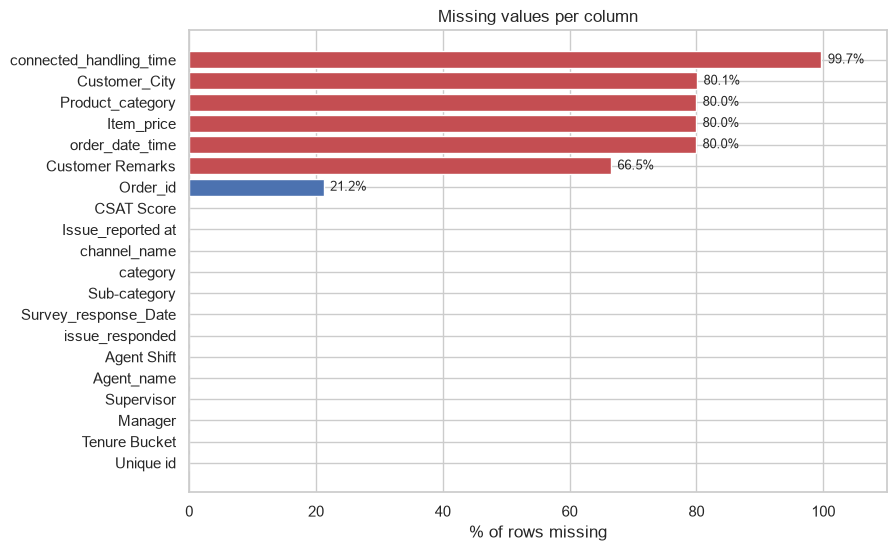

share of rows WITH the value, by CSAT score:
CSAT Score            1      2      3      4      5
Customer Remarks  0.476  0.307  0.285  0.232  0.330
Order_id          0.809  0.806  0.805  0.788  0.783
Item_price        0.300  0.259  0.222  0.194  0.181
Customer_City     0.298  0.259  0.222  0.193  0.179


In [8]:
# Visualizing the missing values
miss = raw.isna().mean().mul(100).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(miss.index, miss.values, color=["#C44E52" if v > 50 else "#4C72B0" if v > 0 else "#BBBBBB" for v in miss.values])
for i, v in enumerate(miss.values):
    if v > 0:
        ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values per column")
ax.set_xlim(0, 110)
save_fig(fig, "00_missing_values")
plt.show()

# is the missingness random? share of rows that have the value, per CSAT score
print("share of rows WITH the value, by CSAT score:")
print(raw.drop(columns="CSAT Score").notna().groupby(raw["CSAT Score"]).mean()
      [["Customer Remarks", "Order_id", "Item_price", "Customer_City"]].round(3).T)

### What did you know about your dataset?

The data is one month of customer support contacts of the Shopzilla platform: 85,907 rows and 20 columns. Each row is one contact that got a survey answer, with the channel, the issue category and sub-category, the times the issue was reported and answered, the survey date, the agent with their supervisor, manager, tenure and shift, and for some rows the order, product, city, price and a written remark. The target is the CSAT score from 1 to 5.

What I found:
- There are no duplicated rows or ids. Only one contact appears twice when the id is ignored, so I kept it.
- The score is very unbalanced: 69.4% of the surveys are a 5 and 13.1% a 1, while 2 and 3 together are only 4.5%.
- Many columns are mostly empty: the handling time is missing in 99.7% of rows, the city, product category, price and order date in about 80%, the remark in 66.5% and the order id in 21.2%. These gaps are not random. Rows with a price or a remark get more low scores (a price is filled in 30% of the CSAT 1 rows and 18% of the CSAT 5 rows), so whether a value exists is information in itself.
- The dates are text in two formats (day/month/year with time, and 01-Aug-23).
- The ids (Unique id and Order_id) are random codes and carry no information.

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns
list(raw.columns)

['Unique id',
 'channel_name',
 'category',
 'Sub-category',
 'Customer Remarks',
 'Order_id',
 'order_date_time',
 'Issue_reported at',
 'issue_responded',
 'Survey_response_Date',
 'Customer_City',
 'Product_category',
 'Item_price',
 'connected_handling_time',
 'Agent_name',
 'Supervisor',
 'Manager',
 'Tenure Bucket',
 'Agent Shift',
 'CSAT Score']

In [10]:
# Dataset Describe
raw.describe(include="all").T[["count", "unique", "top", "freq", "mean", "std", "min", "max"]]

,count,unique,top,freq,mean,std,min,max
Unique id,85907,85907,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,1,NaN,NaN,NaN,NaN
channel_name,85907,3,Inbound,68142,NaN,NaN,NaN,NaN
category,85907,12,Returns,44097,NaN,NaN,NaN,NaN
Sub-category,85907,57,Reverse Pickup Enquiry,22389,NaN,NaN,NaN,NaN
Customer Remarks,28742,18231,Good,1390,NaN,NaN,NaN,NaN
Order_id,67675,67675,c27c9bb4-fa36-4140-9f1f-21009254ffdb,1,NaN,NaN,NaN,NaN
order_date_time,17214,13766,09/08/2023 11:55,7,NaN,NaN,NaN,NaN
Issue_reported at,85907,30923,15/08/2023 10:59,13,NaN,NaN,NaN,NaN
issue_responded,85907,30262,28/08/2023 00:00,3378,NaN,NaN,NaN,NaN
Survey_response_Date,85907,31,28-Aug-23,3452,NaN,NaN,NaN,NaN


### Variables Description 

| Column | Meaning |
|---|---|
| Unique id | id of the support contact |
| channel_name | Inbound call, Outcall or Email |
| category | type of issue (12 values, for example Returns, Order Related, Refund Related) |
| Sub-category | detailed issue type (57 values, for example Reverse Pickup Enquiry, Delayed) |
| Customer Remarks | text the customer wrote in the survey (often empty) |
| Order_id | id of the order the contact is about |
| order_date_time | when the order was placed |
| Issue_reported at | when the customer reported the issue |
| issue_responded | when the agent first responded |
| Survey_response_Date | day the customer answered the survey |
| Customer_City | city of the customer |
| Product_category | product type of the order (9 values) |
| Item_price | price of the item |
| connected_handling_time | time the agent spent on the contact (almost always empty) |
| Agent_name | agent who handled the contact (1,371 agents) |
| Supervisor | the agent's supervisor (40) |
| Manager | the supervisor's manager (6) |
| Tenure Bucket | how long the agent has worked there: On Job Training, 0-30, 31-60, 61-90 or more than 90 days |
| Agent Shift | Morning, Afternoon, Evening, Night or Split |
| CSAT Score | customer satisfaction from 1 (very unhappy) to 5 (very happy), the target |

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable.
uniq = raw.nunique().sort_values()
print(uniq.to_string())
for c in ["channel_name", "Tenure Bucket", "Agent Shift", "Manager", "Product_category"]:
    print(f"\n{c}: {sorted(raw[c].dropna().unique())}")

channel_name                   3
CSAT Score                     5
Tenure Bucket                  5
Agent Shift                    5
Manager                        6
Product_category               9
category                      12
Survey_response_Date          31
Supervisor                    40
Sub-category                  57
connected_handling_time      211
Agent_name                  1371
Customer_City               1782
Item_price                  2789
order_date_time            13766
Customer Remarks           18231
issue_responded            30262
Issue_reported at          30923
Order_id                   67675
Unique id                  85907

channel_name: ['Email', 'Inbound', 'Outcall']

Tenure Bucket: ['0-30', '31-60', '61-90', '>90', 'On Job Training']

Agent Shift: ['Afternoon', 'Evening', 'Morning', 'Night', 'Split']

Manager: ['Emily Chen', 'Jennifer Nguyen', 'John Smith', 'Michael Lee', 'Olivia Tan', 'William Kim']

Product_category: ['Affiliates', 'Books & General mer

## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
%%writefile csat_features.py
# Feature code shared by the notebook and the Streamlit app.
# The notebook writes this file, so training and deployment prepare the data in exactly the same way.
import re

import numpy as np
import pandas as pd
from nltk.stem import PorterStemmer

# model inputs
CAT_COLS = ["channel_name", "category", "Sub-category", "Customer_City", "Product_category", "Agent_name",
            "Supervisor", "Manager", "Tenure Bucket", "Agent Shift", "Reported_Weekday"]
NUM_REALTIME = ["Response_Log_Min", "Response_Unknown", "Hour_Sin", "Hour_Cos", "Has_Order_Id",
                "Order_Age_Log_Days", "Has_Price", "Price_Log"]
NUM_SURVEY = NUM_REALTIME + ["Survey_Lag_Days", "Remark_Log_Words"]   # only known after the survey
TEXT_COL = "Remark_Clean"
# Keras input names can't have spaces, so every column gets a simple name: "Tenure Bucket" -> "tenure_bucket"
INPUT_NAMES = {c: re.sub(r"[^a-z0-9]+", "_", c.lower()).strip("_") for c in CAT_COLS}

# ---------- text cleaning, one function per step ----------
CONTRACTIONS = {r"won't": "will not", r"can't": "cannot", r"n't": " not", r"'re": " are", r"'s": " is",
                r"'d": " would", r"'ll": " will", r"'ve": " have", r"'m": " am"}
# a short stop list of function words only: the standard lists also drop "not", "never", "keep", "well" and "done",
# which carry the customer's opinion in remarks like "not resolved" or "keep it up"
STOP_WORDS = {"a", "an", "the", "is", "are", "was", "were", "be", "been", "being", "am", "to", "of", "for", "in", "on",
              "at", "by", "with", "and", "or", "as", "from", "about", "into", "this", "that", "these", "those", "it",
              "its", "i", "me", "my", "we", "our", "you", "your", "u", "ur", "he", "him", "his", "she", "her", "they",
              "them", "their", "do", "does", "did", "have", "has", "had", "will", "would", "shall", "should", "can",
              "could", "may", "might", "so", "there", "here", "also", "just", "sir", "mam", "maam", "madam", "dear"}
SHORT_FORMS = {"pls": "please", "plz": "please", "thx": "thanks", "thnx": "thanks", "thanku": "thank you",
               "thankyou": "thank you", "tq": "thank you", "ty": "thank you", "gud": "good", "gd": "good",
               "nt": "not", "nhi": "not", "nahi": "not", "ok": "okay", "k": "okay", "nyc": "nice", "issu": "issue",
               "slove": "solve", "solv": "solve", "excelent": "excellent", "servic": "service", "custmer": "customer"}
STEMMER = PorterStemmer()


def expand_contractions(t):
    for short, full in CONTRACTIONS.items():
        t = re.sub(short, full, t, flags=re.IGNORECASE)
    return t


def lower_case(t):
    return t.lower()


def remove_punctuation(t):
    return re.sub(r"[^\w\s]|_", " ", t)                        # also removes the '??' left where emojis were


def remove_urls_and_digit_words(t):
    t = re.sub(r"\b(?:https?|www|com)\b", " ", t)               # pieces of a link left after removing punctuation
    return re.sub(r"\b\w*\d\w*\b", " ", t)


def remove_stopwords(t):
    return " ".join(w for w in t.split() if w not in STOP_WORDS)   # split/join also removes extra white space


def rephrase(t):
    t = re.sub(r"(\w)\1{2,}", r"\1\1", t)                       # goooood -> good, sooo -> soo
    return " ".join(SHORT_FORMS.get(w, w) for w in t.split())


def tokenize(t):
    return re.findall(r"[a-z]+", t)


def stem(tokens):
    return [STEMMER.stem(w) for w in tokens if len(w) > 1]


def clean_remark(text):
    """Customer remark -> cleaned, stemmed tokens joined by spaces ('' when there is no remark)."""
    if not isinstance(text, str) or not text.strip():
        return ""
    t = remove_stopwords(remove_urls_and_digit_words(remove_punctuation(lower_case(expand_contractions(text)))))
    return " ".join(stem(tokenize(rephrase(t))))


# ---------- features ----------
def parse_dates(df):
    """Parse the four date columns of the raw file (day first)."""
    out = pd.DataFrame(index=df.index)
    out["Reported"] = pd.to_datetime(df["Issue_reported at"], format="%d/%m/%Y %H:%M", errors="coerce")
    out["Responded"] = pd.to_datetime(df["issue_responded"], format="%d/%m/%Y %H:%M", errors="coerce")
    out["Survey"] = pd.to_datetime(df["Survey_response_Date"], format="%d-%b-%y", errors="coerce")
    out["Ordered"] = pd.to_datetime(df["order_date_time"], format="%d/%m/%Y %H:%M", errors="coerce")
    return out


def make_features(df):
    """Raw Shopzilla rows -> model inputs (categorical strings, numbers and the cleaned remark)."""
    d = parse_dates(df)
    f = pd.concat([df[c].fillna("Unknown").astype(str).str.strip().rename(c) for c in CAT_COLS[:-1]], axis=1)
    f["Customer_City"] = f["Customer_City"].str.upper()
    f["Reported_Weekday"] = d["Reported"].dt.day_name().fillna("Unknown")
    f = pd.concat([f, d], axis=1)

    # response time: on 28 Aug 2023 the reply was saved at 00:00 without a time, so those are unknown
    minutes = (d["Responded"] - d["Reported"]).dt.total_seconds() / 60
    no_time = (d["Responded"].dt.hour == 0) & (d["Responded"].dt.minute == 0)
    unknown = no_time | minutes.isna() | (minutes < 0)
    f["Response_Min"] = minutes.where(~unknown)
    f["Response_Unknown"] = unknown.astype(int)
    f["Response_Log_Min"] = np.log1p(f["Response_Min"].fillna(0))

    hour = d["Reported"].dt.hour.fillna(12)
    f["Reported_Hour"] = hour.astype(int)
    f["Hour_Sin"] = np.sin(2 * np.pi * hour / 24)               # hour as a circle: 23:00 is next to 00:00
    f["Hour_Cos"] = np.cos(2 * np.pi * hour / 24)

    f["Has_Order_Id"] = df["Order_id"].notna().astype(int)
    f["Has_Order_Date"] = d["Ordered"].notna().astype(int)
    age = (d["Reported"] - d["Ordered"]).dt.total_seconds() / 86400
    f["Order_Age_Days"] = age.where(age >= 0)
    f["Order_Age_Log_Days"] = np.log1p(f["Order_Age_Days"].fillna(0))
    price = pd.to_numeric(df["Item_price"], errors="coerce")
    f["Item_Price"] = price
    f["Has_Price"] = price.notna().astype(int)
    f["Price_Log"] = np.log1p(price.clip(lower=0).fillna(0))

    # known only after the customer answers the survey
    f["Survey_Lag_Days"] = (d["Survey"] - d["Reported"].dt.normalize()).dt.days.clip(lower=0).fillna(0)
    remark = df["Customer Remarks"]
    f["Has_Remark"] = (remark.notna() & remark.astype(str).str.strip().ne("")).astype(int)
    f["Remark_Words"] = remark.fillna("").astype(str).str.split().str.len()
    f["Remark_Log_Words"] = np.log1p(f["Remark_Words"])
    f[TEXT_COL] = remark.map(clean_remark)
    return f


def to_tensors(x):
    """Keras takes text inputs only as TensorFlow string tensors, so the text arrays are converted."""
    import tensorflow as tf
    return {k: tf.constant(v.astype(str)) if v.dtype == object else v for k, v in x.items()}


def model_inputs(f, num_cols, with_text, tensors=True):
    """Feature table -> the dict of inputs the Keras model takes (one entry per input layer)."""
    x = {INPUT_NAMES[c]: f[c].astype(str).to_numpy(dtype=object).reshape(-1, 1) for c in CAT_COLS}
    x["numeric"] = f[num_cols].astype("float32").to_numpy()
    if with_text:
        x["remark"] = f[TEXT_COL].astype(str).to_numpy(dtype=object)          # one string per row
    return to_tensors(x) if tensors else x

Overwriting csat_features.py


In [13]:
# load the shared feature code and build the analysis table
import csat_features
importlib.reload(csat_features)                    # pick up the file written above if the cell is run again
from csat_features import (make_features, model_inputs, to_tensors, CAT_COLS, NUM_REALTIME, NUM_SURVEY, TEXT_COL,
                           INPUT_NAMES)

feat = make_features(raw)
df = raw.copy()
for c in feat.columns:                             # cleaned categorical columns replace the raw ones, new ones are added
    df[c] = feat[c]
df["CSAT"] = raw["CSAT Score"]
df["Low_CSAT"] = (df["CSAT"] <= 2).astype(int)     # the alert target: a score of 1 or 2
df["Response_Bucket"] = pd.cut(df["Response_Min"], [-1, 5, 30, 120, 1440, np.inf],
                               labels=["0-5 min", "5-30 min", "30 min-2 h", "2 h-1 day", "over 1 day"])
df["Response_Bucket"] = df["Response_Bucket"].cat.add_categories("unknown").fillna("unknown")

print("analysis table:", df.shape)
print("new columns:", [c for c in df.columns if c not in raw.columns])
unk = df["Response_Unknown"] == 1
print(f"reply saved at 00:00 without a time: {unk.sum():,} rows ({unk.mean():.1%}), "
      f"{(df.loc[unk, 'Responded'].dt.strftime('%Y-%m-%d') == '2023-08-28').mean():.0%} of them on 28 Aug 2023")
print(f"negative response times before the fix: {((df['Responded'] - df['Reported']).dt.total_seconds() < 0).sum():,}")
print(f"issues reported {df['Reported'].min():%d %b %Y} to {df['Reported'].max():%d %b %Y}, "
      f"surveys answered {df['Survey'].min():%d %b} to {df['Survey'].max():%d %b %Y}")
print(f"median response time {df['Response_Min'].median():.0f} min, low CSAT (1-2): {df['Low_CSAT'].mean():.1%}")

analysis table: (85907, 46)
new columns: ['Reported_Weekday', 'Reported', 'Responded', 'Survey', 'Ordered', 'Response_Min', 'Response_Unknown', 'Response_Log_Min', 'Reported_Hour', 'Hour_Sin', 'Hour_Cos', 'Has_Order_Id', 'Has_Order_Date', 'Order_Age_Days', 'Order_Age_Log_Days', 'Item_Price', 'Has_Price', 'Price_Log', 'Survey_Lag_Days', 'Has_Remark', 'Remark_Words', 'Remark_Log_Words', 'Remark_Clean', 'CSAT', 'Low_CSAT', 'Response_Bucket']
reply saved at 00:00 without a time: 3,442 rows (4.0%), 98% of them on 28 Aug 2023
negative response times before the fix: 3,128
issues reported 28 Jul 2023 to 31 Aug 2023, surveys answered 01 Aug to 31 Aug 2023
median response time 6 min, low CSAT (1-2): 14.6%


### What all manipulations have you done and insights you found?

I put all the data preparation into one file, `csat_features.py`, written by the cell above. The notebook uses it here, and the Streamlit app imports the same file, so a contact is prepared exactly the same way in training and in deployment. What it does:
- Parses the four date columns.
- Computes the response time in minutes. 3,128 contacts had a negative response time. All of them have a reply time of exactly 00:00, and 98% are on 28 Aug 2023, so on that day the reply was saved without the time of day. I mark these 3,442 midnight replies as "response time unknown" instead of using a wrong number.
- Adds the hour (as a circle, so 23:00 sits next to 00:00) and the weekday the issue came in.
- Adds flags for an order id and a price, the order age in days and the log of the price.
- Adds the days between the issue and the survey answer and the length of the remark. These are only known after the survey, so they are only used by the model that reads remarks.
- Fills empty categories with "Unknown" and cleans the remark text (the steps are shown one by one in section 6.4).
- For the charts I also added the low-CSAT flag (score 1 or 2) and response time buckets.

First insights: the issues were reported from 28 Jul to 31 Aug 2023 and the surveys answered from 1 to 31 Aug. The median first response comes after 6 minutes, and 14.6% of the customers gave a low score.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - CSAT score distribution

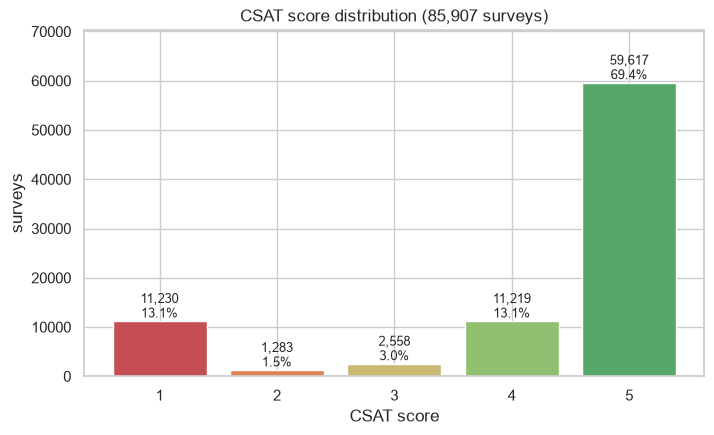

mean CSAT 4.24, median 5, low CSAT (1-2) 14.6%


In [14]:
# Chart - 1 visualization code: how are the CSAT scores spread?
counts = df["CSAT"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(counts.index.astype(str), counts.values, color=CSAT_COLORS)
for b, n in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, n + 700, f"{n:,}\n{n / len(df):.1%}", ha="center", fontsize=9)
ax.set_ylim(0, counts.max() * 1.18)
ax.set_xlabel("CSAT score")
ax.set_ylabel("surveys")
ax.set_title(f"CSAT score distribution ({len(df):,} surveys)")
save_fig(fig, "chart01_csat_distribution")
plt.show()
print(f"mean CSAT {df['CSAT'].mean():.2f}, median {df['CSAT'].median():.0f}, low CSAT (1-2) {df['Low_CSAT'].mean():.1%}")

##### 1. Why did you pick the specific chart?

A bar chart is the clearest way to show how the five scores are spread, and the labels give the exact counts and shares.

##### 2. What is/are the insight(s) found from the chart?

The scores are very polarised. 69.4% of customers gave a 5 and 13.1% a 1, while 2, 3 and 4 are rare (1.5%, 3.0% and 13.1%). The mean score is 4.24. Customers either like the service or are clearly unhappy, and few are in between.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Most customers are satisfied, so the business problem is the 14.6% who give a 1 or 2. Finding those contacts early is more useful than predicting the exact score of the happy ones, so I added a low-CSAT alert next to the score prediction. The negative side is that a model can reach 69% accuracy by always saying 5, which would be useless, so accuracy alone can't be trusted here.

#### Chart - 2 - Contacts and low CSAT per channel

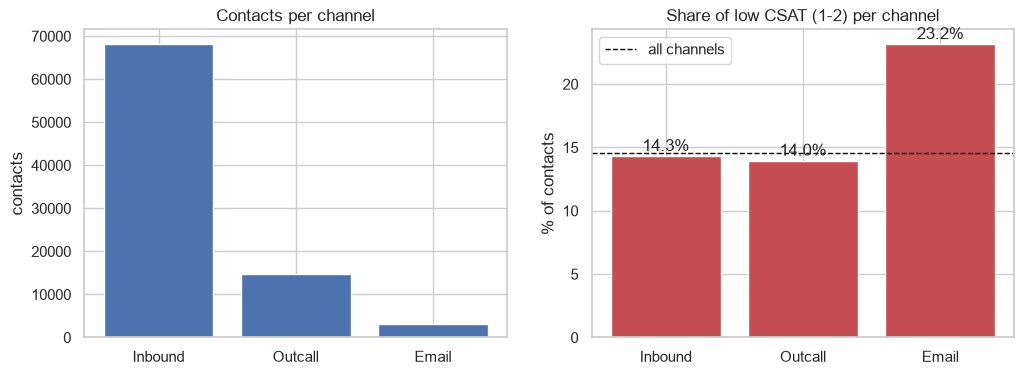

,contacts,mean_csat,low_share
channel_name,,,
Inbound,68142,4.251,0.143
Outcall,14742,4.270,0.140
Email,3023,3.899,0.232


In [15]:
# Chart - 2 visualization code: does the channel matter?
ch = (df.groupby("channel_name").agg(contacts=("CSAT", "size"), mean_csat=("CSAT", "mean"), low_share=("Low_CSAT", "mean"))
      .sort_values("contacts", ascending=False))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(ch.index, ch["contacts"], color="#4C72B0")
axes[0].set_title("Contacts per channel")
axes[0].set_ylabel("contacts")
axes[1].bar(ch.index, ch["low_share"] * 100, color="#C44E52")
axes[1].axhline(df["Low_CSAT"].mean() * 100, ls="--", color="black", lw=1, label="all channels")
for i, v in enumerate(ch["low_share"] * 100):
    axes[1].text(i, v + 0.4, f"{v:.1f}%", ha="center")
axes[1].set_title("Share of low CSAT (1-2) per channel")
axes[1].set_ylabel("% of contacts")
axes[1].legend()
save_fig(fig, "chart02_channel")
plt.show()
ch.round(3)

##### 1. Why did you pick the specific chart?

Two bar charts side by side show the size of each channel and its share of low scores, with the average as a reference line, so a small channel with a problem is still visible.

##### 2. What is/are the insight(s) found from the chart?

Inbound calls are 79% of the contacts (68,142), Outcall 17% and Email only 3.5%. Inbound and Outcall have almost the same share of low scores (14.3% and 14.0%), but Email is much worse at 23.2%. Its mean score is 3.90 against about 4.25 for the phone channels.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Email customers are the least satisfied, probably because email answers are slower and less personal. Faster email replies or offering a call back to email customers could lift satisfaction. The negative insight is that moving more customers to email to save costs would likely lower CSAT.

#### Chart - 3 - Contacts and low CSAT per issue category

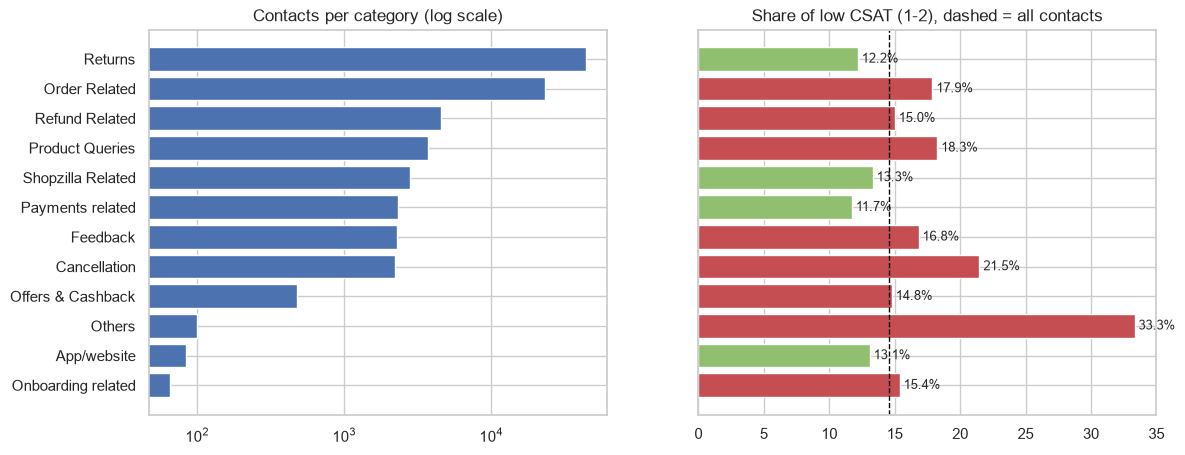

,contacts,mean_csat,low_share
category,,,
Returns,44097,4.346,0.122
Order Related,23215,4.096,0.179
Refund Related,4550,4.227,0.150
Product Queries,3692,4.040,0.183
Shopzilla Related,2792,4.307,0.133
Payments related,2327,4.355,0.117
Feedback,2294,4.159,0.168
Cancellation,2212,3.991,0.215
Offers & Cashback,480,4.210,0.148


In [16]:
# Chart - 3 visualization code: which issue categories make customers unhappy?
cat = (df.groupby("category").agg(contacts=("CSAT", "size"), mean_csat=("CSAT", "mean"), low_share=("Low_CSAT", "mean"))
       .sort_values("contacts"))
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
axes[0].barh(cat.index, cat["contacts"], color="#4C72B0")
axes[0].set_xscale("log")
axes[0].set_title("Contacts per category (log scale)")
axes[1].barh(cat.index, cat["low_share"] * 100,
             color=["#C44E52" if v > df["Low_CSAT"].mean() else "#8FBF6F" for v in cat["low_share"]])
axes[1].axvline(df["Low_CSAT"].mean() * 100, ls="--", color="black", lw=1)
for i, (v, n) in enumerate(zip(cat["low_share"] * 100, cat["contacts"])):
    axes[1].text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
axes[1].set_title("Share of low CSAT (1-2), dashed = all contacts")
save_fig(fig, "chart03_category")
plt.show()
cat.sort_values("contacts", ascending=False).round(3)

##### 1. Why did you pick the specific chart?

A horizontal bar chart fits the 12 long category names. The left panel uses a log scale so that both Returns (44,097) and the tiny categories are readable.

##### 2. What is/are the insight(s) found from the chart?

Returns (51% of contacts) and Order Related (27%) are most of the work. Returns customers are fairly happy (12.2% low scores), while Order Related (17.9%), Product Queries (18.3%) and Cancellation (21.5%) are clearly worse. The small Others category has the highest share (33.3%, but only 99 contacts).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The categories where the customer already has a problem with the order (delays, cancellations, product questions) need the most care, for example senior agents or proactive updates. A negative point is that Order Related issues are both very common and unhappy, so they pull the overall CSAT down the most.

#### Chart - 4 - Sub-categories with the highest share of low CSAT

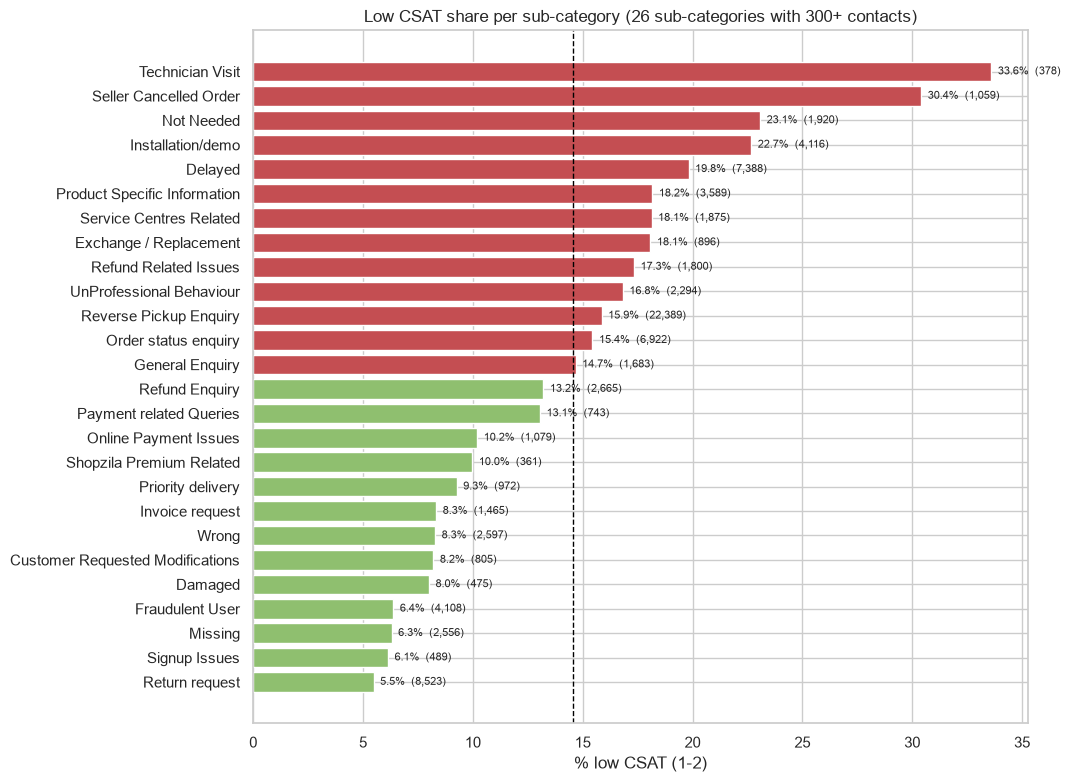

,category,Sub-category,contacts,low_share
50,Returns,Technician Visit,378,0.336
18,Order Related,Seller Cancelled Order,1059,0.304
2,Cancellation,Not Needed,1920,0.231
13,Order Related,Installation/demo,4116,0.227
11,Order Related,Delayed,7388,0.198
34,Product Queries,Product Specific Information,3589,0.182
49,Returns,Service Centres Related,1875,0.181
40,Returns,Exchange / Replacement,896,0.181


In [17]:
# Chart - 4 visualization code: the riskiest sub-categories (with at least 300 contacts)
sub = (df.groupby(["category", "Sub-category"]).agg(contacts=("CSAT", "size"), low_share=("Low_CSAT", "mean"))
       .reset_index().query("contacts >= 300").sort_values("low_share"))
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(sub["Sub-category"], sub["low_share"] * 100,
        color=["#C44E52" if v > df["Low_CSAT"].mean() else "#8FBF6F" for v in sub["low_share"]])
ax.axvline(df["Low_CSAT"].mean() * 100, ls="--", color="black", lw=1)
for i, (v, n) in enumerate(zip(sub["low_share"] * 100, sub["contacts"])):
    ax.text(v + 0.3, i, f"{v:.1f}%  ({n:,})", va="center", fontsize=8)
ax.set_xlabel("% low CSAT (1-2)")
ax.set_title(f"Low CSAT share per sub-category ({len(sub)} sub-categories with 300+ contacts)")
save_fig(fig, "chart04_subcategory")
plt.show()
sub.sort_values("low_share", ascending=False).head(8).round(3)

##### 1. Why did you pick the specific chart?

Sub-categories are too many for one chart, so I kept the 26 with at least 300 contacts and sorted them by the share of low scores. The labels also show the number of contacts.

##### 2. What is/are the insight(s) found from the chart?

The riskiest sub-categories are Technician Visit (33.6% low scores), Seller Cancelled Order (30.4%), Not Needed cancellations (23.1%), Installation/demo (22.7%) and Delayed orders (19.8%). The safest ones are mostly simple Returns questions.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These sub-categories are where Shopzilla's own process failed the customer: the seller cancelled, the technician did not come, or the delivery is late. Fixing those processes will do more for CSAT than agent training. The negative insight is that Delayed alone has 7,388 contacts with almost 20% unhappy customers.

#### Chart - 5 - Response time distribution

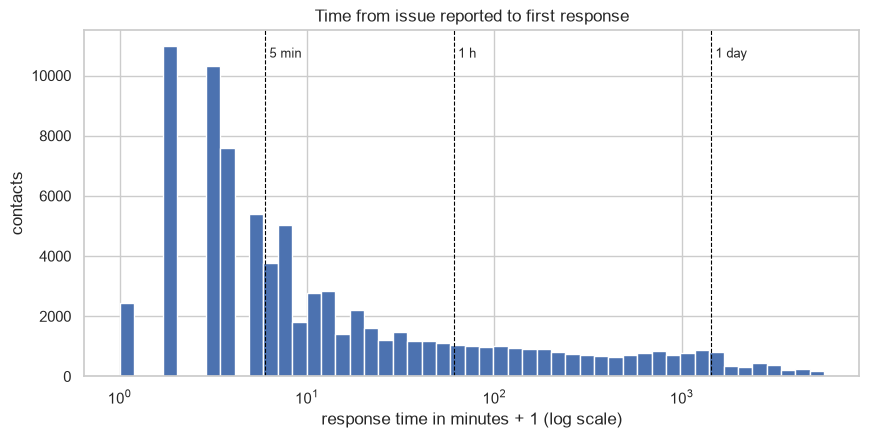

known for 82,465 contacts: median 6 min, mean 173 min, answered within 5 min 49.1%, over 1 day 3.4%, max 4.0 days
unknown (reply saved without a time): 3,442


In [18]:
# Chart - 5 visualization code: how long do customers wait for a reply?
rt = df["Response_Min"].dropna()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(rt + 1, bins=np.logspace(0, np.log10(rt.max() + 1), 50), color="#4C72B0")
ax.set_xscale("log")
for m, label in [(5, "5 min"), (60, "1 h"), (1440, "1 day")]:
    ax.axvline(m + 1, color="black", ls="--", lw=0.8)
    ax.text(m + 1, ax.get_ylim()[1] * 0.92, f" {label}", fontsize=9)
ax.set_xlabel("response time in minutes + 1 (log scale)")
ax.set_ylabel("contacts")
ax.set_title("Time from issue reported to first response")
save_fig(fig, "chart05_response_time")
plt.show()
print(f"known for {len(rt):,} contacts: median {rt.median():.0f} min, mean {rt.mean():.0f} min, "
      f"answered within 5 min {(rt <= 5).mean():.1%}, over 1 day {(rt > 1440).mean():.1%}, max {rt.max() / 1440:.1f} days")
print(f"unknown (reply saved without a time): {df['Response_Unknown'].sum():,}")

##### 1. Why did you pick the specific chart?

Response times go from 0 minutes to 4 days, so a histogram on a log scale is the only way to see the whole spread. The dashed lines mark 5 minutes, 1 hour and 1 day.

##### 2. What is/are the insight(s) found from the chart?

The median response comes after 6 minutes and 49.1% of contacts are answered within 5 minutes, but the tail is long: the mean is 173 minutes, 3.4% wait more than a day and the longest wait is 4 days. 3,442 contacts have an unknown response time (the 28 Aug logging problem).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Most contacts are answered quickly, so the problem is the long tail of slow answers, which is where the next chart shows the unhappy customers are. The negative side is that about one in six contacts with a known response time (16.9%) waits more than 2 hours.

#### Chart - 6 - Low CSAT by response time

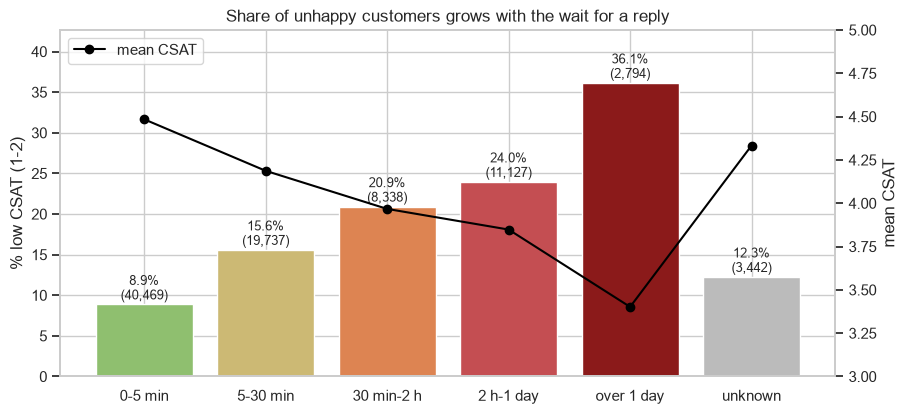

,contacts,mean_csat,low_share
Response_Bucket,,,
0-5 min,40469,4.484,0.089
5-30 min,19737,4.187,0.156
30 min-2 h,8338,3.967,0.209
2 h-1 day,11127,3.848,0.240
over 1 day,2794,3.402,0.361
unknown,3442,4.333,0.123


In [19]:
# Chart - 6 visualization code: does a slow reply lower the score?
rb = df.groupby("Response_Bucket", observed=True).agg(contacts=("CSAT", "size"), mean_csat=("CSAT", "mean"),
                                                       low_share=("Low_CSAT", "mean"))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(rb.index.astype(str), rb["low_share"] * 100, color=["#8FBF6F", "#CCB974", "#DD8452", "#C44E52", "#8B1A1A", "#BBBBBB"])
for i, (v, n) in enumerate(zip(rb["low_share"] * 100, rb["contacts"])):
    ax.text(i, v + 0.6, f"{v:.1f}%\n({n:,})", ha="center", fontsize=9)
ax.set_ylabel("% low CSAT (1-2)")
ax.set_ylim(0, rb["low_share"].max() * 118)
ax2 = ax.twinx()
ax2.plot(rb.index.astype(str), rb["mean_csat"], color="black", marker="o", label="mean CSAT")
ax2.set_ylim(3, 5)
ax2.set_ylabel("mean CSAT")
ax2.grid(False)
ax2.legend(loc="upper left")
ax.set_title("Share of unhappy customers grows with the wait for a reply")
save_fig(fig, "chart06_low_csat_by_response_time")
plt.show()
rb.round(3)

##### 1. Why did you pick the specific chart?

Grouping the response time into buckets and plotting the share of low scores per bucket shows the relationship directly. The line adds the mean score.

##### 2. What is/are the insight(s) found from the chart?

This is the clearest pattern in the data. The share of low scores rises with every step of waiting: 8.9% when the answer comes within 5 minutes, 15.6% for 5-30 minutes, 20.9% for 30 minutes to 2 hours, 24.0% for 2 hours to a day and 36.1% after more than a day. The mean score drops from 4.48 to 3.40. The unknown group behaves like the fast answers (12.3%).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this is the most actionable finding. Answering within 5 minutes instead of after a day cuts the share of unhappy customers by a factor of four. Staffing, queue priorities and service targets can be set with this curve. The negative insight is that every contact that is left waiting for hours is very likely to become a low score.

#### Chart - 7 - Contacts and low CSAT by hour and weekday

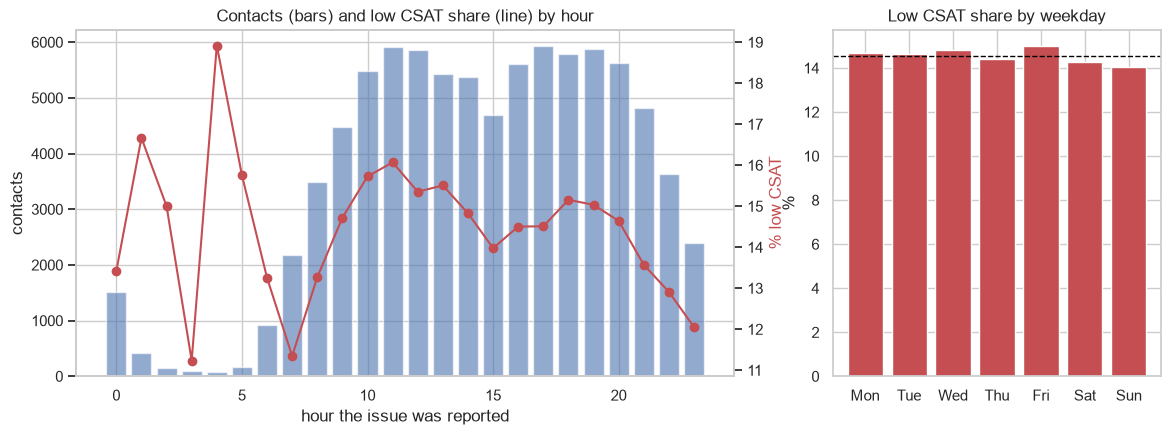

busiest hours: [17, 11, 19] | highest low-CSAT hours (100+ contacts): {1: 0.167, 11: 0.161, 5: 0.158}


,contacts,low_share
Reported_Weekday,,
Monday,12053,0.147
Tuesday,14282,0.146
Wednesday,13633,0.148
Thursday,13803,0.144
Friday,10564,0.150
Saturday,10630,0.143
Sunday,10942,0.141


In [20]:
# Chart - 7 visualization code: when do issues come in, and are some hours worse?
hr = df.groupby("Reported_Hour").agg(contacts=("CSAT", "size"), low_share=("Low_CSAT", "mean"))
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wd = df.groupby("Reported_Weekday").agg(contacts=("CSAT", "size"), low_share=("Low_CSAT", "mean")).reindex(days)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
axes[0].bar(hr.index, hr["contacts"], color="#4C72B0", alpha=0.6)
axes[0].set_xlabel("hour the issue was reported")
axes[0].set_ylabel("contacts")
a2 = axes[0].twinx()
a2.plot(hr.index, hr["low_share"] * 100, color="#C44E52", marker="o")
a2.set_ylabel("% low CSAT", color="#C44E52")
a2.grid(False)
axes[0].set_title("Contacts (bars) and low CSAT share (line) by hour")
axes[1].bar([d[:3] for d in days], wd["low_share"] * 100, color="#C44E52")
axes[1].axhline(df["Low_CSAT"].mean() * 100, ls="--", color="black", lw=1)
axes[1].set_title("Low CSAT share by weekday")
axes[1].set_ylabel("%")
save_fig(fig, "chart07_hour_weekday")
plt.show()
busy = hr.sort_values("contacts", ascending=False).head(3).index.tolist()
print("busiest hours:", busy, "| highest low-CSAT hours (100+ contacts):",
      hr[hr["contacts"] >= 100].sort_values("low_share", ascending=False).head(3)["low_share"].round(3).to_dict())
wd.round(3)

##### 1. Why did you pick the specific chart?

Bars for the number of contacts and a line for the share of low scores per hour show workload and quality together. The weekday panel checks if some days are worse.

##### 2. What is/are the insight(s) found from the chart?

Contacts peak at 11:00, 17:00 and 19:00 and are low at night. The share of low scores changes only a little over the day, from 11.3% at 7:00 to 16.7% at 1:00, and the night hours that are slightly worse have few contacts. The weekdays are almost identical (14.1% to 15.0%).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, mainly as a staffing guide: the busy hours need the most agents so that response times stay short. Because the share of low scores hardly depends on the hour or the day, the time of day is not a big risk factor in itself, as long as the queue is staffed.

#### Chart - 8 - Daily contacts and CSAT in August 2023

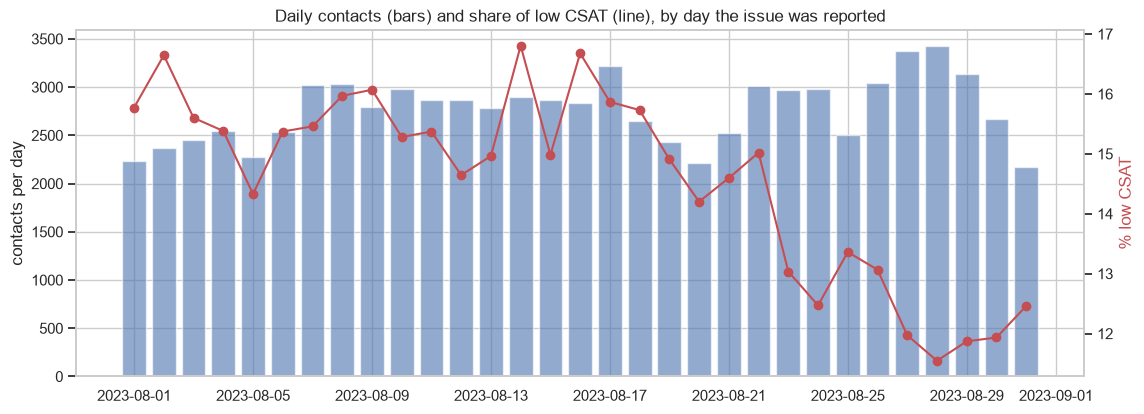

contacts per day: min 2,167, max 3,421; low CSAT share per day: 11.5% to 16.8%
days with the highest low-CSAT share: {datetime.date(2023, 8, 14): 0.168, datetime.date(2023, 8, 16): 0.167, datetime.date(2023, 8, 2): 0.166}
correlation between daily volume and low-CSAT share: -0.25


In [21]:
# Chart - 8 visualization code: is satisfaction stable over the month?
aug = df[df["Reported"] >= "2023-08-01"]
daily = aug.groupby(aug["Reported"].dt.date).agg(contacts=("CSAT", "size"), mean_csat=("CSAT", "mean"),
                                                  low_share=("Low_CSAT", "mean"))
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(pd.to_datetime(daily.index), daily["contacts"], color="#4C72B0", alpha=0.6, label="contacts")
ax.set_ylabel("contacts per day")
a2 = ax.twinx()
a2.plot(pd.to_datetime(daily.index), daily["low_share"] * 100, color="#C44E52", marker="o", label="% low CSAT")
a2.set_ylabel("% low CSAT", color="#C44E52")
a2.grid(False)
ax.set_title("Daily contacts (bars) and share of low CSAT (line), by day the issue was reported")
save_fig(fig, "chart08_daily")
plt.show()
print(f"contacts per day: min {daily['contacts'].min():,}, max {daily['contacts'].max():,}; "
      f"low CSAT share per day: {daily['low_share'].min():.1%} to {daily['low_share'].max():.1%}")
print("days with the highest low-CSAT share:", daily.sort_values("low_share", ascending=False).head(3)["low_share"].round(3).to_dict())
print(f"correlation between daily volume and low-CSAT share: {daily['contacts'].corr(daily['low_share']):.2f}")

##### 1. Why did you pick the specific chart?

A daily bar and line chart over August shows whether the volume or the satisfaction changed during the month.

##### 2. What is/are the insight(s) found from the chart?

Between 2,167 and 3,421 contacts come in per day, and the share of low scores stays between 11.5% and 16.8%. The worst days were 14, 16 and 2 August. Busier days are not worse: the correlation between daily volume and the low-score share is -0.25.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Satisfaction is stable over the month, so the model does not have to deal with a big change in behaviour, and a model trained on the first weeks should work on the last week (I check this in ML Model 3). There is no sign of a crisis day, which is positive.

#### Chart - 9 - Agent tenure and shift

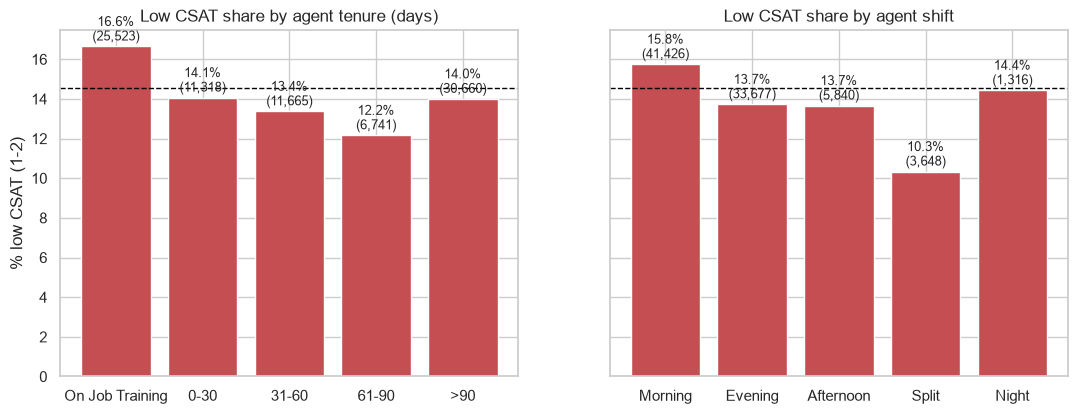

contacts  mean_csat  low_share
tenure On Job Training     25523      4.145      0.166
       0-30                11318      4.259      0.141
       31-60               11665      4.296      0.134
       61-90                6741      4.347      0.122
       >90                 30660      4.273      0.140
shift  Morning             41426      4.189      0.158
       Evening             33677      4.276      0.137
       Afternoon            5840      4.292      0.137
       Split                3648      4.427      0.103
       Night                1316      4.289      0.144

In [22]:
# Chart - 9 visualization code: do newer agents or some shifts get lower scores?
tenure_order = ["On Job Training", "0-30", "31-60", "61-90", ">90"]
ten = df.groupby("Tenure Bucket").agg(contacts=("CSAT", "size"), mean_csat=("CSAT", "mean"), low_share=("Low_CSAT", "mean")).reindex(tenure_order)
sh = df.groupby("Agent Shift").agg(contacts=("CSAT", "size"), mean_csat=("CSAT", "mean"), low_share=("Low_CSAT", "mean")).sort_values("contacts", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, tab, title in [(axes[0], ten, "Agent tenure (days)"), (axes[1], sh, "Agent shift")]:
    ax.bar(tab.index, tab["low_share"] * 100, color="#C44E52")
    ax.axhline(df["Low_CSAT"].mean() * 100, ls="--", color="black", lw=1)
    for i, (v, n) in enumerate(zip(tab["low_share"] * 100, tab["contacts"])):
        ax.text(i, v + 0.3, f"{v:.1f}%\n({n:,})", ha="center", fontsize=9)
    ax.set_title(f"Low CSAT share by {title.lower()}")
axes[0].set_ylabel("% low CSAT (1-2)")
save_fig(fig, "chart09_tenure_shift")
plt.show()
pd.concat([ten, sh], keys=["tenure", "shift"]).round(3)

##### 1. Why did you pick the specific chart?

Bar charts of the share of low scores per tenure bucket and per shift, with the overall average and the number of contacts, compare the groups fairly.

##### 2. What is/are the insight(s) found from the chart?

Agents in On Job Training get the most low scores (16.6%), against 12.2% to 14.1% for the other tenure groups. The Morning shift is a bit worse (15.8%) than Evening and Afternoon (13.7%), and the Split shift is the best (10.3%).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. New agents in training need support, for example a buddy, easier queues or quick escalation to a senior for difficult issues. The negative insight is that 30% of all contacts are handled by agents still in training.

#### Chart - 10 - How much do agents differ?

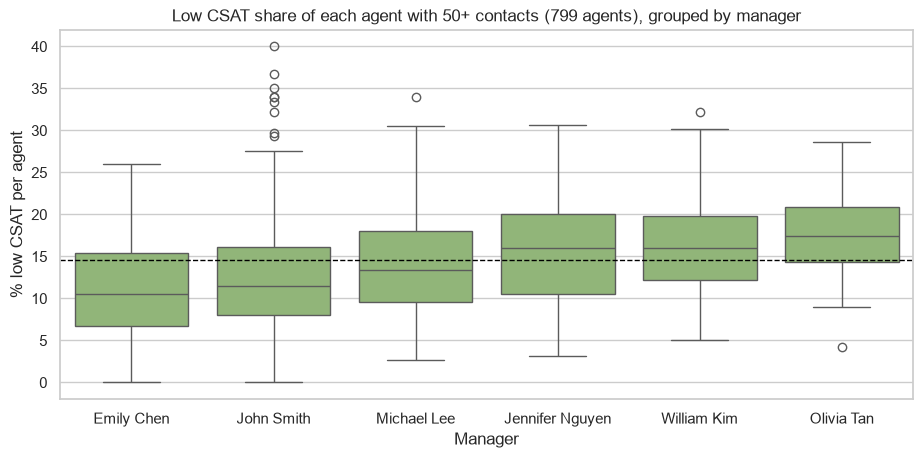

agents with 50+ contacts: 799; low CSAT share 10th percentile 6.0%, median 13.1%, 90th 22.2%
supervisors: low CSAT share from 10.1% to 33.1%


,count,25%,50%,75%
Manager,,,,
Emily Chen,139.0,0.067,0.105,0.154
Jennifer Nguyen,140.0,0.105,0.160,0.200
John Smith,237.0,0.081,0.115,0.161
Michael Lee,176.0,0.095,0.133,0.180
Olivia Tan,40.0,0.144,0.174,0.209
William Kim,67.0,0.121,0.160,0.198


In [23]:
# Chart - 10 visualization code: spread of the low-CSAT share between agents, per manager
agents = df.groupby(["Manager", "Agent_name"]).agg(contacts=("CSAT", "size"), low_share=("Low_CSAT", "mean"),
                                                   mean_csat=("CSAT", "mean")).reset_index()
busy_agents = agents[agents["contacts"] >= 50]
order = busy_agents.groupby("Manager")["low_share"].median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 4.8))
sns.boxplot(data=busy_agents, x="Manager", y=busy_agents["low_share"] * 100, order=order, color="#8FBF6F", ax=ax)
ax.axhline(df["Low_CSAT"].mean() * 100, ls="--", color="black", lw=1)
ax.set_ylabel("% low CSAT per agent")
ax.set_title(f"Low CSAT share of each agent with 50+ contacts ({len(busy_agents)} agents), grouped by manager")
save_fig(fig, "chart10_agents")
plt.show()
q = busy_agents["low_share"].quantile([0.1, 0.5, 0.9])
print(f"agents with 50+ contacts: {len(busy_agents)}; low CSAT share 10th percentile {q[0.1]:.1%}, median {q[0.5]:.1%}, 90th {q[0.9]:.1%}")
sup = df.groupby("Supervisor")["Low_CSAT"].mean()
print(f"supervisors: low CSAT share from {sup.min():.1%} to {sup.max():.1%}")
busy_agents.groupby("Manager")["low_share"].describe()[["count", "25%", "50%", "75%"]].round(3)

##### 1. Why did you pick the specific chart?

A box plot of the low-score share of each agent (with at least 50 contacts), grouped by manager, shows how much agents differ and whether some teams are better.

##### 2. What is/are the insight(s) found from the chart?

Agents differ a lot. For the 799 agents with at least 50 contacts, the share of low scores goes from 6.0% (10th percentile) to 22.2% (90th percentile), with a median of 13.1%. The teams differ too: Emily Chen's agents have a median of 10.5%, while Olivia Tan's have 17.4% and Jennifer Nguyen's and William Kim's 16.0%. Between supervisors the share goes from 10.1% to 33.1%.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The best agents and teams can show the others what works, and the agents with the highest share can get coaching. Because agents matter, I gave the neural network an embedding for each agent. The negative side is that one team has twice the share of unhappy customers of another, which points to differences in training or in the issues each team gets.

#### Chart - 11 - Product category and item price

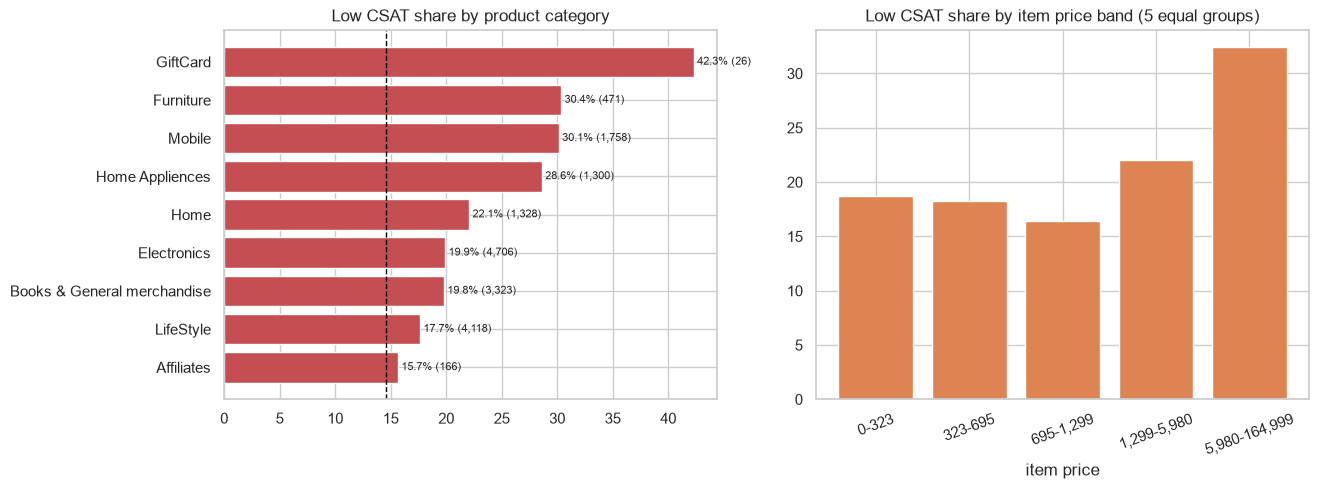

contacts with product info: 17,196 (20.0%); their low CSAT share 21.5% vs 12.8% without


,contacts,low_share
Price_Band,,
"(-0.001, 323.0]",3442,0.187
"(323.0, 695.0]",3445,0.183
"(695.0, 1299.0]",3612,0.164
"(1299.0, 5980.0]",3266,0.220
"(5980.0, 164999.0]",3441,0.324


In [24]:
# Chart - 11 visualization code: for the 20% of contacts linked to a product, which products and prices go wrong?
prod = df[df["Product_category"] != "Unknown"]
pc = prod.groupby("Product_category").agg(contacts=("CSAT", "size"), low_share=("Low_CSAT", "mean")).sort_values("low_share")
priced = df[df["Has_Price"] == 1].copy()
priced["Price_Band"] = pd.qcut(priced["Item_Price"], 5, duplicates="drop")
pb = priced.groupby("Price_Band", observed=True).agg(contacts=("CSAT", "size"), low_share=("Low_CSAT", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].barh(pc.index, pc["low_share"] * 100, color="#C44E52")
axes[0].axvline(df["Low_CSAT"].mean() * 100, ls="--", color="black", lw=1)
for i, (v, n) in enumerate(zip(pc["low_share"] * 100, pc["contacts"])):
    axes[0].text(v + 0.3, i, f"{v:.1f}% ({n:,})", va="center", fontsize=8)
axes[0].set_title("Low CSAT share by product category")
axes[1].bar([f"{int(b.left):,}-{int(b.right):,}" for b in pb.index], pb["low_share"] * 100, color="#DD8452")
axes[1].set_title("Low CSAT share by item price band (5 equal groups)")
axes[1].set_xlabel("item price")
axes[1].tick_params(axis="x", rotation=20)
save_fig(fig, "chart11_product_price")
plt.show()
print(f"contacts with product info: {len(prod):,} ({len(prod) / len(df):.1%}); their low CSAT share {prod['Low_CSAT'].mean():.1%} "
      f"vs {df.loc[df['Product_category'] == 'Unknown', 'Low_CSAT'].mean():.1%} without")
pb.round(3)

##### 1. Why did you pick the specific chart?

Only 20% of the contacts have product details, so I compare the product categories and five equal price bands for those contacts.

##### 2. What is/are the insight(s) found from the chart?

Contacts linked to a product are less happy (21.5% low scores against 12.8%). Mobile (30.1%), Furniture (30.4%) and Home Appliances (28.6%) are the worst, and the most expensive band (above 5,980) has 32.4% low scores, against 16% to 22% for the cheaper bands.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Expensive electronics, phones and furniture deserve priority handling, because those customers have more at stake. The negative insight is that the most valuable orders give the lowest satisfaction, which is also the biggest risk for losing customers.

#### Chart - 12 - Customer remarks by CSAT score

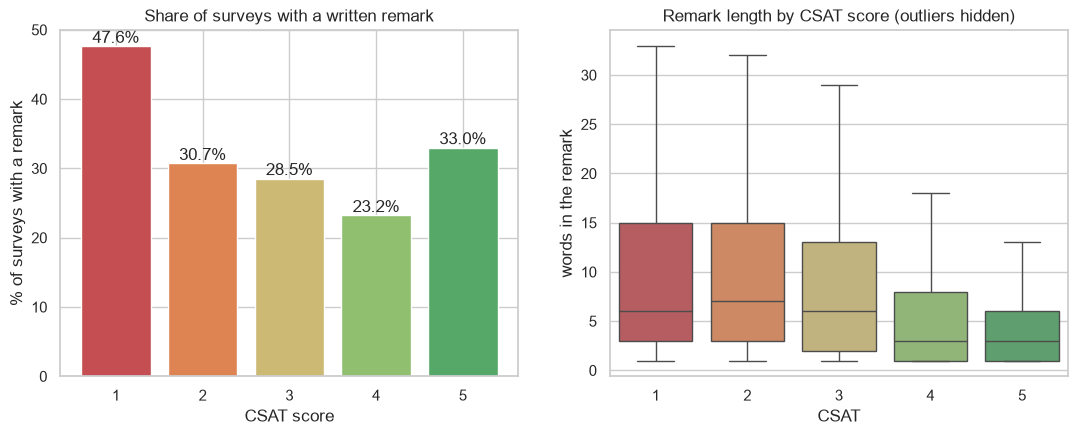

surveys with a remark: 28,742 (33.5%)
median words per remark by score: {1: 6.0, 2: 7.0, 3: 6.0, 4: 3.0, 5: 3.0}


In [25]:
# Chart - 12 visualization code: who writes a remark, and how long is it?
rem = df.groupby("CSAT").agg(remark_share=("Has_Remark", "mean"))
with_rem = df[df["Has_Remark"] == 1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(rem.index.astype(str), rem["remark_share"] * 100, color=CSAT_COLORS)
for i, v in enumerate(rem["remark_share"] * 100):
    axes[0].text(i, v + 0.5, f"{v:.1f}%", ha="center")
axes[0].set_xlabel("CSAT score")
axes[0].set_ylabel("% of surveys with a remark")
axes[0].set_title("Share of surveys with a written remark")
sns.boxplot(data=with_rem, x="CSAT", y="Remark_Words", palette=CSAT_COLORS, showfliers=False, ax=axes[1])
axes[1].set_ylabel("words in the remark")
axes[1].set_title("Remark length by CSAT score (outliers hidden)")
save_fig(fig, "chart12_remarks")
plt.show()
print(f"surveys with a remark: {df['Has_Remark'].sum():,} ({df['Has_Remark'].mean():.1%})")
print("median words per remark by score:", with_rem.groupby("CSAT")["Remark_Words"].median().to_dict())

##### 1. Why did you pick the specific chart?

The left chart shows who writes a remark for each score, the box plot how long the remarks are.

##### 2. What is/are the insight(s) found from the chart?

33.5% of the surveys have a remark. Unhappy customers write more often (47.6% of CSAT 1 against 33.0% of CSAT 5) and longer: the median remark has 6 words for a score of 1 and 3 words for scores 4 and 5. Happy customers write short things like "good" or "very nice".

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. A long remark is already a sign of a problem, and the remarks of unhappy customers explain what went wrong, which is useful feedback. The negative side is that two thirds of the customers write nothing, so a model can't rely on text alone.

#### Chart - 13 - Words that separate unhappy and happy remarks

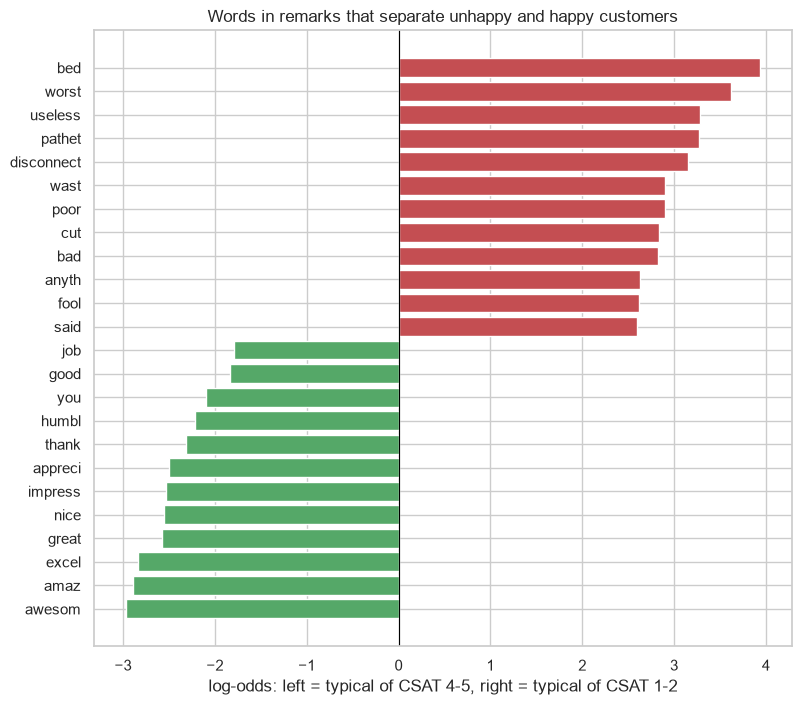

most frequent words in low-CSAT remarks: ['not', 'custom', 'servic', 'shopzilla', 'veri', 'product', 'bad', 'issu', 'no', 'time', 'resolv', 'order']
most frequent words in high-CSAT remarks: ['good', 'veri', 'thank', 'custom', 'nice', 'servic', 'shopzilla', 'support', 'pleas', 'not', 'product', 'execut']


In [26]:
# Chart - 13 visualization code: which (cleaned, stemmed) words are typical for low and for high scores?
def word_counts(texts):
    return Counter(w for t in texts for w in set(t.split()))


low_words = word_counts(with_rem.loc[with_rem["CSAT"] <= 2, TEXT_COL])
high_words = word_counts(with_rem.loc[with_rem["CSAT"] >= 4, TEXT_COL])
n_low, n_high = (with_rem["CSAT"] <= 2).sum(), (with_rem["CSAT"] >= 4).sum()
vocab_common = [w for w in set(low_words) | set(high_words) if low_words[w] + high_words[w] >= 40]
# log-odds ratio with +1 smoothing: > 0 means the word is more typical of unhappy customers
log_odds = pd.Series({w: np.log((low_words[w] + 1) / (n_low + 1)) - np.log((high_words[w] + 1) / (n_high + 1))
                      for w in vocab_common}).sort_values()
top = pd.concat([log_odds.head(12), log_odds.tail(12)])
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top.index, top.values, color=["#55A868" if v < 0 else "#C44E52" for v in top.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("log-odds: left = typical of CSAT 4-5, right = typical of CSAT 1-2")
ax.set_title("Words in remarks that separate unhappy and happy customers")
save_fig(fig, "chart13_remark_words")
plt.show()
print("most frequent words in low-CSAT remarks:", [w for w, _ in low_words.most_common(12)])
print("most frequent words in high-CSAT remarks:", [w for w, _ in high_words.most_common(12)])

##### 1. Why did you pick the specific chart?

A diverging bar chart of the log-odds shows which words are typical for unhappy customers (right) and for happy ones (left), using the same cleaned words the model reads.

##### 2. What is/are the insight(s) found from the chart?

The words of unhappy customers are about bad service and calls that went wrong: worst, useless, pathetic, disconnect, waste, poor, bad, cut (as in "call cut") and fool. Happy customers write awesome, amazing, excellent, great, nice, impressive, appreciate, thank and good job. Negations matter: "not" is the most frequent word in low-score remarks, which is why I kept it in the cleaning.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The words show what makes customers unhappy: unresolved issues, refunds, delivery and bad service. These can be tracked over time. The negative side is the Hindi and Hinglish words and the typos, which a simple word model only partly understands.

#### Chart - 14 - Correlation Heatmap

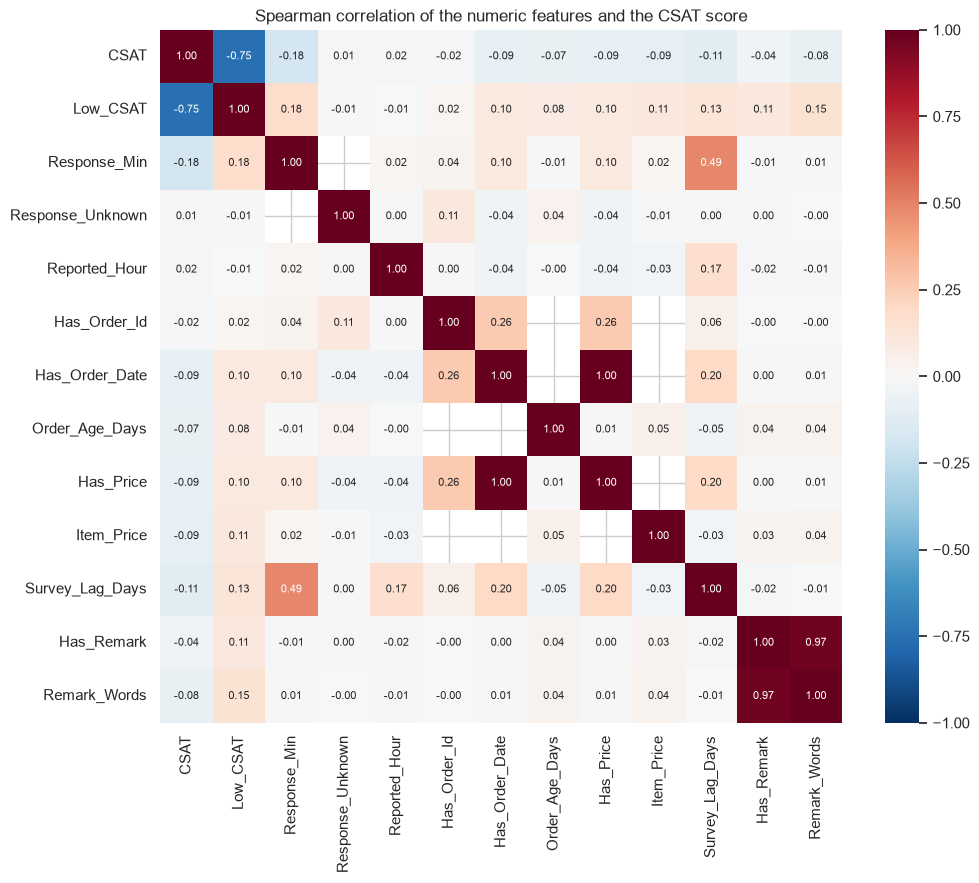

correlation with CSAT:
Response_Min       -0.185
Survey_Lag_Days    -0.112
Item_Price         -0.093
Has_Order_Date     -0.086
Has_Price          -0.086
Remark_Words       -0.076
Order_Age_Days     -0.074
Has_Remark         -0.040
Has_Order_Id       -0.021
Response_Unknown    0.010
Reported_Hour       0.015


In [27]:
# Correlation Heatmap visualization code
num_view = ["CSAT", "Low_CSAT", "Response_Min", "Response_Unknown", "Reported_Hour", "Has_Order_Id", "Has_Order_Date",
            "Order_Age_Days", "Has_Price", "Item_Price", "Survey_Lag_Days", "Has_Remark", "Remark_Words"]
corr = df[num_view].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 8}, ax=ax)
ax.set_title("Spearman correlation of the numeric features and the CSAT score")
save_fig(fig, "chart14_correlation_heatmap")
plt.show()
print("correlation with CSAT:")
print(corr["CSAT"].drop(["CSAT", "Low_CSAT"]).sort_values().round(3).to_string())

##### 1. Why did you pick the specific chart?

A heatmap shows all pairwise correlations at once. I used Spearman correlation because the response time, price and remark length are very skewed.

##### 2. What is/are the insight(s) found from the chart?

The response time has the strongest correlation with the score (-0.185), followed by the days between issue and survey (-0.112), the price (-0.093) and having an order date or a price (-0.086). All correlations with the score are weak on their own, which means no single number decides the score. The order-related flags (order date, price, order age) are almost the same feature (0.99), because the product details are filled in for the same 20% of contacts, and the remark flag and remark length are 0.97.

#### Chart - 15 - Pair Plot 

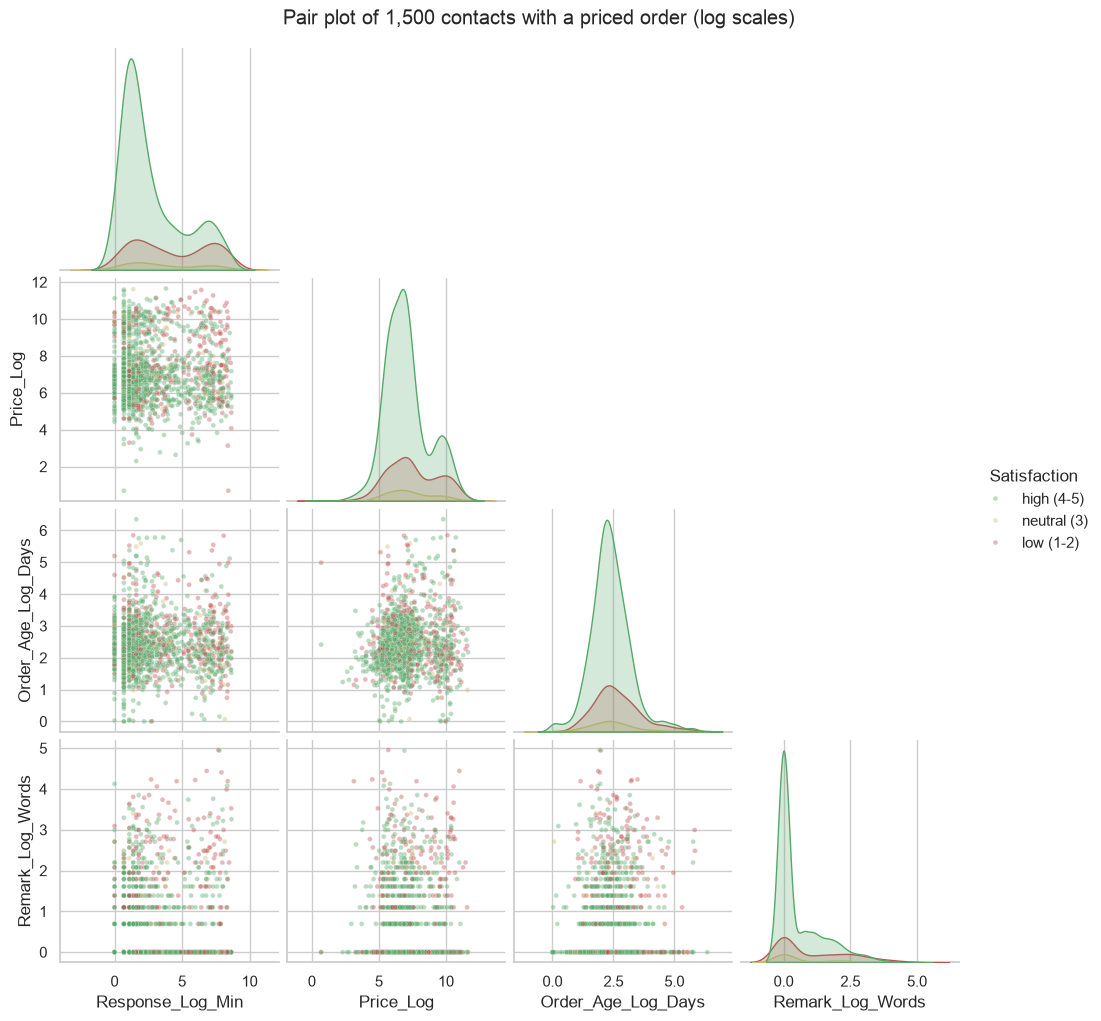

In [28]:
# Pair Plot visualization code
# contacts that are linked to a priced order (20%), so the price and order age are filled in
pair = df[(df["Has_Price"] == 1) & (df["Has_Order_Date"] == 1)].sample(1500, random_state=SEED)
pair = pair.assign(Satisfaction=np.where(pair["CSAT"] <= 2, "low (1-2)", np.where(pair["CSAT"] == 3, "neutral (3)", "high (4-5)")))
g = sns.pairplot(pair[["Response_Log_Min", "Price_Log", "Order_Age_Log_Days", "Remark_Log_Words", "Satisfaction"]],
                 hue="Satisfaction", hue_order=["high (4-5)", "neutral (3)", "low (1-2)"],
                 palette=["#55A868", "#CCB974", "#C44E52"], plot_kws={"alpha": 0.4, "s": 12}, corner=True)
g.fig.suptitle("Pair plot of 1,500 contacts with a priced order (log scales)", y=1.02)
save_fig(g.fig, "chart15_pair_plot")
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows the distribution of each feature and every pair of features, coloured by satisfaction group. I used 1,500 contacts with an order and a price, so all four numbers are filled in.

##### 2. What is/are the insight(s) found from the chart?

The groups overlap a lot in every pair of features. Low scores are more common at long response times and with long remarks, and slightly more at high prices, but there is no clean border between happy and unhappy customers. The model needs many features together, and some contacts will always be hard to predict.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

From the charts I picked three statements to test:
1. Unhappy customers (CSAT 1-2) waited longer for a response than happy customers (CSAT 4-5) (charts 5 and 6).
2. The share of low scores depends on the channel (chart 2).
3. CSAT scores differ between agent tenure groups (chart 9).

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- Null hypothesis (H0): the response time of unhappy customers is not longer than that of happy customers.
- Alternative hypothesis (H1): unhappy customers waited longer than happy customers.

#### 2. Perform an appropriate statistical test.

In [29]:
# Perform Statistical Test to obtain P-Value
# H1: unhappy customers (CSAT 1-2) waited longer for a reply than happy ones (CSAT 4-5)
wait_low = df.loc[(df["CSAT"] <= 2) & df["Response_Min"].notna(), "Response_Min"]
wait_high = df.loc[(df["CSAT"] >= 4) & df["Response_Min"].notna(), "Response_Min"]
u_stat, p_value = stats.mannwhitneyu(wait_low, wait_high, alternative="greater")
effect = 2 * u_stat / (len(wait_low) * len(wait_high)) - 1           # rank-biserial correlation
print(f"median wait: low CSAT {wait_low.median():.0f} min ({len(wait_low):,} contacts), high CSAT {wait_high.median():.0f} min ({len(wait_high):,})")
print(f"Mann-Whitney U = {u_stat:,.0f}, p-value = {p_value:.2e}, rank-biserial effect = {effect:.3f}")
print("reject H0" if p_value < 0.05 else "fail to reject H0")

median wait: low CSAT 20 min (12,091 contacts), high CSAT 5 min (67,905)
Mann-Whitney U = 535,412,993, p-value = 0.00e+00, rank-biserial effect = 0.304
reject H0


##### Which statistical test have you done to obtain P-Value?

Mann-Whitney U test (one-sided). The median wait was 20 minutes for unhappy customers (12,091 contacts) and 5 minutes for happy ones (67,905). U = 535,412,993, the p-value is so small that it rounds to 0, and the rank-biserial effect size is 0.30, a medium effect. So H0 is rejected.

##### Why did you choose the specific statistical test?

Response times are very skewed (from 0 minutes to 4 days), so a t-test on the means would be driven by a few very long waits. The Mann-Whitney test compares the two groups by ranks and does not assume normal data.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- Null hypothesis (H0): the share of low scores is the same for every channel.
- Alternative hypothesis (H1): the share of low scores depends on the channel.

#### 2. Perform an appropriate statistical test.

In [30]:
# Perform Statistical Test to obtain P-Value
# H2: the share of low CSAT does not depend on the channel
table = pd.crosstab(df["channel_name"], df["Low_CSAT"])
chi2, p_value, dof, expected = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
print(table.assign(low_share=(table[1] / table.sum(axis=1)).round(3)))
print(f"chi-square = {chi2:.1f}, dof = {dof}, p-value = {p_value:.2e}, Cramer's V = {cramers_v:.3f}")
print("reject H0" if p_value < 0.05 else "fail to reject H0")

Low_CSAT          0     1  low_share
channel_name                        
Email          2323   700      0.232
Inbound       58386  9756      0.143
Outcall       12685  2057      0.140
chi-square = 187.1, dof = 2, p-value = 2.38e-41, Cramer's V = 0.047
reject H0


##### Which statistical test have you done to obtain P-Value?

Chi-square test of independence on the channel x low-CSAT table. Chi-square = 187.1 with 2 degrees of freedom, p-value = 2.4e-41, so H0 is rejected. Email has 23.2% low scores against 14.3% and 14.0% for the phone channels. Cramer's V is 0.047, so the link is real but small next to everything else.

##### Why did you choose the specific statistical test?

Both variables are categorical (three channels, low or not low), and the chi-square test of independence is the standard test for a table of counts. The counts are large, so the chi-square approximation is reliable.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- Null hypothesis (H0): the CSAT scores have the same distribution in all five tenure groups.
- Alternative hypothesis (H1): at least one tenure group has a different distribution of scores.

#### 2. Perform an appropriate statistical test.

In [31]:
# Perform Statistical Test to obtain P-Value
# H3: CSAT scores have the same distribution for every agent tenure bucket
groups = [df.loc[df["Tenure Bucket"] == t, "CSAT"] for t in tenure_order]
h_stat, p_value = stats.kruskal(*groups)
eps2 = (h_stat - len(groups) + 1) / (len(df) - len(groups))          # epsilon-squared effect size
print(df.groupby("Tenure Bucket")["CSAT"].agg(["size", "mean"]).reindex(tenure_order)
      .assign(low_share=df.groupby("Tenure Bucket")["Low_CSAT"].mean()).round(3))
print(f"Kruskal-Wallis H = {h_stat:.1f}, p-value = {p_value:.2e}, epsilon-squared = {eps2:.4f}")
print("reject H0" if p_value < 0.05 else "fail to reject H0")

                  size   mean  low_share
Tenure Bucket                           
On Job Training  25523  4.145      0.166
0-30             11318  4.259      0.141
31-60            11665  4.296      0.134
61-90             6741  4.347      0.122
>90              30660  4.273      0.140
Kruskal-Wallis H = 223.5, p-value = 3.38e-47, epsilon-squared = 0.0026
reject H0


##### Which statistical test have you done to obtain P-Value?

Kruskal-Wallis H test. H = 223.5, p-value = 3.4e-47, so H0 is rejected. Agents in On Job Training have the lowest mean score (4.15) and 61-90 days the highest (4.35). The effect size (epsilon-squared 0.003) is very small, so tenure matters, but much less than the response time.

##### Why did you choose the specific statistical test?

The score is ordinal (1 to 5) and not normal, and there are five independent groups. Kruskal-Wallis compares several groups by ranks without assuming normal data or equal variances, so it fits better than one-way ANOVA.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [32]:
# Handling Missing Values & Missing Value Imputation
handling = {
    "connected_handling_time": "dropped: 99.7% missing",
    "Customer_City": "kept as its own category 'Unknown'",
    "Product_category": "kept as its own category 'Unknown'",
    "Item_price": "log price, 0 when missing + Has_Price flag",
    "order_date_time": "order age in days, 0 when missing + Has_Order_Date flag",
    "Customer Remarks": "empty text + Has_Remark flag",
    "Order_id": "id not used, only the Has_Order_Id flag",
}
plan = missing[missing["missing"] > 0].sort_values("missing", ascending=False).copy()
plan["handling"] = plan.index.map(handling)
print(plan.to_string())

model_cols = CAT_COLS + NUM_SURVEY + [TEXT_COL]
print("\nmissing values left in the model inputs:", int(df[model_cols].isna().sum().sum()))
print("response time unknown (flagged, set to 0 in the log column):", int(df["Response_Unknown"].sum()))

                         missing  missing %                                                 handling
connected_handling_time    85665       99.7                                   dropped: 99.7% missing
Customer_City              68828       80.1                       kept as its own category 'Unknown'
Product_category           68711       80.0                       kept as its own category 'Unknown'
Item_price                 68701       80.0               log price, 0 when missing + Has_Price flag
order_date_time            68693       80.0  order age in days, 0 when missing + Has_Order_Date flag
Customer Remarks           57165       66.5                             empty text + Has_Remark flag
Order_id                   18232       21.2                  id not used, only the Has_Order_Id flag

missing values left in the model inputs: 0
response time unknown (flagged, set to 0 in the log column): 3442


#### What all missing value imputation techniques have you used and why did you use those techniques?

I handled every column by what its missing values mean, instead of one rule for all:
- connected_handling_time: dropped, because 99.7% is missing and 242 values can't teach the model anything.
- Customer_City and Product_category: filled with "Unknown". Missing here means the contact is not about a specific order, which is information, so it gets its own category.
- Item_price and order_date_time: the log price and the order age are 0 when unknown, and the Has_Price flag tells the model that the value is missing. Filling with the mean would invent a price for 80% of the contacts.
- Customer Remarks: an empty text and a length of 0. The text branch of the network then simply gets no words.
- Order_id: the id itself is useless, so only the flag "linked to an order" is kept.
- The response time on 28 Aug (saved without the time of day): set to unknown with the Response_Unknown flag, instead of a wrong negative number.

After this there are no missing values left in the model inputs.

### 2. Handling Outliers

In [33]:
# Handling Outliers & Outlier treatments
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return ((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum()


skewed = {"Response_Min": "Response_Log_Min", "Item_Price": "Price_Log", "Order_Age_Days": "Order_Age_Log_Days",
          "Remark_Words": "Remark_Log_Words"}
rows = []
for col, log_col in skewed.items():
    s = df[col].dropna()
    if col == "Remark_Words":
        s = s[s > 0]
    rows.append({"feature": col, "rows": len(s), "IQR outliers": iqr_outliers(s), "max": s.max(),
                 "skew before": round(s.skew(), 2), "skew after log1p": round(np.log1p(s).skew(), 2)})
print(pd.DataFrame(rows).to_string(index=False))
print("\nlow CSAT share among response-time outliers:",
      f"{df.loc[df['Response_Min'] > df['Response_Min'].quantile(0.75) * 2.5, 'Low_CSAT'].mean():.1%}",
      f"vs {df['Low_CSAT'].mean():.1%} overall")

       feature  rows  IQR outliers       max  skew before  skew after log1p
  Response_Min 82465         15358   5758.00         5.28              1.08
    Item_Price 17206          3394 164999.00         4.23              0.52
Order_Age_Days 17156          1514    581.45         6.89              1.05
  Remark_Words 28742          2974    444.00         8.65              0.91

low CSAT share among response-time outliers: 26.0% vs 14.6% overall


##### What all outlier treatment techniques have you used and why did you use those techniques?

The outliers here are real values, not errors: a customer really waited 4 days, a phone really costs 164,999, and a remark can be 444 words long. The response time alone has 15,358 IQR outliers, and those contacts have 26.0% low scores against 14.6% overall, so the extreme waits are exactly the contacts the model has to recognise. Removing or capping them would throw away the most important signal.

Instead I used a log1p transform for the response time, price, order age and remark length. It keeps the order of the values but pulls in the long tail (for example the skewness of the response time drops from 5.3 to 1.1), so a few extreme values can't dominate the training of the network. The negative response times were not outliers but a logging error, and they are handled as unknown.

### 3. Categorical Encoding

In [34]:
# Encode your categorical columns
def embedding_dim(n_categories):
    """Rule of thumb for the size of an embedding: grows slowly with the number of categories, at most 24."""
    return int(min(24, max(2, round(1.6 * n_categories ** 0.56))))


MIN_CITY_COUNT = 20                                     # cities with fewer contacts share one 'rare' slot
enc = pd.DataFrame({"categories": df[CAT_COLS].nunique()})
city_counts = df["Customer_City"].value_counts()
enc.loc["Customer_City", "categories"] = (city_counts >= MIN_CITY_COUNT).sum()
enc["embedding size"] = enc["categories"].map(lambda n: embedding_dim(n + 1))
enc["one-hot columns"] = enc["categories"]
print(enc.to_string())
print(f"\ncities: {df['Customer_City'].nunique():,} in total, {(city_counts >= MIN_CITY_COUNT).sum()} with {MIN_CITY_COUNT}+ contacts "
      f"(cover {city_counts[city_counts >= MIN_CITY_COUNT].sum() / len(df):.1%} of rows incl. 'UNKNOWN')")
print(f"embedding inputs in total: {enc['embedding size'].sum()} numbers instead of {enc['one-hot columns'].sum():,} one-hot columns")

                  categories  embedding size  one-hot columns
channel_name               3               3                3
category                  12               7               12
Sub-category              57              16               57
Customer_City            175              24              175
Product_category          10               6               10
Agent_name              1371              24             1371
Supervisor                40              13               40
Manager                    6               5                6
Tenure Bucket              5               4                5
Agent Shift                5               4                5
Reported_Weekday           7               5                7

cities: 1,783 in total, 175 with 20+ contacts (cover 93.2% of rows incl. 'UNKNOWN')
embedding inputs in total: 111 numbers instead of 1,691 one-hot columns


#### What all categorical encoding techniques have you used & why did you use those techniques?

- For the neural networks I used **entity embeddings**: a StringLookup layer turns each category into a number, and an Embedding layer learns a small vector for it during training. The size grows slowly with the number of categories (rule: 1.6 x n^0.56, at most 24). An agent becomes 24 learned numbers instead of 1,371 one-hot columns, and agents who get similar scores end up with similar vectors. Categories never seen in training share one "unknown" slot, so new agents or cities don't break the model.
- Cities with fewer than 20 contacts (most of the 1,783 cities) share the unknown slot, because a city seen once or twice can't be learned and would only cause overfitting. The 175 kept cities cover 93.2% of the rows.
- For the logistic regression baseline I used one-hot encoding with the same rule for rare categories.

In total the network gets 111 embedding numbers instead of 1,691 one-hot columns.

### 4. Textual Data Preprocessing 
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [35]:
# Expand Contraction
from csat_features import (expand_contractions, lower_case, remove_punctuation, remove_urls_and_digit_words,
                           remove_stopwords, rephrase, tokenize, stem, STOP_WORDS, SHORT_FORMS)
txt = df.loc[df["Has_Remark"] == 1, ["Customer Remarks", "CSAT"]].copy()


def show_step(before, after, n=4):
    """How many remarks a step changed, with a few examples."""
    changed = before.astype(str) != after.astype(str)
    print(f"remarks changed by this step: {changed.sum():,} of {len(before):,}")
    for b, a in list(zip(before[changed], after[changed]))[:n]:
        print(f"   {b[:90]!r}\n-> {a[:90]!r}")


txt["step"] = txt["Customer Remarks"].map(expand_contractions)
show_step(txt["Customer Remarks"], txt["step"])

remarks changed by this step: 1,430 of 28,742
   "Shopzilla app and it's all coustomer care services is very good service provided all time"
-> 'Shopzilla app and it is all coustomer care services is very good service provided all time'
   "Please don't sale any destroy product or cheep product more price. "
-> 'Please do not sale any destroy product or cheep product more price. '
   "I selected for English language preference but it's goes into Hindi channel. But customer "
-> 'I selected for English language preference but it is goes into Hindi channel. But customer'
   "Please don't give the chance of local shop/ company,,, they're using the name of Shopzilla"
-> 'Please do not give the chance of local shop/ company,,, they are using the name of Shopzil'


#### 2. Lower Casing

In [36]:
# Lower Casing
before = txt["step"]
txt["step"] = txt["step"].map(lower_case)
show_step(before, txt["step"], n=3)

remarks changed by this step: 26,810 of 28,742
   'Very good'
-> 'very good'
   'Shopzilla app and it is all coustomer care services is very good service provided all time'
-> 'shopzilla app and it is all coustomer care services is very good service provided all time'
   'Very bad'
-> 'very bad'


#### 3. Removing Punctuations

In [37]:
# Remove Punctuations
before = txt["step"]
txt["step"] = txt["step"].map(remove_punctuation)
show_step(before, txt["step"], n=3)
print("remarks containing '??' (emojis lost in the export):", before.str.contains(r"\?\?").sum())

remarks changed by this step: 7,989 of 28,742
   'please highlight if the products cannot be returned.'
-> 'please highlight if the products cannot be returned '
   'please do not sale any destroy product or cheep product more price. '
-> 'please do not sale any destroy product or cheep product more price  '
   'i am very disappointed with shopzilla.the issue was not resolved.the customer care executi'
-> 'i am very disappointed with shopzilla the issue was not resolved the customer care executi'
remarks containing '??' (emojis lost in the export): 2371


#### 4. Removing URLs & Removing words and digits contain digits.

In [38]:
# Remove URLs & Remove words and digits contain digits
before = txt["step"]
txt["step"] = txt["step"].map(remove_urls_and_digit_words)
show_step(before, txt["step"], n=3)

remarks changed by this step: 1,321 of 28,742


   '3000 rupees loss '
-> '  rupees loss '
   'small product is take so much time and my order is ariving 2 aug but suddanly is change to'
-> 'small product is take so much time and my order is ariving   aug but suddanly is change to'
   'you have played around with this order  without taking customers concern  how can you plan'
-> 'you have played around with this order  without taking customers concern  how can you plan'


#### 5. Removing Stopwords & Removing White spaces

In [39]:
# Remove Stopwords
before = txt["step"]
txt["step"] = txt["step"].map(remove_stopwords)
show_step(before, txt["step"], n=3)
print(f"stop list: {len(STOP_WORDS)} function words; 'not', 'no', 'never', 'very', 'keep', 'well' are kept on purpose")

remarks changed by this step: 22,813 of 28,742


   'shopzilla app and it is all coustomer care services is very good service provided all time'
-> 'shopzilla app all coustomer care services very good service provided all time'
   'something '
-> 'something'
   'good '
-> 'good'
stop list: 72 function words; 'not', 'no', 'never', 'very', 'keep', 'well' are kept on purpose


In [40]:
# Remove White spaces
before = txt["step"]
txt["step"] = txt["step"].str.split().str.join(" ")
print("extra white space left after the previous step:", (before != txt["step"]).sum())
print("remarks that are empty after cleaning (only emojis or stop words):", (txt["step"] == "").sum())

extra white space left after the previous step: 0
remarks that are empty after cleaning (only emojis or stop words): 639


#### 6. Rephrase Text

In [41]:
# Rephrase Text
before = txt["step"]
txt["step"] = txt["step"].map(rephrase)
show_step(before, txt["step"], n=5)
print("short forms and typos rewritten:", len(SHORT_FORMS))

remarks changed by this step: 1,445 of 28,742


   'customer service number plz available'
-> 'customer service number please available'
   'ok'
-> 'okay'
   'thankyou'
-> 'thank you'
   'thankyou much'
-> 'thank you much'
   'nyc talkng'
-> 'nice talkng'
short forms and typos rewritten: 22


#### 7. Tokenization

In [42]:
# Tokenization
txt["tokens"] = txt["step"].map(tokenize)
lengths = txt["tokens"].str.len()
print(f"tokens per remark: median {lengths.median():.0f}, 90th percentile {lengths.quantile(0.9):.0f}, max {lengths.max()}")
print(txt["tokens"].head(5).tolist())

tokens per remark: median 3, 90th percentile 12, max 314
[['very', 'good'], ['shopzilla', 'app', 'all', 'coustomer', 'care', 'services', 'very', 'good', 'service', 'provided', 'all', 'time'], ['very', 'bad'], ['something'], ['all', 'good']]


#### 8. Text Normalization

In [43]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
txt["clean"] = txt["tokens"].map(lambda toks: " ".join(stem(toks)))
show_step(txt["tokens"].str.join(" "), txt["clean"], n=4)
# the step-by-step result must equal what the model gets from csat_features.clean_remark
print("same as the model input for every remark:", bool((txt["clean"] == df.loc[txt.index, TEXT_COL]).all()))
print("distinct words before stemming:", len({w for t in txt["tokens"] for w in t}),
      "| after:", len({w for t in txt["clean"] for w in t.split()}))

remarks changed by this step: 19,387 of 28,742
   'very good'
-> 'veri good'
   'shopzilla app all coustomer care services very good service provided all time'
-> 'shopzilla app all coustom care servic veri good servic provid all time'
   'very bad'
-> 'veri bad'
   'something'
-> 'someth'
same as the model input for every remark: True
distinct words before stemming: 9428 | after: 7377


##### Which text normalization technique have you used and why?

I used the Porter stemmer from NLTK, which cuts words to their stem: "resolved", "resolving" and "resolve" all become "resolv", and "services" becomes "servic". It reduced the number of distinct words from 9,428 to 7,377, so the model sees more examples of each word, which matters with only 28,742 remarks, most of them 1 to 3 words long. I chose stemming over lemmatization because it needs no extra dictionary download, which keeps the deployed app simple, and the remarks are short, informal and full of typos and Hinglish, where a dictionary-based lemmatizer helps little. Before stemming, the rephrase step fixed common short forms and typos (pls, thx, nt, gud, nyc and others).

#### 9. Part of speech tagging

In [44]:
# POS Taging
# analysis only (not a model input): which adjectives do unhappy and happy customers use?
try:
    for res in ["averaged_perceptron_tagger_eng", "averaged_perceptron_tagger"]:
        nltk.download(res, quiet=True)
    sample = txt.sample(min(len(txt), 8000), random_state=SEED)
    tagged = sample["tokens"].map(nltk.pos_tag)
    adjectives = tagged.map(lambda tags: [w for w, t in tags if t.startswith("JJ")])
    for label, mask in [("CSAT 1-2", sample["CSAT"] <= 2), ("CSAT 4-5", sample["CSAT"] >= 4)]:
        top_adj = Counter(w for ws in adjectives[mask] for w in ws).most_common(10)
        print(f"top adjectives, {label}: {[w for w, _ in top_adj]}")
    print("tag counts:", Counter(t[:2] for tags in tagged for _, t in tags).most_common(6))
except Exception as e:                                   # the tagger needs a download; skip if offline
    print("POS tagger not available:", e)

top adjectives, CSAT 1-2: ['bad', 'worst', 'good', 'poor', 'wrong', 'pathetic', 'same', 'disappointed', 'more', 'happy']
top adjectives, CSAT 4-5: ['good', 'nice', 'happy', 'best', 'much', 'helpful', 'great', 'excellent', 'polite', 'satisfied']
tag counts: [('NN', 18904), ('JJ', 7909), ('VB', 5780), ('RB', 4629), ('IN', 911), ('DT', 855)]


#### 10. Text Vectorization

In [45]:
# Vectorizing Text
# for the logistic regression baseline: TF-IDF of words and word pairs
tfidf_demo = TfidfVectorizer(ngram_range=(1, 2), min_df=3)
tf_matrix = tfidf_demo.fit_transform(txt["clean"])
print(f"TF-IDF matrix: {tf_matrix.shape[0]:,} remarks x {tf_matrix.shape[1]:,} terms, "
      f"{tf_matrix.nnz / tf_matrix.shape[0]:.1f} non-zero terms per remark")
terms = np.array(tfidf_demo.get_feature_names_out())
for label, mask in [("CSAT 1-2", txt["CSAT"].values <= 2), ("CSAT 4-5", txt["CSAT"].values >= 4)]:
    mean_w = np.asarray(tf_matrix[mask].mean(axis=0)).ravel()
    print(f"highest average TF-IDF, {label}: {terms[mean_w.argsort()[::-1][:10]].tolist()}")
# for the neural network the remark goes in as raw text and a Keras TextVectorization layer inside the model
# turns it into a multi-hot vector of words and word pairs (learned on the training data only, see ML Model 3)

TF-IDF matrix: 28,742 remarks x 8,606 terms, 6.7 non-zero terms per remark
highest average TF-IDF, CSAT 1-2: ['not', 'bad', 'servic', 'veri', 'shopzilla', 'veri bad', 'custom', 'product', 'no', 'issu']
highest average TF-IDF, CSAT 4-5: ['good', 'thank', 'veri', 'nice', 'veri good', 'servic', 'custom', 'happi', 'excel', 'support']


##### Which text vectorization technique have you used and why?

Two versions of the same idea, a bag of words and word pairs:
- For the logistic regression baseline: TF-IDF on words and word pairs (8,606 terms that appear at least 3 times). Pairs matter here because "not good" and "very good" mean opposite things.
- For the neural network: a Keras TextVectorization layer inside the model that turns the cleaned remark into a multi-hot vector of the most common words and word pairs (the vocabulary size was tuned, 2,000 or 5,000), followed by a small dense layer. Its vocabulary is learned from the training rows only and is saved inside the model, so the deployed app passes the raw remark and the model does the rest.

I did not use pre-trained word embeddings because the remarks are very short (median 3 words), mixed English and Hinglish, and full of typos, and downloading a large embedding model would make the local deployment heavy. It is the first thing I would try next (see the conclusion).

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [46]:
# Manipulate Features to minimize feature correlation and create new features
feature_info = pd.DataFrame([
    ("Response_Log_Min", "log of minutes from issue reported to first response", "real time"),
    ("Response_Unknown", "1 when the reply time was saved without the time of day", "real time"),
    ("Hour_Sin, Hour_Cos", "hour the issue came in, as a circle", "real time"),
    ("Reported_Weekday", "weekday the issue came in", "real time"),
    ("Has_Order_Id", "contact is linked to an order", "real time"),
    ("Order_Age_Log_Days", "days between the order and the issue (log, 0 when unknown)", "real time"),
    ("Has_Price, Price_Log", "item price (log)", "real time"),
    ("Survey_Lag_Days", "days between the issue and the survey answer", "after the survey"),
    ("Remark_Log_Words", "length of the remark (log, 0 when there is none)", "after the survey"),
    ("Remark_Clean", "cleaned remark text", "after the survey"),
], columns=["feature", "meaning", "known"])
print(feature_info.to_string(index=False))

# near copies among the candidate numeric features (|Spearman| > 0.9)
candidates_num = NUM_SURVEY + ["Has_Order_Date", "Has_Remark"]
c = df[candidates_num].corr(method="spearman").abs()
pairs = [(a, b, round(c.loc[a, b], 3)) for i, a in enumerate(candidates_num) for b in candidates_num[i + 1:] if c.loc[a, b] > 0.9]
print("\npairs with |Spearman| > 0.9:")
for a, b, v in pairs:
    print(f"   {a} - {b}: {v}")
print("dropped from the model: Has_Order_Date (same as Has_Price), Has_Remark (Remark_Log_Words is 0 without a remark)")
print("the raw minutes, price, order age and word count are replaced by their log versions")
print("kept on purpose: Has_Price with Price_Log and Order_Age_Log_Days, because the flags say 'no product' while the logs give the size")

             feature                                                    meaning            known
    Response_Log_Min       log of minutes from issue reported to first response        real time
    Response_Unknown    1 when the reply time was saved without the time of day        real time
  Hour_Sin, Hour_Cos                        hour the issue came in, as a circle        real time
    Reported_Weekday                                  weekday the issue came in        real time
        Has_Order_Id                              contact is linked to an order        real time
  Order_Age_Log_Days days between the order and the issue (log, 0 when unknown)        real time
Has_Price, Price_Log                                           item price (log)        real time
     Survey_Lag_Days               days between the issue and the survey answer after the survey
    Remark_Log_Words           length of the remark (log, 0 when there is none) after the survey
        Remark_Clean          

#### 2. Feature Selection

chance level that was subtracted, largest: {'Agent_name': 0.0342, 'Customer_City': 0.0286, 'Has_Order_Id': 0.0076}


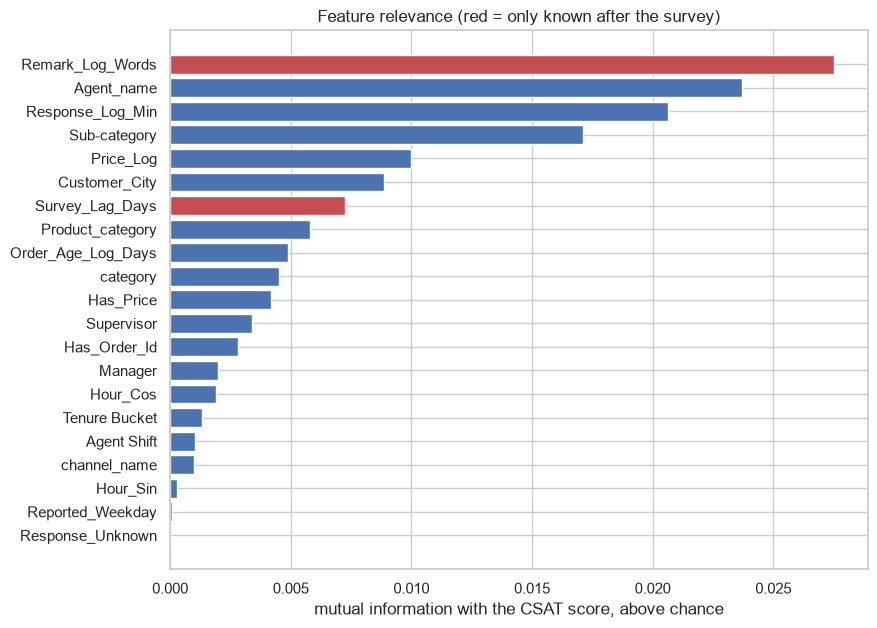

Remark_Log_Words      0.0275
Agent_name            0.0237
Response_Log_Min      0.0206
Sub-category          0.0171
Price_Log             0.0100
Customer_City         0.0089
Survey_Lag_Days       0.0072
Product_category      0.0058
Order_Age_Log_Days    0.0049
category              0.0045
Has_Price             0.0042
Supervisor            0.0034
Has_Order_Id          0.0028
Manager               0.0020
Hour_Cos              0.0019
Tenure Bucket         0.0013
Agent Shift           0.0010
channel_name          0.0010
Hour_Sin              0.0003
Reported_Weekday      0.0001
Response_Unknown      0.0000

raw columns not used directly: ['Unique id', 'Order_id', 'connected_handling_time', 'order_date_time', 'Issue_reported at', 'issue_responded', 'Survey_response_Date', 'Item_price', 'Customer Remarks']


In [47]:
# Select your features wisely to avoid overfitting
# mutual information of every candidate feature with the CSAT score (categoricals as codes)
candidates = CAT_COLS + NUM_SURVEY
mi_x = df[candidates].copy()
mi_x[CAT_COLS] = OrdinalEncoder().fit_transform(mi_x[CAT_COLS])
discrete = [c in CAT_COLS for c in candidates]
mi_raw = mutual_info_classif(mi_x, df["CSAT"], discrete_features=discrete, random_state=SEED)
# columns with many categories get a high score even by chance, so subtract the score against a shuffled target
mi_null = mutual_info_classif(mi_x, df["CSAT"].sample(frac=1, random_state=SEED).to_numpy(), discrete_features=discrete,
                              random_state=SEED)
mi = pd.Series(mi_raw - mi_null, index=candidates).sort_values()
print("chance level that was subtracted, largest:", pd.Series(mi_null, index=candidates).sort_values(ascending=False).head(3).round(4).to_dict())
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(mi.index, mi.values, color=["#C44E52" if c in ["Survey_Lag_Days", "Remark_Log_Words"] else "#4C72B0" for c in mi.index])
ax.set_xlabel("mutual information with the CSAT score, above chance")
ax.set_title("Feature relevance (red = only known after the survey)")
save_fig(fig, "feature_mutual_information")
plt.show()
print(mi.sort_values(ascending=False).round(4).to_string())
dropped = ["Unique id", "Order_id", "connected_handling_time", "order_date_time", "Issue_reported at", "issue_responded",
           "Survey_response_Date", "Item_price", "Customer Remarks"]
print("\nraw columns not used directly:", dropped)

##### What all feature selection methods have you used  and why?

I combined three methods:
- Domain logic about what is known when. The real-time model only gets features that exist while the contact is being handled. The survey lag, the remark length and the remark text exist only after the customer answers the survey, so they only go into the second model. This prevents a model that looks great in testing but can't be used live.
- A correlation check (|Spearman| > 0.9) for near copies. Has_Order_Date was identical to Has_Price (1.0), so I dropped it, and Has_Remark was almost the same as the remark length (0.97). The raw minutes, price and word counts were replaced by their log versions.
- Mutual information of each feature with the score, minus the score it gets against a shuffled target. Columns with many categories (agent, city) get a high mutual information even by chance, so subtracting the chance level makes the comparison fair.

Raw ids, the empty handling time and the raw date strings were left out.

##### Which all features you found important and why?

After removing the chance level, the most informative features are the remark length (0.028), the agent (0.024), the response time (0.021) and the sub-category (0.017), followed by the price, the city and the survey lag. The weekday and the hour carry almost nothing, which matches chart 7. The remark text itself is not in this list because it is not a single column. ML Model 3 shows that it is the strongest input of all. Every feature is weak alone, so the model has to combine them, which is a good case for a neural network with embeddings.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

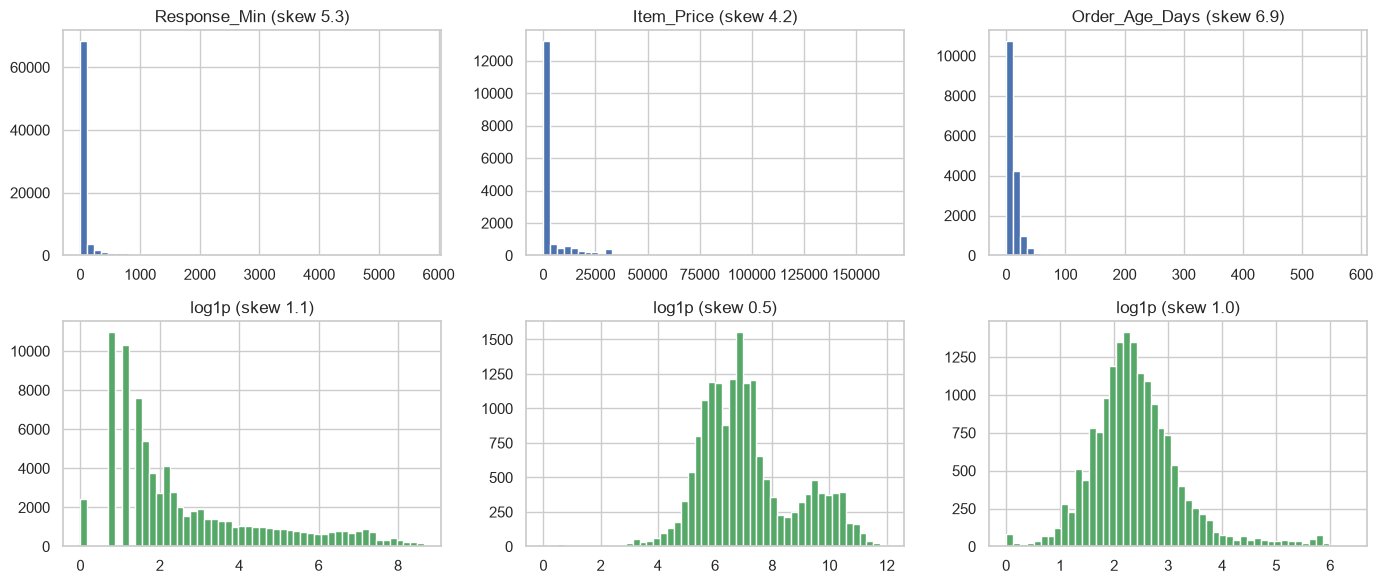

In [48]:
# Transform Your data
# the log1p transforms are done in make_features; here is their effect on the shape of the numbers
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for j, (col, log_col) in enumerate([("Response_Min", "Response_Log_Min"), ("Item_Price", "Price_Log"),
                                     ("Order_Age_Days", "Order_Age_Log_Days")]):
    s = df[col].dropna()
    axes[0, j].hist(s, bins=50, color="#4C72B0")
    axes[0, j].set_title(f"{col} (skew {s.skew():.1f})")
    axes[1, j].hist(np.log1p(s), bins=50, color="#55A868")
    axes[1, j].set_title(f"log1p (skew {np.log1p(s).skew():.1f})")
fig.tight_layout()
save_fig(fig, "transform_log1p")
plt.show()

Yes, for the skewed numbers. The response time (skewness 5.3), price (4.2), order age (6.9) and remark length (8.7) all have long right tails. I used log1p (the log of 1 + x), which works with zeros and brings the skewness down to about 0.5-1.1. Neural networks train better when inputs are on a similar, not too extreme scale. The hour is turned into sine and cosine so the model sees that 23:00 and 00:00 are close. The text is turned into word counts inside the model (section 6.4).

### 6. Data Scaling

In [49]:
# Scaling your data
# the networks scale the numbers with a Keras Normalization layer (mean 0, std 1) that learns the mean and
# standard deviation from the training rows only and is saved inside the model; the baseline uses StandardScaler
demo_norm = layers.Normalization()
demo_norm.adapt(df[NUM_SURVEY].astype("float32").to_numpy())
scaled = pd.DataFrame(demo_norm(df[NUM_SURVEY].astype("float32").to_numpy()).numpy(), columns=NUM_SURVEY)
pd.DataFrame({"mean before": df[NUM_SURVEY].mean(), "std before": df[NUM_SURVEY].std(),
              "mean after": scaled.mean().values, "std after": scaled.std().values}).round(3)

,mean before,std before,mean after,std after
Response_Log_Min,2.534,2.040,0.0,1.0
Response_Unknown,0.040,0.196,0.0,1.0
Hour_Sin,-0.305,0.635,0.0,1.0
Hour_Cos,-0.279,0.652,-0.0,1.0
Has_Order_Id,0.788,0.409,-0.0,1.0
Order_Age_Log_Days,0.480,1.033,-0.0,1.0
Has_Price,0.200,0.400,-0.0,1.0
Price_Log,1.429,2.950,-0.0,1.0
Survey_Lag_Days,0.121,0.433,-0.0,1.0
Remark_Log_Words,0.552,0.931,-0.0,1.0


##### Which method have you used to scale you data and why?

I used standardisation (mean 0, standard deviation 1), but inside the network: a Keras Normalization layer learns the mean and standard deviation of each numeric input from the training rows only, and it is saved as part of the model. This has two advantages: the validation and test rows never leak into the scaling, and the deployed model takes the raw numbers and scales them itself, so the app can't forget a step. The logistic regression baseline uses scikit-learn's StandardScaler for the same reason. Embeddings and the multi-hot text vector don't need scaling.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Not in the classic sense. The data has 21 input columns plus the remark, and the network handles that easily. The problem is the categorical columns with many values (1,371 agents, 1,783 cities), which would become very wide with one-hot encoding.

In [50]:
# DImensionality Reduction (If needed)
# no PCA: the embeddings already compress the large categorical columns into a few learned numbers
big = enc.sort_values("categories", ascending=False).head(4)
for col, r in big.iterrows():
    print(f"{col:16s}: {r['categories']:>5,} categories -> embedding of {r['embedding size']} numbers")
print(f"all inputs of the network: {enc['embedding size'].sum()} embedding numbers + {len(NUM_SURVEY)} numeric features"
      f" + the remark vector, instead of {enc['one-hot columns'].sum() + len(NUM_SURVEY):,} one-hot columns")

Agent_name      : 1,371 categories -> embedding of 24 numbers
Customer_City   :   175 categories -> embedding of 24 numbers
Sub-category    :    57 categories -> embedding of 16 numbers
Supervisor      :    40 categories -> embedding of 13 numbers
all inputs of the network: 111 embedding numbers + 10 numeric features + the remark vector, instead of 1,701 one-hot columns


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

Instead of PCA I used learned embeddings, which are a form of dimensionality reduction learned for the task itself: 1,691 one-hot columns become 111 embedding numbers. PCA was not needed, because it can't handle categories well and would lose the meaning of the inputs.

### 8. Data Splitting

In [51]:
# Split your data to train and test. Choose Splitting ratio wisely.
y = (df["CSAT"] - 1).to_numpy()                       # classes 0-4 = scores 1-5
idx = np.arange(len(df))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=y[temp_idx], random_state=SEED)
f_train, f_val, f_test = df.iloc[train_idx], df.iloc[val_idx], df.iloc[test_idx]
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]

split_table = pd.DataFrame({name: pd.Series(part + 1).value_counts(normalize=True).sort_index()
                            for name, part in [("train", y_train), ("validation", y_val), ("test", y_test)]}).round(3)
split_table.loc["rows"] = [len(y_train), len(y_val), len(y_test)]
split_table

,train,validation,test
1,0.131,0.131,0.131
2,0.015,0.015,0.015
3,0.030,0.030,0.030
4,0.131,0.131,0.131
5,0.694,0.694,0.694
rows,60134.000,12886.000,12887.000


##### What data splitting ratio have you used and why? 

I used a stratified random split of 70% training (60,134 rows), 15% validation (12,886) and 15% test (12,887). Stratified means each part has the same share of every score (69.4% fives, 1.5% twos and so on), which matters because score 2 is so rare. The validation rows are used for early stopping, for choosing the settings and the alert threshold, and the test rows only for the final scores. Because the data covers a single month and every row is a different contact (every Order_id is unique), a random split does not mix the same customer into training and test. I also checked a split in time (train on the first 3.5 weeks, test on the last week) in ML Model 3.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Yes, strongly. 69.4% of the scores are 5, and the smallest class (score 2) is only 1.5%, so the largest class is 46 times the smallest. A model that ignores the problem can always predict 5 and still be 69% accurate.

In [52]:
# Handling Imbalanced Dataset (If needed)
counts = np.bincount(y_train, minlength=5)


def class_weights(y_part, scheme):
    """'none', 'sqrt' (square root of balanced) or 'balanced' weights per class."""
    w = len(y_part) / (5 * np.bincount(y_part, minlength=5))
    w = {"none": np.ones(5), "sqrt": np.sqrt(w), "balanced": w}[scheme]
    return {k: float(v) for k, v in enumerate(w)}


weights_table = pd.DataFrame({"training rows": counts, "share": (counts / counts.sum()).round(3),
                              **{f"weight {s}": np.round(list(class_weights(y_train, s).values()), 2) for s in ["none", "sqrt", "balanced"]}},
                             index=[f"CSAT {k}" for k in range(1, 6)])
print(f"largest / smallest class: {counts.max() / counts.min():.0f} to 1")
weights_table

largest / smallest class: 46 to 1


,training rows,share,weight none,weight sqrt,weight balanced
CSAT 1,7861,0.131,1.0,1.24,1.53
CSAT 2,898,0.015,1.0,3.66,13.39
CSAT 3,1791,0.030,1.0,2.59,6.72
CSAT 4,7853,0.131,1.0,1.24,1.53
CSAT 5,41731,0.694,1.0,0.54,0.29


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

I did not oversample or delete rows. Instead I compared three class weight options during tuning: no weights, square root weights (a rare class counts more, but not fully balanced) and fully balanced weights, where a contact with score 2 gets a weight of 13.4 and a score 5 only 0.29 (46 times less). The tuning picks the option that gives the best low-CSAT alert on the validation rows. I also chose metrics that work with imbalance: macro F1 (every score counts equally), PR-AUC for the low-CSAT alert and the quadratic weighted kappa. Oversampling text and agent rows would create exact copies of rare contacts, which the network would just memorise.

## ***7. ML Model Implementation***

### ML Model - 1 - Baselines: majority class and logistic regression

In [53]:
# ML Model - 1 Implementation
LABELS = np.arange(1, 6)
PRIOR = np.bincount(y_train, minlength=5) / len(y_train)       # share of each score in the training rows


def evaluate(name, y_true, proba):
    """All the metrics used in this project, from the predicted probabilities of the 5 scores."""
    pred = proba.argmax(1)
    low_prob = proba[:, 0] + proba[:, 1]                          # probability of CSAT 1 or 2
    expected = (proba * LABELS).sum(1)                            # expected score, between 1 and 5
    return {"model": name,
            "accuracy": accuracy_score(y_true, pred),
            "macro F1": f1_score(y_true, pred, average="macro"),
            "weighted F1": f1_score(y_true, pred, average="weighted"),
            "QWK": cohen_kappa_score(y_true, pred, weights="quadratic"),
            "MAE (expected score)": mean_absolute_error(y_true + 1, expected),
            "low-CSAT ROC-AUC": roc_auc_score(y_true <= 1, low_prob),
            "low-CSAT PR-AUC": average_precision_score(y_true <= 1, low_prob)}


def baseline_pipeline(num_cols, with_text, C=1.0, weights=None):
    """One-hot categoricals + scaled numbers (+ TF-IDF of the remark) -> multinomial logistic regression."""
    parts = [("categories", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=MIN_CITY_COUNT), CAT_COLS),
             ("numbers", StandardScaler(), num_cols)]
    if with_text:
        parts.append(("remark", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=5000), TEXT_COL))
    return make_pipeline(ColumnTransformer(parts), LogisticRegression(C=C, max_iter=3000, class_weight=weights))


# majority class: always predict the most common score (5)
majority = np.tile(PRIOR, (len(y_test), 1))
results_1 = [evaluate("majority (always 5)", y_test, majority)]

lr_realtime = baseline_pipeline(NUM_REALTIME, False).fit(f_train, y_train)
lr_remarks = baseline_pipeline(NUM_SURVEY, True).fit(f_train, y_train)
results_1.append(evaluate("logistic regression, real time", y_test, lr_realtime.predict_proba(f_test)))
results_1.append(evaluate("logistic regression, with remarks", y_test, lr_remarks.predict_proba(f_test)))
scores_1 = pd.DataFrame(results_1).set_index("model")
scores_1.round(3)

,accuracy,macro F1,weighted F1,QWK,MAE (expected score),low-CSAT ROC-AUC,low-CSAT PR-AUC
model,,,,,,,
majority (always 5),0.694,0.164,0.569,0.000,1.052,0.500,0.146
"logistic regression, real time",0.696,0.202,0.594,0.134,0.961,0.720,0.317
"logistic regression, with remarks",0.726,0.261,0.643,0.385,0.819,0.813,0.537


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

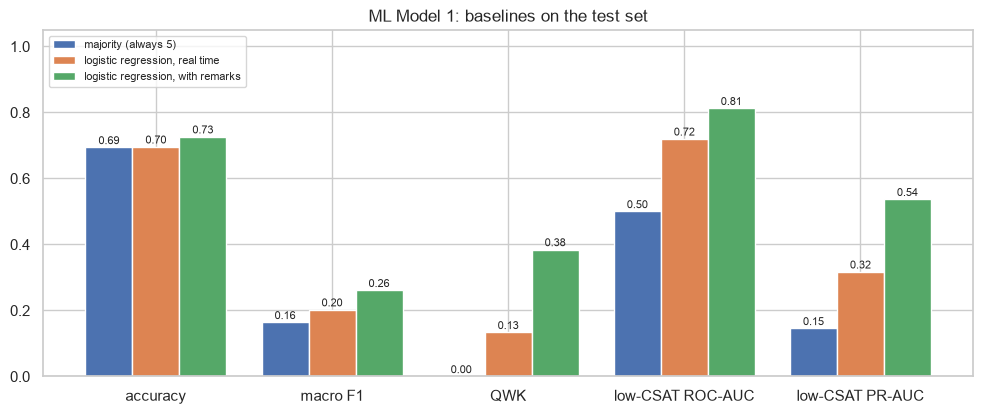

In [54]:
# Visualizing evaluation Metric Score chart
CHART_METRICS = ["accuracy", "macro F1", "QWK", "low-CSAT ROC-AUC", "low-CSAT PR-AUC"]


def plot_scores(table, title, name):
    """Grouped bars of the main metrics for each model in the table."""
    t = table[CHART_METRICS]
    fig, ax = plt.subplots(figsize=(12, 4.5))
    width = 0.8 / len(t)
    for i, (model_name, row) in enumerate(t.iterrows()):
        bars = ax.bar(np.arange(len(CHART_METRICS)) + i * width, row.values, width, label=model_name)
        for b, v in zip(bars, row.values):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
    ax.set_xticks(np.arange(len(CHART_METRICS)) + width * (len(t) - 1) / 2)
    ax.set_xticklabels(CHART_METRICS)
    ax.set_ylim(0, 1.05)
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper left")
    save_fig(fig, name)
    plt.show()


plot_scores(scores_1, "ML Model 1: baselines on the test set", "model1_scores_v1")

ML Model 1 is the baseline that the neural networks have to beat:
- **Majority class**: always predict a 5. It is 69.4% accurate, but has a macro F1 of 0.164 and can't find a single unhappy customer.
- **Multinomial logistic regression**: one-hot encoded categories, scaled numbers and, in the second version, TF-IDF of the remark. It is a linear model, so it adds up evidence from each feature but can't learn combinations.

The metrics, all on the test rows:
- accuracy and **macro F1** (the F1 of each score averaged, so the rare scores count as much as the 5s),
- the **quadratic weighted kappa (QWK)**, which gives partial credit for being close (predicting 4 for a 5 is better than predicting 1),
- the **MAE of the expected score** (the probability-weighted average score),
- and for the alert, the **ROC-AUC and PR-AUC of P(score 1 or 2)**. The PR-AUC is the most demanding one for a rare class: random guessing gives 0.146 here.

Without the remarks, logistic regression reaches a low-CSAT ROC-AUC of 0.720 and PR-AUC of 0.317. With the remarks it jumps to 0.813 and 0.537, and macro F1 goes from 0.202 to 0.261. So the remark text is by far the strongest single input.

#### 2. Cross- Validation & Hyperparameter Tuning

grid search: 9 settings x 3 folds in 16 s
 param_logisticregression__C param_logisticregression__class_weight  mean_test_score  std_test_score
                         1.0                                   None           0.5373          0.0125
                         3.0                                   None           0.5344          0.0131
                         0.3                                   None           0.5309          0.0119
                         0.3                                   sqrt           0.5222          0.0117
                         1.0                                   sqrt           0.5211          0.0115
                         3.0                                   sqrt           0.5141          0.0113
                         0.3                               balanced           0.4598          0.0071
                         1.0                               balanced           0.4552          0.0066
                         3.0                     

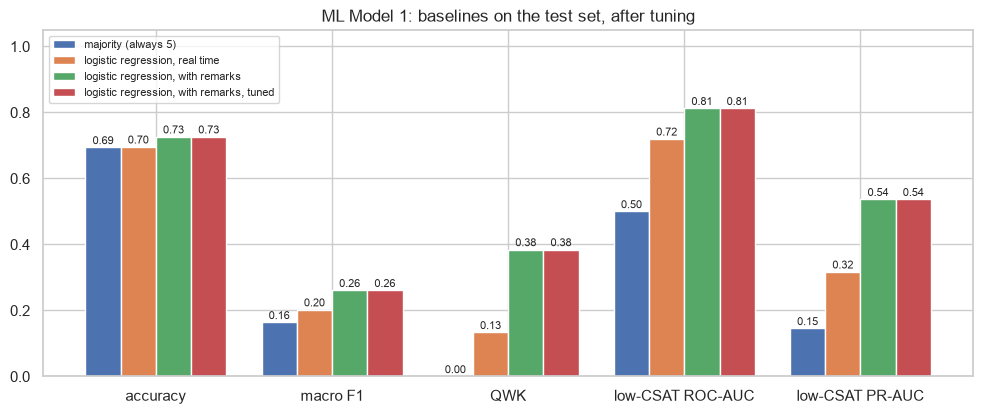

,accuracy,macro F1,weighted F1,QWK,MAE (expected score),low-CSAT ROC-AUC,low-CSAT PR-AUC
model,,,,,,,
majority (always 5),0.694,0.164,0.569,0.000,1.052,0.500,0.146
"logistic regression, real time",0.696,0.202,0.594,0.134,0.961,0.720,0.317
"logistic regression, with remarks",0.726,0.261,0.643,0.385,0.819,0.813,0.537
"logistic regression, with remarks, tuned",0.726,0.261,0.643,0.385,0.819,0.813,0.537


In [55]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# grid search with 3-fold stratified cross-validation on the training rows only, scored by the low-CSAT PR-AUC
# (the same metric used to tune the neural networks, so the comparison is fair)
from sklearn.metrics import make_scorer


def low_csat_pr_auc(y_true, proba):
    return average_precision_score(np.asarray(y_true) <= 1, proba[:, 0] + proba[:, 1])


sqrt_weights = class_weights(y_train, "sqrt")
grid = GridSearchCV(baseline_pipeline(NUM_SURVEY, True),
                    {"logisticregression__C": [0.3, 1.0, 3.0],
                     "logisticregression__class_weight": [None, sqrt_weights, "balanced"]},
                    scoring=make_scorer(low_csat_pr_auc, response_method="predict_proba"),
                    cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=-1)
t0 = time.time()
grid.fit(f_train, y_train)
cv_table = pd.DataFrame(grid.cv_results_)[["param_logisticregression__C", "param_logisticregression__class_weight",
                                           "mean_test_score", "std_test_score"]]
cv_table["param_logisticregression__class_weight"] = cv_table["param_logisticregression__class_weight"].map(
    lambda w: "sqrt" if isinstance(w, dict) else str(w))
print(f"grid search: {len(cv_table)} settings x 3 folds in {time.time() - t0:.0f} s")
print(cv_table.sort_values("mean_test_score", ascending=False).round(4).to_string(index=False))

best_lr = grid.best_estimator_
results_1.append(evaluate("logistic regression, with remarks, tuned", y_test, best_lr.predict_proba(f_test)))
scores_1 = pd.DataFrame(results_1).set_index("model")
plot_scores(scores_1, "ML Model 1: baselines on the test set, after tuning", "model1_scores_tuned")
scores_1.round(3)

##### Which hyperparameter optimization technique have you used and why?

GridSearchCV with 3-fold stratified cross-validation on the training rows: the regularisation strength C (0.3, 1, 3) and the class weights (none, square root, balanced), 9 settings x 3 folds. Every setting is scored by the low-CSAT PR-AUC, the same metric I use to tune the neural networks, so the comparison between the models is fair. Grid search is fine here because the model trains in seconds and there are only two parameters. Stratified folds keep the rare scores in every fold.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

No, and that is a useful result in itself. The grid search chose C = 1 with no class weights, which is the setting I started with (cross-validated PR-AUC 0.537 +- 0.013). Square-root weights scored 0.514-0.522 and balanced weights only 0.454-0.460, because the weights push the model to predict 1s and 2s too often and spoil the probabilities. So the tuned baseline is the same model as before, with the same test scores (accuracy 0.726, macro F1 0.261, QWK 0.385, ROC-AUC 0.813, PR-AUC 0.537). The baseline was already at its best, which makes it a strong and fair benchmark for the neural networks.

### ML Model - 2 - ANN for real-time prediction (no remarks)

In [56]:
# ML Model - 2 Implementation
def vocabulary(series, min_count=1):
    """Categories seen in the training rows (at least min_count times); everything else maps to one 'unknown' slot."""
    vc = series.value_counts()
    return sorted(vc[vc >= min_count].index.tolist())


def build_ann(cfg, num_cols, with_text, train_part):
    """Multi-input ANN: an embedding per categorical column + scaled numbers (+ a text branch for the remark)."""
    inputs, parts = {}, []
    for col in CAT_COLS:
        name = INPUT_NAMES[col]
        inp = keras.Input(shape=(1,), dtype="string", name=name)
        vocab = vocabulary(train_part[col], MIN_CITY_COUNT if col == "Customer_City" else 1)
        x = layers.StringLookup(vocabulary=vocab, num_oov_indices=1, name=f"lookup_{name}")(inp)
        x = layers.Embedding(len(vocab) + 1, embedding_dim(len(vocab) + 1), name=f"embed_{name}")(x)
        inputs[name] = inp
        parts.append(layers.Flatten(name=f"flat_{name}")(x))
    num_in = keras.Input(shape=(len(num_cols),), name="numeric")
    scaler = layers.Normalization(name="scale_numeric")
    scaler.adapt(train_part[num_cols].astype("float32").to_numpy())     # mean and std from training rows only
    inputs["numeric"] = num_in
    parts.append(scaler(num_in))
    if with_text:
        txt = keras.Input(shape=(), dtype="string", name="remark")
        words = layers.TextVectorization(max_tokens=int(cfg["text_tokens"]), output_mode="multi_hot", ngrams=2,
                                         standardize=None, name="remark_words")
        words.adapt(train_part[TEXT_COL].to_numpy())                   # vocabulary from training rows only
        t = layers.Dense(int(cfg["text_units"]), activation="relu", name="remark_dense")(words(txt))
        inputs["remark"] = txt
        parts.append(layers.Dropout(cfg["dropout"], name="remark_dropout")(t))
    x = layers.Concatenate(name="all_inputs")(parts)
    for i, units in enumerate(cfg["units"]):
        x = layers.Dense(int(units), activation="relu", kernel_regularizer=keras.regularizers.l2(cfg["l2"]), name=f"hidden_{i + 1}")(x)
        x = layers.BatchNormalization(name=f"batchnorm_{i + 1}")(x)
        x = layers.Dropout(cfg["dropout"], name=f"dropout_{i + 1}")(x)
    out = layers.Dense(5, activation="softmax", name="csat_probabilities")(x)
    model = keras.Model(inputs, out, name="csat_ann_with_remarks" if with_text else "csat_ann_realtime")
    model.compile(optimizer=keras.optimizers.Adam(cfg["lr"]), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def train_ann(cfg, num_cols, with_text, fit_part, y_fit, val_part, y_val_part):
    """Train with mini-batches, early stopping on the validation loss and a learning rate that halves on plateaus."""
    keras.utils.set_random_seed(SEED)
    model = build_ann(cfg, num_cols, with_text, fit_part)
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)]
    t0 = time.time()
    history = model.fit(model_inputs(fit_part, num_cols, with_text), y_fit,
                        validation_data=(model_inputs(val_part, num_cols, with_text), y_val_part),
                        epochs=60, batch_size=int(cfg["batch"]), class_weight=class_weights(y_fit, cfg["weights"]),
                        callbacks=callbacks, verbose=0)
    model.train_seconds = time.time() - t0
    return model, history


def predict(model, part, num_cols, with_text):
    return model.predict(model_inputs(part, num_cols, with_text), batch_size=4096, verbose=0)


CFG_V1 = {"units": (128, 64), "dropout": 0.2, "l2": 0.0, "lr": 1e-3, "batch": 256, "weights": "none",
          "text_tokens": 3000, "text_units": 64}
ann_rt_v1, hist_rt_v1 = train_ann(CFG_V1, NUM_REALTIME, False, f_train, y_train, f_val, y_val)
ann_rt_v1.summary(line_length=110)
print(f"trained {len(hist_rt_v1.history['loss'])} epochs in {ann_rt_v1.train_seconds:.0f} s")
results_2 = [evaluate("logistic regression, real time", y_test, lr_realtime.predict_proba(f_test)),
             evaluate("ANN real time v1", y_test, predict(ann_rt_v1, f_test, NUM_REALTIME, False))]
scores_2 = pd.DataFrame(results_2).set_index("model")
scores_2.round(3)

Model: "csat_ann_realtime"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                   ┃ Output Shape              ┃          Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ channel_name (InputLayer)      │ (None, 1)                 │                0 │ -                          │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ category (InputLayer)          │ (None, 1)                 │                0 │ -                          │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ sub_category (InputLayer)      │ (None, 1)                 │                0 │ -                          │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ customer_city (InputLayer)     │ (None, 1)                 │                0 │ -                          │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ product_category (InputLayer)  │ (None, 1)                 │                0 │ -                          │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ agent_name (InputLayer)        │ (None, 1)                 │                0 │ -                          │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ supervisor (InputLayer)        │ (None, 1)                 │                0 │ -                          │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ manager (InputLayer)           │ (None, 1)                 │                0 │ -                          │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ tenure_bucket (InputLayer)     │ (None, 1)                 │                0 │ -                          │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ agent_shift (InputLayer)       │ (None, 1)                 │                0 │ -                          │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ reported_weekday (InputLayer)  │ (None, 1)                 │                0 │ -                          │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ lookup_channel_name            │ (None, 1)                 │                0 │ channel_name[0][0]         │
│ (StringLookup)                 │                           │                  │                            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ lookup_category (StringLookup) │ (None, 1)                 │                0 │ category[0][0]             │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ lookup_sub_category            │ (None, 1)                 │                0 │ sub_category[0][0]         │
│ (StringLookup)                 │                           │                  │                            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ lookup_customer_city           │ (None, 1)                 │                0 │ customer_city[0][0]        │
│ (StringLookup)                 │                           │                  │                            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ lo

 Total params: 184,300 (719.93 KB)

 Trainable params: 61,299 (239.45 KB)

 Non-trainable params: 401 (1.57 KB)

 Optimizer params: 122,600 (478.91 KB)

trained 7 epochs in 5 s


,accuracy,macro F1,weighted F1,QWK,MAE (expected score),low-CSAT ROC-AUC,low-CSAT PR-AUC
model,,,,,,,
"logistic regression, real time",0.696,0.202,0.594,0.134,0.961,0.720,0.317
ANN real time v1,0.696,0.186,0.584,0.075,0.972,0.724,0.321


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

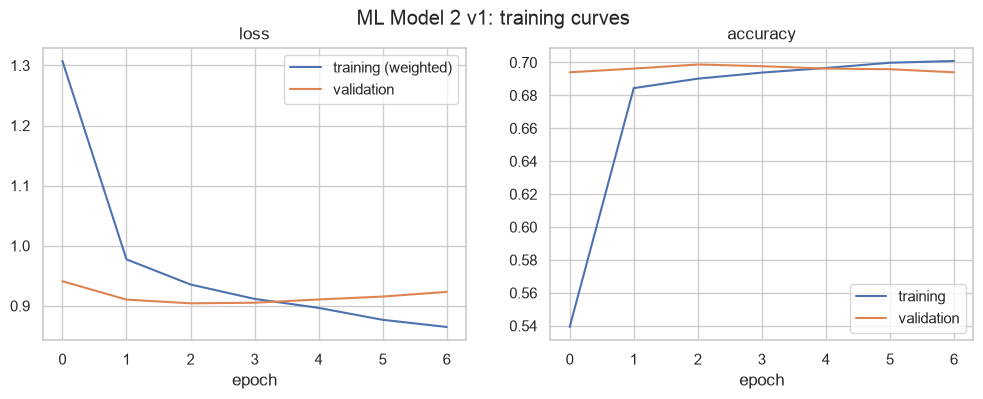

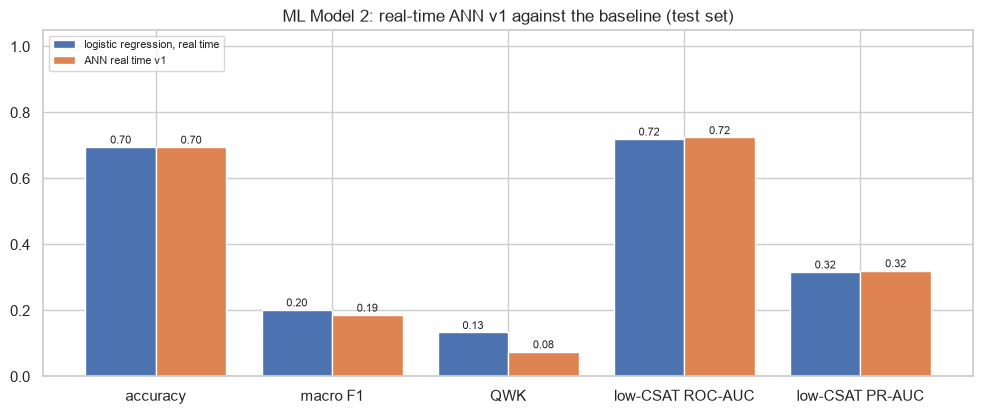

In [57]:
# Visualizing evaluation Metric Score chart
def plot_history(history, title, name):
    """Training and validation loss and accuracy per epoch."""
    h = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].plot(h["loss"], label="training (weighted)")
    axes[0].plot(h["val_loss"], label="validation")
    axes[0].set_title("loss")
    axes[1].plot(h["accuracy"], label="training")
    axes[1].plot(h["val_accuracy"], label="validation")
    axes[1].set_title("accuracy")
    for ax in axes:
        ax.set_xlabel("epoch")
        ax.legend()
    fig.suptitle(title)
    save_fig(fig, name)
    plt.show()


plot_history(hist_rt_v1, "ML Model 2 v1: training curves", "model2_history_v1")
plot_scores(scores_2, "ML Model 2: real-time ANN v1 against the baseline (test set)", "model2_scores_v1")

ML Model 2 is the **real-time ANN**. It uses only what is known while the contact is handled, so it can score a contact before the customer answers the survey.

Architecture (the same building blocks are used in ML Model 3):
- **Inputs**: 11 categorical columns (channel, category, sub-category, city, product, agent, supervisor, manager, tenure, shift, weekday) and 8 numbers (log response time, unknown-response flag, hour as sine and cosine, order flag, log order age, price flag, log price).
- **Entity embeddings**: each categorical column goes through a StringLookup and an Embedding layer, so every agent, city or sub-category gets a small learned vector (24 numbers for an agent instead of 1,371 one-hot columns).
- **Normalization layer** for the numbers, learned from the training rows and saved in the model.
- Everything is concatenated and goes through **dense hidden layers with ReLU**, each followed by **batch normalisation** (stable training) and **dropout** (against overfitting).
- **Output**: 5 units with **softmax**, the probability of each score. The predicted score is the most likely one, and the probability of 1 + 2 drives the alert.
- **Training**: Adam optimiser, sparse categorical cross-entropy, mini-batches of 256 or 512, **early stopping** on the validation loss (patience 4, the best weights are restored) and **ReduceLROnPlateau** (the learning rate halves when the validation loss stops improving).

Version 1 (2 hidden layers of 128 and 64, dropout 0.2, no class weights) trained in 7 epochs and 5 seconds. On the test rows it reached a low-CSAT ROC-AUC of 0.724 and PR-AUC of 0.321, already a bit better than the logistic regression on the same inputs (0.720 and 0.317), with a macro F1 of 0.186. The training curves show the validation loss bottoming out after a few epochs while the training loss keeps falling, which is why early stopping matters here.

#### 2. Cross- Validation & Hyperparameter Tuning

trial 1: macro F1 0.197, low-CSAT PR-AUC 0.230, 12 epochs, 8 s, units=(128, 64), dropout=0.4, l2=1e-05, lr=0.001, batch=256, weights=balanced


trial 2: macro F1 0.195, low-CSAT PR-AUC 0.234, 13 epochs, 6 s, units=(128, 64), dropout=0.4, l2=0.0, lr=0.001, batch=512, weights=balanced


trial 3: macro F1 0.203, low-CSAT PR-AUC 0.344, 10 epochs, 6 s, units=(256, 128, 64), dropout=0.4, l2=0.0001, lr=0.003, batch=512, weights=none


trial 4: macro F1 0.194, low-CSAT PR-AUC 0.222, 14 epochs, 11 s, units=(256, 128, 64), dropout=0.3, l2=1e-05, lr=0.001, batch=256, weights=balanced


trial 5: macro F1 0.229, low-CSAT PR-AUC 0.314, 12 epochs, 7 s, units=(256, 128, 64), dropout=0.3, l2=1e-05, lr=0.003, batch=512, weights=sqrt


...

trial 8: macro F1 0.188, low-CSAT PR-AUC 0.221, 10 epochs, 8 s, units=(256, 128, 64), dropout=0.3, l2=0.0, lr=0.003, batch=256, weights=balanced


trial 9: macro F1 0.231, low-CSAT PR-AUC 0.335, 12 epochs, 10 s, units=(256, 128, 64), dropout=0.4, l2=0.0001, lr=0.001, batch=256, weights=sqrt


trial 10: macro F1 0.212, low-CSAT PR-AUC 0.254, 8 epochs, 5 s, units=(256, 128), dropout=0.2, l2=1e-05, lr=0.001, batch=512, weights=balanced


trial 11: macro F1 0.198, low-CSAT PR-AUC 0.340, 8 epochs, 7 s, units=(256, 128, 64), dropout=0.4, l2=1e-05, lr=0.003, batch=256, weights=none


trial 12: macro F1 0.205, low-CSAT PR-AUC 0.346, 12 epochs, 7 s, units=(256, 128, 64), dropout=0.3, l2=0.0, lr=0.001, batch=512, weights=none

best setting on the validation rows: {'units': (256, 128, 64), 'dropout': np.float64(0.3), 'l2': np.float64(0.0), 'lr': np.float64(0.001), 'batch': np.int64(512), 'weights': 'none'}


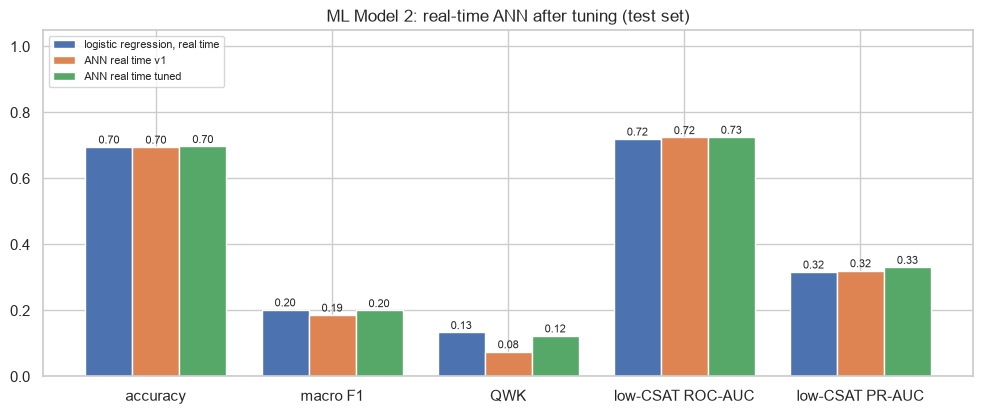

,accuracy,macro F1,weighted F1,QWK,MAE (expected score),low-CSAT ROC-AUC,low-CSAT PR-AUC
model,,,,,,,
"logistic regression, real time",0.696,0.202,0.594,0.134,0.961,0.720,0.317
ANN real time v1,0.696,0.186,0.584,0.075,0.972,0.724,0.321
ANN real time tuned,0.697,0.200,0.593,0.124,0.969,0.725,0.331


In [58]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# random search: sample settings from the grid below, train each on the training rows, score on the validation rows;
# the best setting has the highest low-CSAT PR-AUC (the alert metric), ties broken by macro F1
N_TRIALS = 12                                       # settings tried per model
SEARCH_SPACE = {"units": [(128, 64), (256, 128), (256, 128, 64)], "dropout": [0.2, 0.3, 0.4], "l2": [0.0, 1e-5, 1e-4],
                "lr": [1e-3, 3e-3], "batch": [256, 512], "weights": ["none", "sqrt", "balanced"]}


def random_search(num_cols, with_text, n_trials, extra_space=None):
    space = {**SEARCH_SPACE, **(extra_space or {})}
    rng = np.random.default_rng(SEED)
    trials = []
    for t in range(n_trials):
        cfg = {**CFG_V1, **{k: v[rng.integers(len(v))] for k, v in space.items()}}
        model, hist = train_ann(cfg, num_cols, with_text, f_train, y_train, f_val, y_val)
        m = evaluate(f"trial {t + 1}", y_val, predict(model, f_val, num_cols, with_text))
        trials.append({**{k: cfg[k] for k in space}, "epochs": len(hist.history["loss"]), "seconds": round(model.train_seconds),
                       **{k: m[k] for k in ["accuracy", "macro F1", "QWK", "low-CSAT PR-AUC"]}})
        print(f"trial {t + 1}: macro F1 {m['macro F1']:.3f}, low-CSAT PR-AUC {m['low-CSAT PR-AUC']:.3f}, "
              f"{trials[-1]['epochs']} epochs, {trials[-1]['seconds']} s, " + ", ".join(f"{k}={cfg[k]}" for k in space))
    return pd.DataFrame(trials)


trials_rt = random_search(NUM_REALTIME, False, n_trials=N_TRIALS)
best_rt = trials_rt.sort_values(["low-CSAT PR-AUC", "macro F1"], ascending=False).iloc[0]
CFG_RT = {**CFG_V1, **{k: best_rt[k] for k in SEARCH_SPACE}}
print("\nbest setting on the validation rows:", {k: CFG_RT[k] for k in SEARCH_SPACE})
ann_rt, hist_rt = train_ann(CFG_RT, NUM_REALTIME, False, f_train, y_train, f_val, y_val)
results_2.append(evaluate("ANN real time tuned", y_test, predict(ann_rt, f_test, NUM_REALTIME, False)))
scores_2 = pd.DataFrame(results_2).set_index("model")
plot_scores(scores_2, "ML Model 2: real-time ANN after tuning (test set)", "model2_scores_tuned")
scores_2.round(3)

##### Which hyperparameter optimization technique have you used and why?

Random search with 12 trials over the hidden layers ((128, 64), (256, 128) or (256, 128, 64)), dropout (0.2-0.4), L2 weight decay (0, 1e-5, 1e-4), learning rate (0.001, 0.003), batch size (256, 512) and class weights (none, square root, balanced). Each trial trains on the training rows with early stopping on the validation rows and is scored by the low-CSAT PR-AUC on the validation rows, with macro F1 as the tie-breaker. I used random search instead of a full grid because the full grid has 648 combinations, and random search finds a good region with far fewer trials. Each model trains in 5 to 11 seconds on the CPU, so the whole search takes about 1.5 minutes.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

A small but real improvement. The best setting has three hidden layers (256, 128, 64), dropout 0.3, learning rate 0.001, batch size 512 and no class weights. On the test rows the low-CSAT PR-AUC went from 0.321 to 0.331 and the ROC-AUC from 0.724 to 0.725, and macro F1 from 0.186 to 0.200. Compared with the logistic regression on the same inputs, the tuned ANN is better on the alert (PR-AUC 0.331 against 0.317, about 4% better), which comes from the agent and city embeddings.

The search also showed a clear pattern: every trial with fully balanced class weights had a PR-AUC between 0.217 and 0.254, against 0.314-0.346 for no weights or square-root weights. Balanced weights make the model predict 1s and 2s so often that the probabilities stop being useful.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

- **Low-CSAT PR-AUC and ROC-AUC**: how well the model ranks the unhappy customers above the happy ones. This is what the support team uses: a high value means the alert list is mostly real problems. I picked the PR-AUC as the main tuning metric because it focuses on the rare unhappy customers and does not need a threshold.
- **Precision and recall of the alert**: precision says how many alerts are real (wasted call-backs otherwise), recall says how many unhappy customers are caught.
- **Macro F1**: shows whether the model can tell all five scores apart, not just the 5s.
- **QWK and the MAE of the expected score**: how close the predicted score is to the real one, which matters for reporting an expected CSAT per team or day.
- **Accuracy**: reported, but misleading here because always predicting 5 gives 69.4%.

The business impact of the real-time model is that it scores every contact as soon as it is answered. The alert at its best threshold (section 4 below) flags 29% of contacts and catches 57% of the customers who will give a 1 or 2, with twice the precision of random checks, so a supervisor can call those customers back before the survey.

### ML Model - 3 - ANN with the customer remarks (text branch)

In [59]:
# ML Model - 3 Implementation
ann_rm_v1, hist_rm_v1 = train_ann(CFG_V1, NUM_SURVEY, True, f_train, y_train, f_val, y_val)
print(f"trained {len(hist_rm_v1.history['loss'])} epochs in {ann_rm_v1.train_seconds:.0f} s, "
      f"{ann_rm_v1.count_params():,} parameters")
results_3 = [evaluate("logistic regression, with remarks, tuned", y_test, best_lr.predict_proba(f_test)),
             evaluate("ANN real time tuned", y_test, predict(ann_rt, f_test, NUM_REALTIME, False)),
             evaluate("ANN with remarks v1", y_test, predict(ann_rm_v1, f_test, NUM_SURVEY, True))]
scores_3 = pd.DataFrame(results_3).set_index("model")
scores_3.round(3)

trained 7 epochs in 8 s, 262,216 parameters


,accuracy,macro F1,weighted F1,QWK,MAE (expected score),low-CSAT ROC-AUC,low-CSAT PR-AUC
model,,,,,,,
"logistic regression, with remarks, tuned",0.726,0.261,0.643,0.385,0.819,0.813,0.537
ANN real time tuned,0.697,0.200,0.593,0.124,0.969,0.725,0.331
ANN with remarks v1,0.727,0.261,0.643,0.387,0.804,0.811,0.536


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

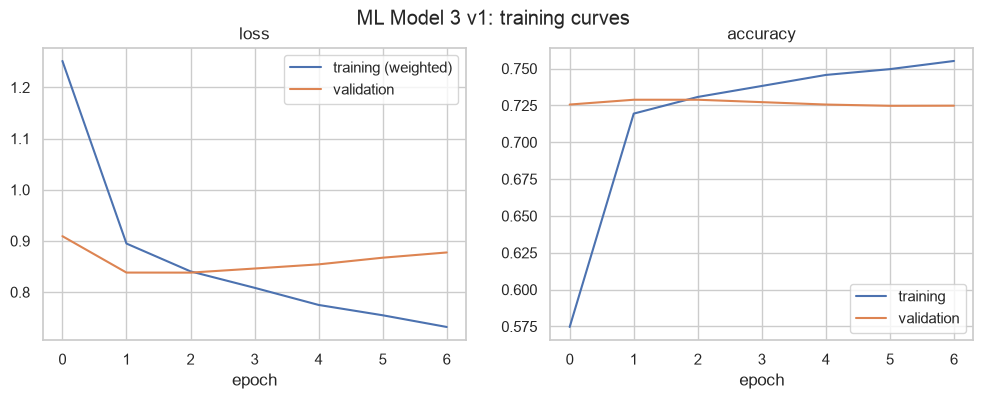

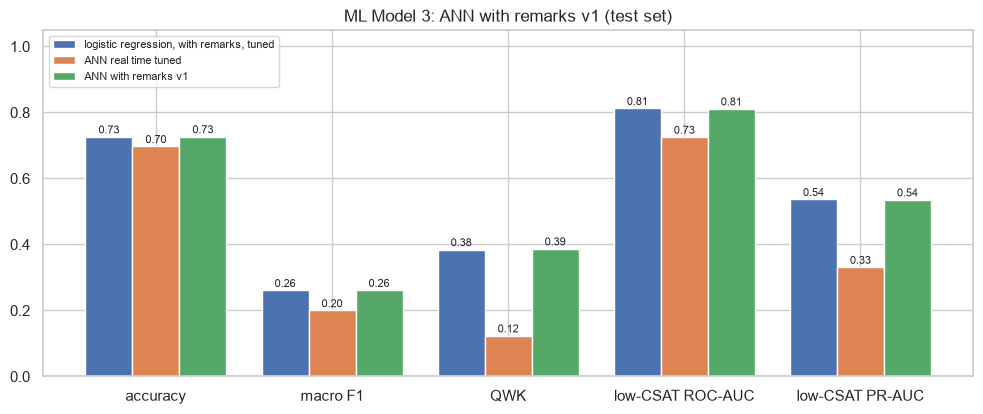

In [60]:
# Visualizing evaluation Metric Score chart
plot_history(hist_rm_v1, "ML Model 3 v1: training curves", "model3_history_v1")
plot_scores(scores_3, "ML Model 3: ANN with remarks v1 (test set)", "model3_scores_v1")

ML Model 3 is the **ANN with the customer remarks**. It is the same network as ML Model 2 with a **text branch** added: the cleaned remark goes through a TextVectorization layer (multi-hot vector of words and word pairs) and a dense layer with ReLU, and that output is concatenated with the embeddings and the numbers. It also gets the survey lag and the remark length. Because the remark only exists after the survey, this model is for analysis after the fact, for example to find out which survey answers point to a service failure, or to score customers who wrote a complaint but gave no score.

Version 1 (the same settings as before) trained in 7 epochs and 8 seconds and has 262,216 parameters. On the test rows it reached accuracy 0.727, macro F1 0.261, QWK 0.387 and a low-CSAT ROC-AUC of 0.811 and PR-AUC of 0.536. That is a big step up from the real-time model (PR-AUC 0.331), which shows how much the remark tells about the score. It is at the same level as the logistic regression with remarks.

#### 2. Cross- Validation & Hyperparameter Tuning

trial 1: macro F1 0.249, low-CSAT PR-AUC 0.481, 13 epochs, 13 s, units=(128, 64), dropout=0.4, l2=1e-05, lr=0.001, batch=256, weights=balanced, text_tokens=2000, text_units=128


trial 2: macro F1 0.268, low-CSAT PR-AUC 0.480, 11 epochs, 11 s, units=(128, 64), dropout=0.2, l2=1e-05, lr=0.003, batch=512, weights=balanced, text_tokens=5000, text_units=128


trial 3: macro F1 0.274, low-CSAT PR-AUC 0.531, 9 epochs, 8 s, units=(256, 128), dropout=0.2, l2=0.0001, lr=0.001, batch=512, weights=sqrt, text_tokens=2000, text_units=128


trial 4: macro F1 0.269, low-CSAT PR-AUC 0.528, 10 epochs, 8 s, units=(256, 128, 64), dropout=0.3, l2=1e-05, lr=0.003, batch=512, weights=sqrt, text_tokens=2000, text_units=32


trial 5: macro F1 0.258, low-CSAT PR-AUC 0.482, 12 epochs, 8 s, units=(128, 64), dropout=0.3, l2=0.0001, lr=0.001, batch=512, weights=balanced, text_tokens=2000, text_units=64


...

trial 9: macro F1 0.275, low-CSAT PR-AUC 0.517, 9 epochs, 10 s, units=(256, 128), dropout=0.2, l2=0.0001, lr=0.001, batch=256, weights=sqrt, text_tokens=5000, text_units=32


trial 10: macro F1 0.258, low-CSAT PR-AUC 0.544, 6 epochs, 10 s, units=(256, 128), dropout=0.2, l2=0.0001, lr=0.001, batch=256, weights=none, text_tokens=5000, text_units=128


trial 11: macro F1 0.256, low-CSAT PR-AUC 0.465, 13 epochs, 10 s, units=(256, 128, 64), dropout=0.3, l2=0.0, lr=0.003, batch=512, weights=balanced, text_tokens=2000, text_units=32


trial 12: macro F1 0.270, low-CSAT PR-AUC 0.533, 11 epochs, 10 s, units=(256, 128, 64), dropout=0.4, l2=1e-05, lr=0.003, batch=512, weights=sqrt, text_tokens=5000, text_units=32

best setting on the validation rows: {'units': (256, 128, 64), 'dropout': np.float64(0.4), 'l2': np.float64(0.0001), 'lr': np.float64(0.001), 'batch': np.int64(256), 'weights': 'sqrt', 'text_tokens': np.int64(2000), 'text_units': np.int64(32)}



5-fold cross-validation:
        accuracy  macro F1    QWK  low-CSAT ROC-AUC  low-CSAT PR-AUC
model                                                               
fold 1     0.724     0.269  0.429             0.810            0.548
fold 2     0.718     0.268  0.425             0.811            0.544
fold 3     0.725     0.269  0.430             0.810            0.548
fold 4     0.721     0.266  0.416             0.813            0.538
fold 5     0.719     0.261  0.395             0.806            0.531
mean +- std: {'accuracy': '0.721 +- 0.003', 'macro F1': '0.266 +- 0.003', 'QWK': '0.419 +- 0.014', 'low-CSAT ROC-AUC': '0.810 +- 0.002', 'low-CSAT PR-AUC': '0.542 +- 0.007'}


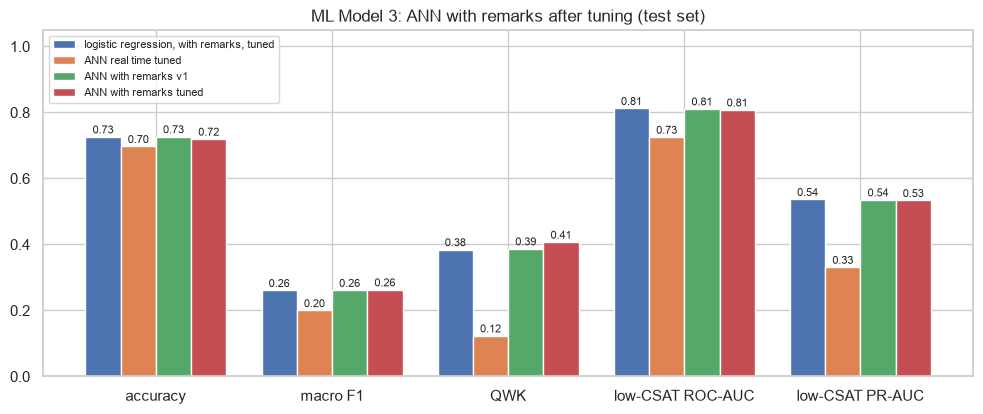

,accuracy,macro F1,weighted F1,QWK,MAE (expected score),low-CSAT ROC-AUC,low-CSAT PR-AUC
model,,,,,,,
"logistic regression, with remarks, tuned",0.726,0.261,0.643,0.385,0.819,0.813,0.537
ANN real time tuned,0.697,0.200,0.593,0.124,0.969,0.725,0.331
ANN with remarks v1,0.727,0.261,0.643,0.387,0.804,0.811,0.536
ANN with remarks tuned,0.720,0.263,0.642,0.407,0.996,0.808,0.534


In [61]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# 1) random search, now also over the size of the text branch
trials_rm = random_search(NUM_SURVEY, True, n_trials=N_TRIALS,
                          extra_space={"text_tokens": [2000, 5000], "text_units": [32, 64, 128]})
best_rm = trials_rm.sort_values(["low-CSAT PR-AUC", "macro F1"], ascending=False).iloc[0]
CFG_RM = {**CFG_V1, **{k: best_rm[k] for k in list(SEARCH_SPACE) + ["text_tokens", "text_units"]}}
print("\nbest setting on the validation rows:", CFG_RM)

# 2) 5-fold stratified cross-validation of the chosen setting on train + validation, to check it generalises
cv_rows = np.concatenate([train_idx, val_idx])
cv_scores = []
for k, (fit_i, hold_i) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED).split(cv_rows, y[cv_rows])):
    fit_part, hold_part = df.iloc[cv_rows[fit_i]], df.iloc[cv_rows[hold_i]]
    m, _ = train_ann(CFG_RM, NUM_SURVEY, True, fit_part, y[cv_rows[fit_i]], hold_part, y[cv_rows[hold_i]])
    cv_scores.append(evaluate(f"fold {k + 1}", y[cv_rows[hold_i]], predict(m, hold_part, NUM_SURVEY, True)))
cv_scores = pd.DataFrame(cv_scores).set_index("model")
print("\n5-fold cross-validation:")
print(cv_scores[CHART_METRICS].round(3).to_string())
print("mean +- std:", {c: f"{cv_scores[c].mean():.3f} +- {cv_scores[c].std():.3f}" for c in CHART_METRICS})

# 3) final model on the training rows, early stopping on the validation rows, scored once on the test rows
ann_rm, hist_rm = train_ann(CFG_RM, NUM_SURVEY, True, f_train, y_train, f_val, y_val)
results_3.append(evaluate("ANN with remarks tuned", y_test, predict(ann_rm, f_test, NUM_SURVEY, True)))
scores_3 = pd.DataFrame(results_3).set_index("model")
plot_scores(scores_3, "ML Model 3: ANN with remarks after tuning (test set)", "model3_scores_tuned")
scores_3.round(3)

##### Which hyperparameter optimization technique have you used and why?

Three steps:
1. **Random search** with 12 trials, the same space as ML Model 2 plus the size of the text branch (2,000 or 5,000 words and pairs, 32, 64 or 128 units), scored by the low-CSAT PR-AUC on the validation rows.
2. **5-fold stratified cross-validation** of the chosen setting on the training and validation rows together, to check that the result is stable and not the luck of one split. Each fold uses its own held-out part for early stopping and scoring.
3. A final model trained on the training rows, with early stopping on the validation rows, scored once on the test rows.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

The best setting on the validation rows has three hidden layers (256, 128, 64), dropout 0.4, L2 1e-4, learning rate 0.001, batch size 256, square-root class weights and a small text branch (2,000 words and pairs, 32 units). The 5-fold cross-validation gave very stable results: accuracy 0.721 +- 0.003, macro F1 0.266 +- 0.003, QWK 0.419 +- 0.014, ROC-AUC 0.810 +- 0.002 and PR-AUC 0.542 +- 0.007, so the model generalises the same way on every part of the data.

On the test rows the tuned model improved the score prediction (QWK 0.387 to 0.407, macro F1 0.261 to 0.263), while the alert stayed at the same level (PR-AUC 0.536 to 0.534 and ROC-AUC 0.811 to 0.808, both inside the spread of the cross-validation). So tuning did not make a real difference for this model. The square-root class weights move the expected score away from 5 (MAE 0.80 to 1.00), because the rare low scores get more weight. Most of the predictive power comes from the inputs, especially the remark, and not from the settings.

#### 3. Where does the model go wrong? Confusion matrix and errors by group

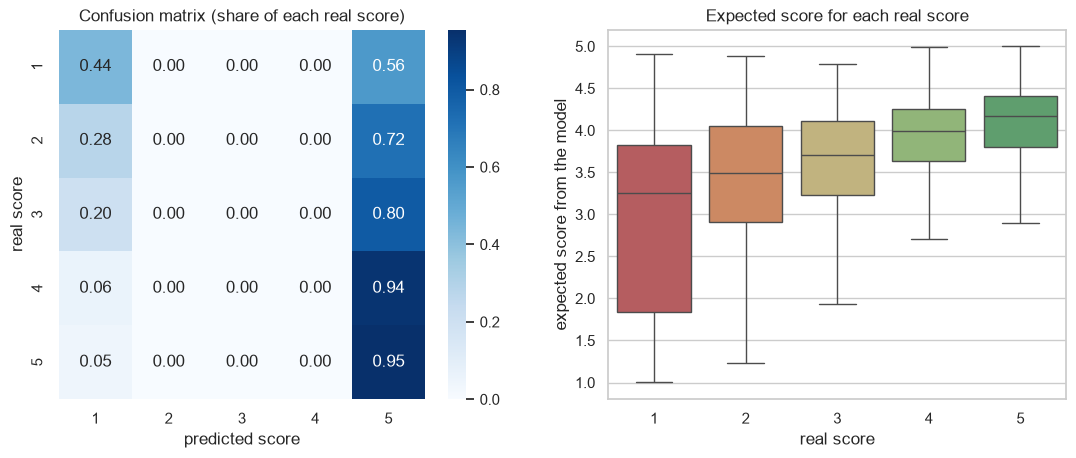

F1 per score: {np.int64(1): np.float64(0.481), np.int64(2): np.float64(0.0), np.int64(3): np.float64(0.0), np.int64(4): np.float64(0.0), np.int64(5): np.float64(0.835)}
exactly right 72.0%, off by 1 12.7%, off by 2+ 15.4%


,group,rows,low CSAT %,PR-AUC with remarks,PR-AUC real time
0,has remark: no remark,8584,11.9,0.252,0.265
1,has remark: with remark,4303,19.9,0.755,0.451
2,channel_name: Email,456,24.1,0.632,0.460
3,channel_name: Inbound,10185,14.3,0.520,0.320
4,channel_name: Outcall,2246,13.9,0.556,0.338
5,Response_Bucket: 0-5 min,6085,8.7,0.428,0.191
6,Response_Bucket: 5-30 min,2967,15.4,0.488,0.293
7,Response_Bucket: 30 min-2 h,1235,20.3,0.561,0.358
8,Response_Bucket: 2 h-1 day,1663,24.8,0.601,0.394
9,Response_Bucket: over 1 day,432,37.7,0.720,0.546


In [62]:
# confusion matrix of the final model, and how the errors are spread
proba_rm_test = predict(ann_rm, f_test, NUM_SURVEY, True)
proba_rt_test = predict(ann_rt, f_test, NUM_REALTIME, False)
pred_rm_test = proba_rm_test.argmax(1)
cm = confusion_matrix(y_test, pred_rm_test, normalize="true")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=axes[0])
axes[0].set_xlabel("predicted score")
axes[0].set_ylabel("real score")
axes[0].set_title("Confusion matrix (share of each real score)")
expected_test = (proba_rm_test * LABELS).sum(1)
sns.boxplot(x=y_test + 1, y=expected_test, palette=CSAT_COLORS, showfliers=False, ax=axes[1])
axes[1].set_xlabel("real score")
axes[1].set_ylabel("expected score from the model")
axes[1].set_title("Expected score for each real score")
save_fig(fig, "model3_confusion_matrix")
plt.show()
print("F1 per score:", dict(zip(LABELS, np.round(f1_score(y_test, pred_rm_test, average=None), 3))))
off_by = np.abs(pred_rm_test - y_test)
print(f"exactly right {np.mean(off_by == 0):.1%}, off by 1 {np.mean(off_by == 1):.1%}, off by 2+ {np.mean(off_by >= 2):.1%}")

# error by group: does the model work equally well for every channel, remark/no remark and response time?
err = f_test[["channel_name", "category", "Response_Bucket"]].copy()
err["has remark"] = np.where(f_test["Has_Remark"] == 1, "with remark", "no remark")
err["y"], err["p_low_rm"], err["p_low_rt"] = y_test, proba_rm_test[:, :2].sum(1), proba_rt_test[:, :2].sum(1)
rows = []
for col in ["has remark", "channel_name", "Response_Bucket"]:
    for g, part in err.groupby(col, observed=True):
        if part["y"].le(1).sum() >= 30:
            rows.append({"group": f"{col}: {g}", "rows": len(part), "low CSAT %": round(part["y"].le(1).mean() * 100, 1),
                         "PR-AUC with remarks": round(average_precision_score(part["y"] <= 1, part["p_low_rm"]), 3),
                         "PR-AUC real time": round(average_precision_score(part["y"] <= 1, part["p_low_rt"]), 3)})
pd.DataFrame(rows)

**Common error patterns:**
- The model is right on 72.0% of the test contacts, off by one point on 12.7% and off by two or more on 15.4%.
- The F1 for score 5 is 0.835 and for score 1 is 0.481, but scores 2, 3 and 4 are almost never predicted (F1 0). These middle scores are rare and their contacts look the same as the 5s and the 1s: a customer who gives a 4 usually had the same quick, normal contact as one who gives a 5. The box plot shows that the expected score still moves in the right direction for every real score, so the model knows the order even when the exact score is wrong.
- The biggest group of errors is unhappy customers who wrote nothing and had a quick, normal contact. Without a remark, the alert's PR-AUC is 0.252. With a remark it is 0.755.
- The model works better when there is more to go on. For contacts that waited over a day the PR-AUC is 0.720, against 0.428 for contacts answered within 5 minutes. For email it is 0.632 against 0.520 for inbound calls.

So the model is reliable for finding clearly unhappy customers and for ranking contacts by risk, but it should not be used to tell a 4 from a 5.

#### 4. The low-CSAT alert: choosing the threshold

threshold with the best F1 on validation: with remarks 0.35, real time 0.2


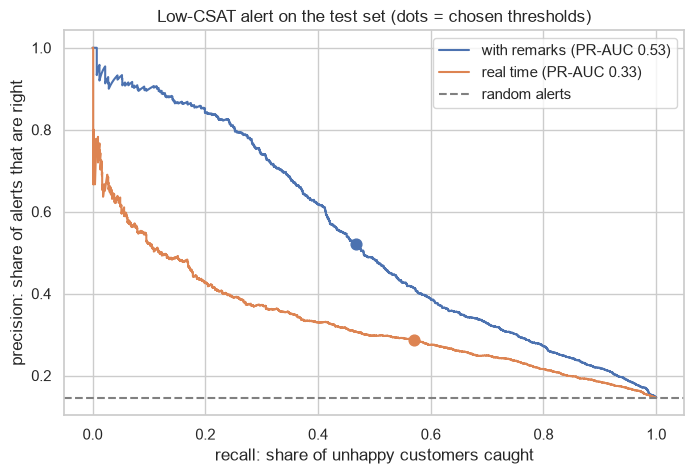

,threshold,alerts %,precision,recall,F1
model,,,,,
with remarks,0.35,13.075,0.520,0.467,0.492
real time,0.20,29.068,0.286,0.571,0.381


In [63]:
# the alert fires when P(CSAT 1 or 2) is above a threshold; the threshold is chosen on the validation rows
def alert_table(p_low, y_true, thresholds):
    rows = []
    for t in thresholds:
        flag = p_low >= t
        rows.append({"threshold": t, "alerts %": flag.mean() * 100,
                     "precision": precision_score(y_true <= 1, flag, zero_division=0),
                     "recall": recall_score(y_true <= 1, flag), "F1": f1_score(y_true <= 1, flag)})
    return pd.DataFrame(rows)


grid_t = np.round(np.arange(0.10, 0.71, 0.05), 2)
val_low_rm = predict(ann_rm, f_val, NUM_SURVEY, True)[:, :2].sum(1)
val_low_rt = predict(ann_rt, f_val, NUM_REALTIME, False)[:, :2].sum(1)
THRESHOLD_RM = float(alert_table(val_low_rm, y_val, grid_t).sort_values("F1").iloc[-1]["threshold"])
THRESHOLD_RT = float(alert_table(val_low_rt, y_val, grid_t).sort_values("F1").iloc[-1]["threshold"])
print(f"threshold with the best F1 on validation: with remarks {THRESHOLD_RM}, real time {THRESHOLD_RT}")

fig, ax = plt.subplots(figsize=(8, 5))
for name, p, t, color in [("with remarks", proba_rm_test[:, :2].sum(1), THRESHOLD_RM, "#4C72B0"),
                          ("real time", proba_rt_test[:, :2].sum(1), THRESHOLD_RT, "#DD8452")]:
    prec, rec, thr = precision_recall_curve(y_test <= 1, p)
    ax.plot(rec, prec, color=color, label=f"{name} (PR-AUC {average_precision_score(y_test <= 1, p):.2f})")
    flag = p >= t
    ax.scatter(recall_score(y_test <= 1, flag), precision_score(y_test <= 1, flag), color=color, s=60, zorder=3)
ax.axhline((y_test <= 1).mean(), color="grey", ls="--", label="random alerts")
ax.set_xlabel("recall: share of unhappy customers caught")
ax.set_ylabel("precision: share of alerts that are right")
ax.set_title("Low-CSAT alert on the test set (dots = chosen thresholds)")
ax.legend()
save_fig(fig, "alert_precision_recall")
plt.show()
test_alerts = pd.concat([alert_table(proba_rm_test[:, :2].sum(1), y_test, [THRESHOLD_RM]).assign(model="with remarks"),
                         alert_table(proba_rt_test[:, :2].sum(1), y_test, [THRESHOLD_RT]).assign(model="real time")])
test_alerts.set_index("model").round(3)

The alert threshold is the probability of a 1 or 2 above which a contact is flagged. I chose it on the validation rows with the best F1 for the low-CSAT class, and then checked it once on the test rows:

| Model | Threshold | Contacts flagged | Precision | Recall |
|---|---|---|---|---|
| Real time | 0.20 | 29.1% | 0.286 | 0.571 |
| With remarks | 0.35 | 13.1% | 0.520 | 0.467 |

The real-time alert catches 57% of the unhappy customers while checking 29% of the contacts, and its precision (0.286) is about twice the 14.6% base rate. With the remark the alert is much sharper: half of the alerts are real. The threshold is a business choice. A lower one catches more unhappy customers but costs more call-backs, and the precision-recall curve shows that trade-off. In the app the threshold is stored with the model.

#### 5. Does it hold up on later weeks? A time-based check

In [64]:
# train on surveys up to 24 Aug, test on the last week (25-31 Aug), as it would run in production
early = (df["Survey"] <= "2023-08-24").to_numpy()
late_idx = np.where(~early)[0]
early_idx = np.where(early)[0]
fit_i, stop_i = train_test_split(early_idx, test_size=0.15, stratify=y[early_idx], random_state=SEED)
time_rows = []
for name, cfg, cols, text in [("ANN real time", CFG_RT, NUM_REALTIME, False), ("ANN with remarks", CFG_RM, NUM_SURVEY, True)]:
    m, _ = train_ann(cfg, cols, text, df.iloc[fit_i], y[fit_i], df.iloc[stop_i], y[stop_i])
    p_late = predict(m, df.iloc[late_idx], cols, text)
    time_rows.append(evaluate(f"{name}, last week", y[late_idx], p_late))
    known = df.iloc[late_idx]["Response_Unknown"].to_numpy() == 0       # without the 28 Aug rows that lost their reply time
    time_rows.append(evaluate(f"{name}, last week, known response time", y[late_idx][known], p_late[known]))
time_rows += [r for r in results_3 if r["model"] in ("ANN real time tuned", "ANN with remarks tuned")]
print(f"training weeks: {early.sum():,} rows ({int(df.iloc[early_idx]['Response_Unknown'].sum())} with unknown response time), "
      f"last week: {len(late_idx):,} rows ({int(df.iloc[late_idx]['Response_Unknown'].sum()):,} with unknown response time)")
pd.DataFrame(time_rows).set_index("model")[CHART_METRICS].round(3)

training weeks: 65,202 rows (32 with unknown response time), last week: 20,705 rows (3,410 with unknown response time)


,accuracy,macro F1,QWK,low-CSAT ROC-AUC,low-CSAT PR-AUC
model,,,,,
"ANN real time, last week",0.712,0.184,0.059,0.651,0.251
"ANN real time, last week, known response time",0.712,0.187,0.069,0.706,0.274
"ANN with remarks, last week",0.715,0.254,0.359,0.782,0.468
"ANN with remarks, last week, known response time",0.712,0.257,0.375,0.798,0.491
ANN real time tuned,0.697,0.200,0.124,0.725,0.331
ANN with remarks tuned,0.720,0.263,0.407,0.808,0.534


In production the model is trained on past weeks and used on new ones, so I retrained both networks on the surveys up to 24 August and tested them on the last week (25-31 August, 20,705 contacts):
- The real-time model dropped from a ROC-AUC of 0.725 (random split) to 0.651 on the last week, and the remarks model from 0.808 to 0.782.
- Most of this drop is the logging problem of 28 August. That week holds 3,410 of the contacts with an unknown response time, while the training weeks have only 32, so the model never learned what to do without the response time. Without those rows the real-time model is at 0.706 and the remarks model at 0.798.
- The rest (0.706 against 0.725) is a small real drift between weeks.

So the models hold up on future weeks, but they depend on clean response times, and they should be retrained regularly (for example every week or month) and monitored. In a real setup a missing response time should raise a data-quality warning instead of being scored silently.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

- **For the alert (the main business use): the low-CSAT PR-AUC**, with ROC-AUC, precision and recall. An unhappy customer who is not found is a lost chance to save the relationship, and a false alert costs a call-back, so the ranking quality of the unhappy customers is what counts. The PR-AUC focuses on the 14.6% rare class, where accuracy and even ROC-AUC look too optimistic.
- **For the score itself: macro F1 and QWK**. Macro F1 gives every score the same weight, so a model that only predicts 5 can't look good. QWK rewards predictions that are close to the real score, which fits an ordered 1-5 scale.
- **Accuracy** only as a sanity check against the 69.4% of always predicting 5.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

I keep two final models, because they answer two different questions:
- **The tuned real-time ANN (ML Model 2)** for live alerts, before the survey. It is the best model for that job: low-CSAT ROC-AUC 0.725 and PR-AUC 0.331 against 0.720 and 0.317 for the logistic regression on the same inputs. The difference comes from the agent and city embeddings.
- **The tuned ANN with remarks (ML Model 3)** for analysis after the survey: ROC-AUC 0.808, PR-AUC 0.534, QWK 0.407, stable in 5-fold cross-validation.

To be honest about the comparison: with the remark text, the ANN is at the same level as a well-built logistic regression (0.813 and 0.537), not better. Most of the signal is in a few strong inputs (the remark, the response time, the sub-category, the agent) and the data has a natural limit, since the middle scores 2-4 look like the 5s. I still chose the ANN because it gives a higher QWK on the ordered score (0.407 against 0.385), it uses the same network design for both use cases, and it carries all its preprocessing (category lookups, text vocabulary, scaling) inside one saved file, so the deployed app can't apply a step differently from training. It is also the natural base for the next improvements, like pre-trained text embeddings.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

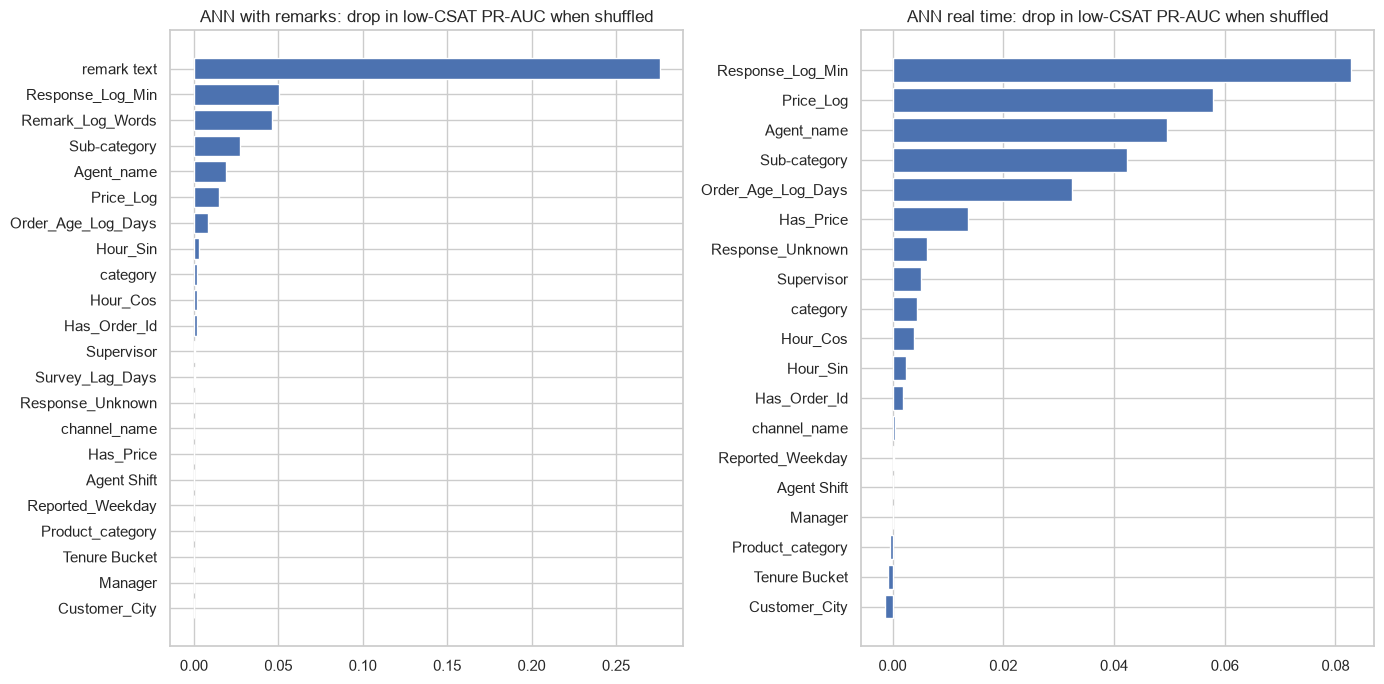

macro F1 drop  low-CSAT PR-AUC drop
             feature                                                
with remarks remark text                0.0413                0.2759
             Response_Log_Min           0.0105                0.0504
             Remark_Log_Words           0.0100                0.0466
             Sub-category               0.0039                0.0275
             Agent_name                 0.0009                0.0193
             Price_Log                  0.0037                0.0147
             Order_Age_Log_Days         0.0025                0.0081
             Hour_Sin                  -0.0003                0.0031
real time    Response_Log_Min           0.0118                0.0827
             Price_Log                  0.0109                0.0578
             Agent_name                 0.0105                0.0496
             Sub-category               0.0047                0.0423
             Order_Age_Log_Days         0.0089                0.0324
             Has_Price                 -0.0142                0.0136
             Response_Unknown          -0.0016                0.0061
             Supervisor                 0.0007                0.0051

In [65]:
# permutation importance: shuffle one input at a time in the test rows and measure how much worse the model gets
def permutation_importance(model, part, y_true, num_cols, with_text, repeats=2):
    base_x = model_inputs(part, num_cols, with_text, tensors=False)          # plain arrays, so they can be shuffled
    base = evaluate("base", y_true, model.predict(to_tensors(base_x), batch_size=4096, verbose=0))
    rng = np.random.default_rng(SEED)
    groups = {c: (INPUT_NAMES[c], None) for c in CAT_COLS}
    groups.update({c: ("numeric", i) for i, c in enumerate(num_cols)})
    if with_text:
        groups["remark text"] = ("remark", None)
    rows = []
    for feature, (key, col) in groups.items():
        drops = []
        for _ in range(repeats):
            x = {k: v.copy() for k, v in base_x.items()}
            order = rng.permutation(len(part))
            if col is None:
                x[key] = x[key][order]
            else:
                x[key][:, col] = x[key][order, col]
            m = evaluate(feature, y_true, model.predict(to_tensors(x), batch_size=4096, verbose=0))
            drops.append((base["macro F1"] - m["macro F1"], base["low-CSAT PR-AUC"] - m["low-CSAT PR-AUC"]))
        rows.append({"feature": feature, "macro F1 drop": np.mean([d[0] for d in drops]),
                     "low-CSAT PR-AUC drop": np.mean([d[1] for d in drops])})
    return pd.DataFrame(rows).set_index("feature").sort_values("low-CSAT PR-AUC drop")


imp_rm = permutation_importance(ann_rm, f_test, y_test, NUM_SURVEY, True)
imp_rt = permutation_importance(ann_rt, f_test, y_test, NUM_REALTIME, False)
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, imp, title in [(axes[0], imp_rm, "ANN with remarks"), (axes[1], imp_rt, "ANN real time")]:
    ax.barh(imp.index, imp["low-CSAT PR-AUC drop"], color="#4C72B0")
    ax.set_title(f"{title}: drop in low-CSAT PR-AUC when shuffled")
fig.tight_layout()
save_fig(fig, "permutation_importance")
plt.show()
pd.concat([imp_rm.sort_values("low-CSAT PR-AUC drop", ascending=False).head(8),
           imp_rt.sort_values("low-CSAT PR-AUC drop", ascending=False).head(8)], keys=["with remarks", "real time"]).round(4)

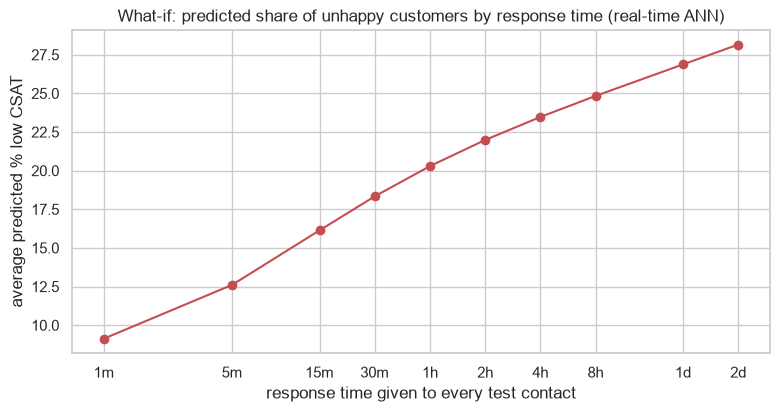

,response minutes,P(low CSAT) real time,expected score
0,1,0.091,4.475
1,5,0.126,4.316
2,15,0.161,4.161
3,30,0.183,4.066
4,60,0.203,3.984
5,120,0.220,3.914
6,240,0.235,3.853
7,480,0.248,3.799
8,1440,0.269,3.717
9,2880,0.282,3.667


In [66]:
# what-if: the same contacts with a different response time, average predicted chance of a low score
what_if = []
for minutes in [1, 5, 15, 30, 60, 120, 240, 480, 1440, 2880]:
    part = f_test.copy()
    part["Response_Log_Min"], part["Response_Unknown"] = np.log1p(minutes), 0
    p_rt = predict(ann_rt, part, NUM_REALTIME, False)
    what_if.append({"response minutes": minutes, "P(low CSAT) real time": p_rt[:, :2].sum(1).mean(),
                    "expected score": (p_rt * LABELS).sum(1).mean()})
what_if = pd.DataFrame(what_if)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(what_if["response minutes"], what_if["P(low CSAT) real time"] * 100, marker="o", color="#C44E52")
ax.set_xscale("log")
ax.set_xticks(what_if["response minutes"])
ax.set_xticklabels(["1m", "5m", "15m", "30m", "1h", "2h", "4h", "8h", "1d", "2d"])
ax.set_ylabel("average predicted % low CSAT")
ax.set_xlabel("response time given to every test contact")
ax.set_title("What-if: predicted share of unhappy customers by response time (real-time ANN)")
save_fig(fig, "what_if_response_time")
plt.show()
what_if.round(3)

I used two model-agnostic explainability tools on the test rows, because a neural network has no simple coefficients.

**Permutation importance**: one input at a time is shuffled, and the drop in the low-CSAT PR-AUC shows how much the model relies on it.
- With remarks: the remark text is by far the most important (PR-AUC drops by 0.276 when it is shuffled), then the response time (0.050), the remark length (0.047), the sub-category (0.028), the agent (0.019) and the price (0.015).
- Real time: the response time (0.083), the price (0.058), the agent (0.050), the sub-category (0.042) and the order age (0.032). The channel, shift, tenure, weekday and hour add almost nothing once these are known.

**What-if analysis**: I gave every test contact the same response time and averaged the predicted chance of a low score. It rises steadily with the wait: 9.1% at 1 minute, 12.6% at 5 minutes, 20.3% at 1 hour, 26.9% at 1 day and 28.2% at 2 days, and the expected score falls from 4.48 to 3.67. Answering within 5 minutes instead of after an hour lowers the predicted share of unhappy customers by about 8 points.

Together this gives a logic a support manager can check: the model looks at what the customer wrote, how long they waited, what the issue was, who handled it and how expensive the order was.

## ***7.1 Insights from the model's predictions***

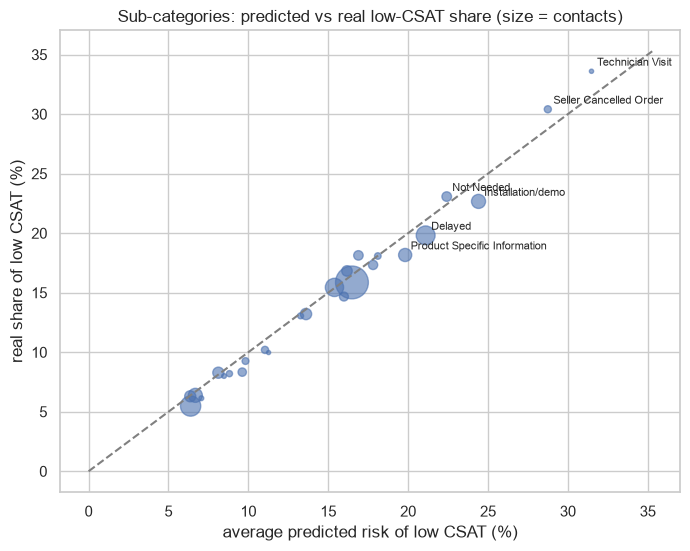

riskiest supervisors:
                                contacts  actual_low  predicted_risk
Manager         Supervisor                                          
William Kim     Lily Chen             56       0.286           0.331
John Smith      Oliver Nguyen        417       0.331           0.307
Jennifer Nguyen Dylan Kim            172       0.297           0.297
                Noah Patel            80       0.275           0.275
                Austin Johnson        25       0.280           0.265


contacts  actual_low  \
category        Sub-category                                         
Returns         Technician Visit                   378       0.336   
Order Related   Seller Cancelled Order            1059       0.304   
                Installation/demo                 4116       0.227   
Cancellation    Not Needed                        1920       0.231   
Order Related   Delayed                           7388       0.198   
Product Queries Product Specific Information      3589       0.182   
Returns         Exchange / Replacement             896       0.181   
Refund Related  Refund Related Issues             1800       0.173   

                                              predicted_risk  alerts  
category        Sub-category                                          
Returns         Technician Visit                       0.315   0.720  
Order Related   Seller Cancelled Order                 0.287   0.731  
                Installation/demo                      0.244   0.605  
Cancellation    Not Needed                             0.224   0.517  
Order Related   Delayed                                0.211   0.472  
Product Queries Product Specific Information           0.198   0.482  
Returns         Exchange / Replacement                 0.181   0.376  
Refund Related  Refund Related Issues                  0.178   0.359

In [67]:
# where does the model expect unhappy customers? predicted low-CSAT risk by group (real-time model, all rows)
all_proba_rt = predict(ann_rt, df, NUM_REALTIME, False)
df["Predicted_Low_Risk"] = all_proba_rt[:, :2].sum(1)
df["Alert"] = (df["Predicted_Low_Risk"] >= THRESHOLD_RT).astype(int)
risk_sub = (df.groupby(["category", "Sub-category"]).agg(contacts=("CSAT", "size"), actual_low=("Low_CSAT", "mean"),
                                                          predicted_risk=("Predicted_Low_Risk", "mean"), alerts=("Alert", "mean"))
            .query("contacts >= 300").sort_values("predicted_risk", ascending=False))
risk_sup = (df.groupby(["Manager", "Supervisor"]).agg(contacts=("CSAT", "size"), actual_low=("Low_CSAT", "mean"),
                                                      predicted_risk=("Predicted_Low_Risk", "mean"))
            .sort_values("predicted_risk", ascending=False))
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(risk_sub["predicted_risk"] * 100, risk_sub["actual_low"] * 100, s=risk_sub["contacts"] / 40, alpha=0.6, color="#4C72B0")
for (c, s), r in risk_sub.head(6).iterrows():
    ax.annotate(s, (r["predicted_risk"] * 100, r["actual_low"] * 100), fontsize=8, xytext=(4, 4), textcoords="offset points")
lim = max(risk_sub["predicted_risk"].max(), risk_sub["actual_low"].max()) * 105
ax.plot([0, lim], [0, lim], color="grey", ls="--")
ax.set_xlabel("average predicted risk of low CSAT (%)")
ax.set_ylabel("real share of low CSAT (%)")
ax.set_title("Sub-categories: predicted vs real low-CSAT share (size = contacts)")
save_fig(fig, "insight_subcategory_risk")
plt.show()
risk_sub.to_csv("outputs/risk_by_subcategory.csv")
risk_sup.to_csv("outputs/risk_by_supervisor.csv")
print("riskiest supervisors:")
print(risk_sup.head(5).round(3).to_string())
risk_sub.head(8).round(3)

What the predictions say about customer satisfaction (the tables are saved in `outputs/risk_by_subcategory.csv` and `outputs/risk_by_supervisor.csv`):
- **Process failures drive unhappiness more than agents do.** The sub-categories with the highest predicted risk are Technician Visit (31.5% predicted, 33.6% real), Seller Cancelled Order (28.7% and 30.4%), Installation/demo (24.4% and 22.7%), Not Needed cancellations (22.4% and 23.1%) and Delayed orders (21.1% and 19.8%). The predicted risk follows the real share closely, so the model has learned the real pattern. For Technician Visit and Seller Cancelled Order more than 70% of the contacts would get an alert.
- **Response time is the main lever the team controls.** The what-if curve shows the predicted share of unhappy customers going from 12.6% at 5 minutes to 20.3% at 1 hour and 26.9% at a day.
- **Some teams need support.** The supervisors with the highest predicted risk are Oliver Nguyen (417 contacts, 33.1% real low scores), Dylan Kim (29.7%) and Lily Chen (28.6%), against 14.6% overall.
- **Expensive orders, email and agents in training** are the other risk factors, as the charts showed.

Service improvement opportunities:
1. Set response time targets of 5 minutes for phone and a few hours for email, and push the oldest open contacts to the front of the queue.
2. Fix the processes behind the risky sub-categories: technician visit scheduling, seller cancellations and installation bookings.
3. Use the real-time alert for a supervisor call-back before the survey, starting with high-value orders.
4. Coach the teams with the highest risk, and give new agents in training easier queues or quick escalation.
5. Read the remarks of the alerted contacts every week to find new problems early.

## ***7.2 Local deployment (Streamlit app)***

The two saved models run in a local web app built with Streamlit (`app/app.py` in the repository). It imports the same `csat_features.py` that this notebook writes, so a contact in the app goes through exactly the same preparation as in training, and the saved Keras models contain their own lookups, text vocabulary and scaling.

How to run it from the repository folder:
```bash
python3 -m venv .venv
source .venv/bin/activate
pip install -r requirements.txt
streamlit run app/app.py
```
The app opens at http://localhost:8501 and has three tabs:
1. **Predict one contact**: a form with the channel, issue, response time, agent, order and an optional remark. It shows the most likely score, the expected score, the chance of a low score and the alert. Without a remark it uses the real-time model, with a remark the remarks model. It also shows a what-if: the chance of a low score if the contact had been answered within 5 minutes.
2. **Score a file**: upload a csv in the Shopzilla export format (for example `outputs/sample_new_contacts.csv`, 200 test contacts) and get a prediction and alert for every row, sorted by risk, with a download button. This is how a team lead could check the day's contacts every evening.
3. **Insights**: the main charts and the risk tables by sub-category and supervisor from section 7.1.

For ongoing use, the same script could run every hour on the new contacts and send the alert list to the supervisors, and the model would be retrained each month on the latest surveys.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [68]:
# Save the File
ann_rt.save("models/csat_ann_realtime.keras")
ann_rm.save("models/csat_ann_with_remarks.keras")
training_rows = df.iloc[train_idx]
metadata = {
    "classes": LABELS.tolist(),
    "models": {"realtime": {"file": "csat_ann_realtime.keras", "num_cols": NUM_REALTIME, "with_text": False,
                            "alert_threshold": THRESHOLD_RT, "config": {k: str(v) for k, v in CFG_RT.items()}},
               "with_remarks": {"file": "csat_ann_with_remarks.keras", "num_cols": NUM_SURVEY, "with_text": True,
                                "alert_threshold": THRESHOLD_RM, "config": {k: str(v) for k, v in CFG_RM.items()}}},
    "test_scores": {r["model"]: {k: round(float(v), 4) for k, v in r.items() if k != "model"} for r in results_3},
    "options": {c: sorted(training_rows[c].unique().tolist()) for c in CAT_COLS if c not in ("Customer_City", "Agent_name")},
    "cities": vocabulary(training_rows["Customer_City"], MIN_CITY_COUNT),
    "subcategories": {k: sorted(v.unique().tolist()) for k, v in training_rows.groupby("category")["Sub-category"]},
    "agents": training_rows.groupby("Agent_name")[["Supervisor", "Manager"]].agg(lambda s: s.mode()[0]).to_dict("index"),
}
with open("models/csat_metadata.json", "w") as fh:
    json.dump(metadata, fh, indent=1)
# a few raw rows the models never saw in training, without the score, to try the app's file upload
raw.iloc[test_idx].drop(columns="CSAT Score").sample(200, random_state=SEED).to_csv("outputs/sample_new_contacts.csv", index=False)
for fname in sorted(os.listdir("models")):
    print(f"models/{fname}: {os.path.getsize(f'models/{fname}') / 1e6:.2f} MB")

models/csat_ann_realtime.keras: 1.54 MB
models/csat_ann_with_remarks.keras: 2.47 MB
models/csat_metadata.json: 0.13 MB


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [69]:
# Load the File and predict unseen data.
# the full deployment path: raw rows -> csat_features.make_features -> saved model, exactly as the app does it
meta = json.load(open("models/csat_metadata.json"))
loaded = {k: keras.models.load_model(f"models/{v['file']}") for k, v in meta["models"].items()}
new_rows = pd.read_csv("outputs/sample_new_contacts.csv")
new_feat = make_features(new_rows)
out = new_rows[["Unique id", "channel_name", "category", "Sub-category", "Customer Remarks"]].copy()
for k, v in meta["models"].items():
    p = loaded[k].predict(model_inputs(new_feat, v["num_cols"], v["with_text"]), batch_size=4096, verbose=0)
    out[f"{k}: predicted score"] = p.argmax(1) + 1
    out[f"{k}: P(low CSAT)"] = p[:, :2].sum(1).round(3)
    out[f"{k}: alert"] = p[:, :2].sum(1) >= v["alert_threshold"]

# sanity check: the reloaded model gives the same probabilities as the model in memory
same = np.allclose(loaded["with_remarks"].predict(model_inputs(f_test.head(500), NUM_SURVEY, True), verbose=0),
                   predict(ann_rm, f_test.head(500), NUM_SURVEY, True), atol=1e-5)
print("reloaded model gives the same predictions:", same)
real = raw.set_index("Unique id").loc[out["Unique id"], "CSAT Score"].to_numpy()
print(f"on these 200 rows the real share of low CSAT is {np.mean(real <= 2):.1%}; the real-time model alerts on "
      f"{out['realtime: alert'].mean():.1%} and the remarks model on {out['with_remarks: alert'].mean():.1%}")
out.head(10)

reloaded model gives the same predictions: True
on these 200 rows the real share of low CSAT is 12.5%; the real-time model alerts on 30.0% and the remarks model on 13.0%


,Unique id,channel_name,category,Sub-category,Customer Remarks,realtime: predicted score,realtime: P(low CSAT),realtime: alert,with_remarks: predicted score,with_remarks: P(low CSAT),with_remarks: alert
0,4f6c0ec0-6f93-4bb7-b2e8-45495e78cd26,Inbound,Returns,Return request,NaN,5,0.177,False,5,0.148,False
1,bb355601-0112-41ba-ac37-e9b55f4b4836,Inbound,Returns,Reverse Pickup Enquiry,NaN,1,0.438,True,1,0.406,True
2,a331e978-c5a4-4ac9-bd30-296d8fb164fd,Inbound,Order Related,Delayed,NaN,5,0.244,True,5,0.232,False
3,b58a8c28-4862-44b9-8d61-a31d60265135,Inbound,Refund Related,Refund Enquiry,NaN,5,0.108,False,5,0.160,False
4,605984bb-a8fa-4b22-81ca-86b92ec60032,Outcall,Order Related,Priority delivery,Nice,5,0.061,False,5,0.047,False
5,35690c70-2870-4e47-85b1-be825c3313f8,Inbound,Returns,Reverse Pickup Enquiry,Thanks,5,0.102,False,5,0.033,False
6,d2632688-110b-4b8d-a039-f1fe6adec257,Inbound,Returns,Missing,NaN,5,0.022,False,5,0.042,False
7,b6834041-2120-4401-9c99-78adb52aeab4,Outcall,Returns,Service Centres Related,NaN,5,0.409,True,1,0.419,True
8,a7cfc664-8a6e-4376-9cab-bab44ddca85f,Inbound,Returns,Reverse Pickup Enquiry,NaN,5,0.125,False,5,0.128,False
9,323eef07-b95f-4200-90c9-761606f0e3ba,Inbound,Offers & Cashback,Other Cashback,Take hard action against the seller regarding ...,5,0.021,False,5,0.189,False


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

I built a full pipeline that predicts the CSAT score of a support contact with a neural network and turns it into an early warning for unhappy customers. The main findings:

1. **Time matters most.** The share of unhappy customers grows from 8.9% when the answer comes within 5 minutes to 36.1% after a day, and the model's what-if curve confirms it. Fast first responses are the cheapest way to raise CSAT.
2. **Unhappiness comes mostly from process failures.** Technician visits, seller cancellations, installations and delayed orders have 20-34% low scores, and expensive orders and email contacts are also riskier. Agents and teams matter too: supervisors range from 10% to 33% low scores.
3. **The real-time ANN can act before the survey.** With a ROC-AUC of 0.725 it flags 29% of the contacts and catches 57% of the unhappy customers, which is enough for targeted call-backs. The agent and city embeddings make it better than a linear model on the same inputs.
4. **The remark is the strongest signal.** With it, the ANN reaches a ROC-AUC of 0.808 and half of its alerts are right. A well-built logistic regression does as well here, which taught me to always compare with a strong baseline.
5. **The middle scores can't be predicted** from this data. 2, 3 and 4 look like 5s, so the model is a tool for finding unhappy customers and ranking risk, not for telling a 4 from a 5.

What I learned: data quality checks pay off (the midnight reply times would have taught the model that a negative wait means a happy customer), and features that only exist after the outcome (the remark) have to be kept out of a real-time model. On imbalanced data the right metric matters more than the algorithm, and a model is only useful if it is deployed with exactly the same preprocessing it was trained with.

Next steps: pre-trained multilingual text embeddings for the Hinglish remarks, more months of data so the rare scores have more examples, a data-quality check before scoring, and a scheduled job that scores new contacts every hour and is retrained every month.

The notebook, the data, the saved models, the Streamlit app and all charts are in the GitHub repository.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***